# Generalizing with Neural Networks

Tabular reinforcement learning represents value functions with one entry for each state or state-action pair. This is effective in small environments, but it quickly becomes impractical when the state space is large, continuous, or high-dimensional. In these settings, the agent must do more than memorize values: it must **generalize** from the states it has experienced to states it has never seen before. Neural networks provide a flexible way to achieve this. Instead of storing values in a table, **we use a neural network to approximate an action-value function**. The network receives a representation of the state, or of a state-action pair, and outputs value estimates that guide the agent’s decisions. The motivation for all of this comes from the nature of reinforcement learning itself. In reinforcement learning, agents learn from feedback that is simultaneously **evaluative, delayed, and sampled**.

**Delayed feedback**: imagine a chess game in which you make several poor moves early on, but their consequences become apparent only at the end of the game. This kind of feedback makes it difficult to identify where the final outcome actually comes from, and gives rise to the **temporal credit assignment problem**: the challenge of determining which state, action, or state-action pair is responsible for a given reward. Its opposite is **immediate feedback**. In supervised learning, decisions do not have long-term consequences. For example, in an image classification task, classifying an image correctly or incorrectly does not affect the model’s future performance.

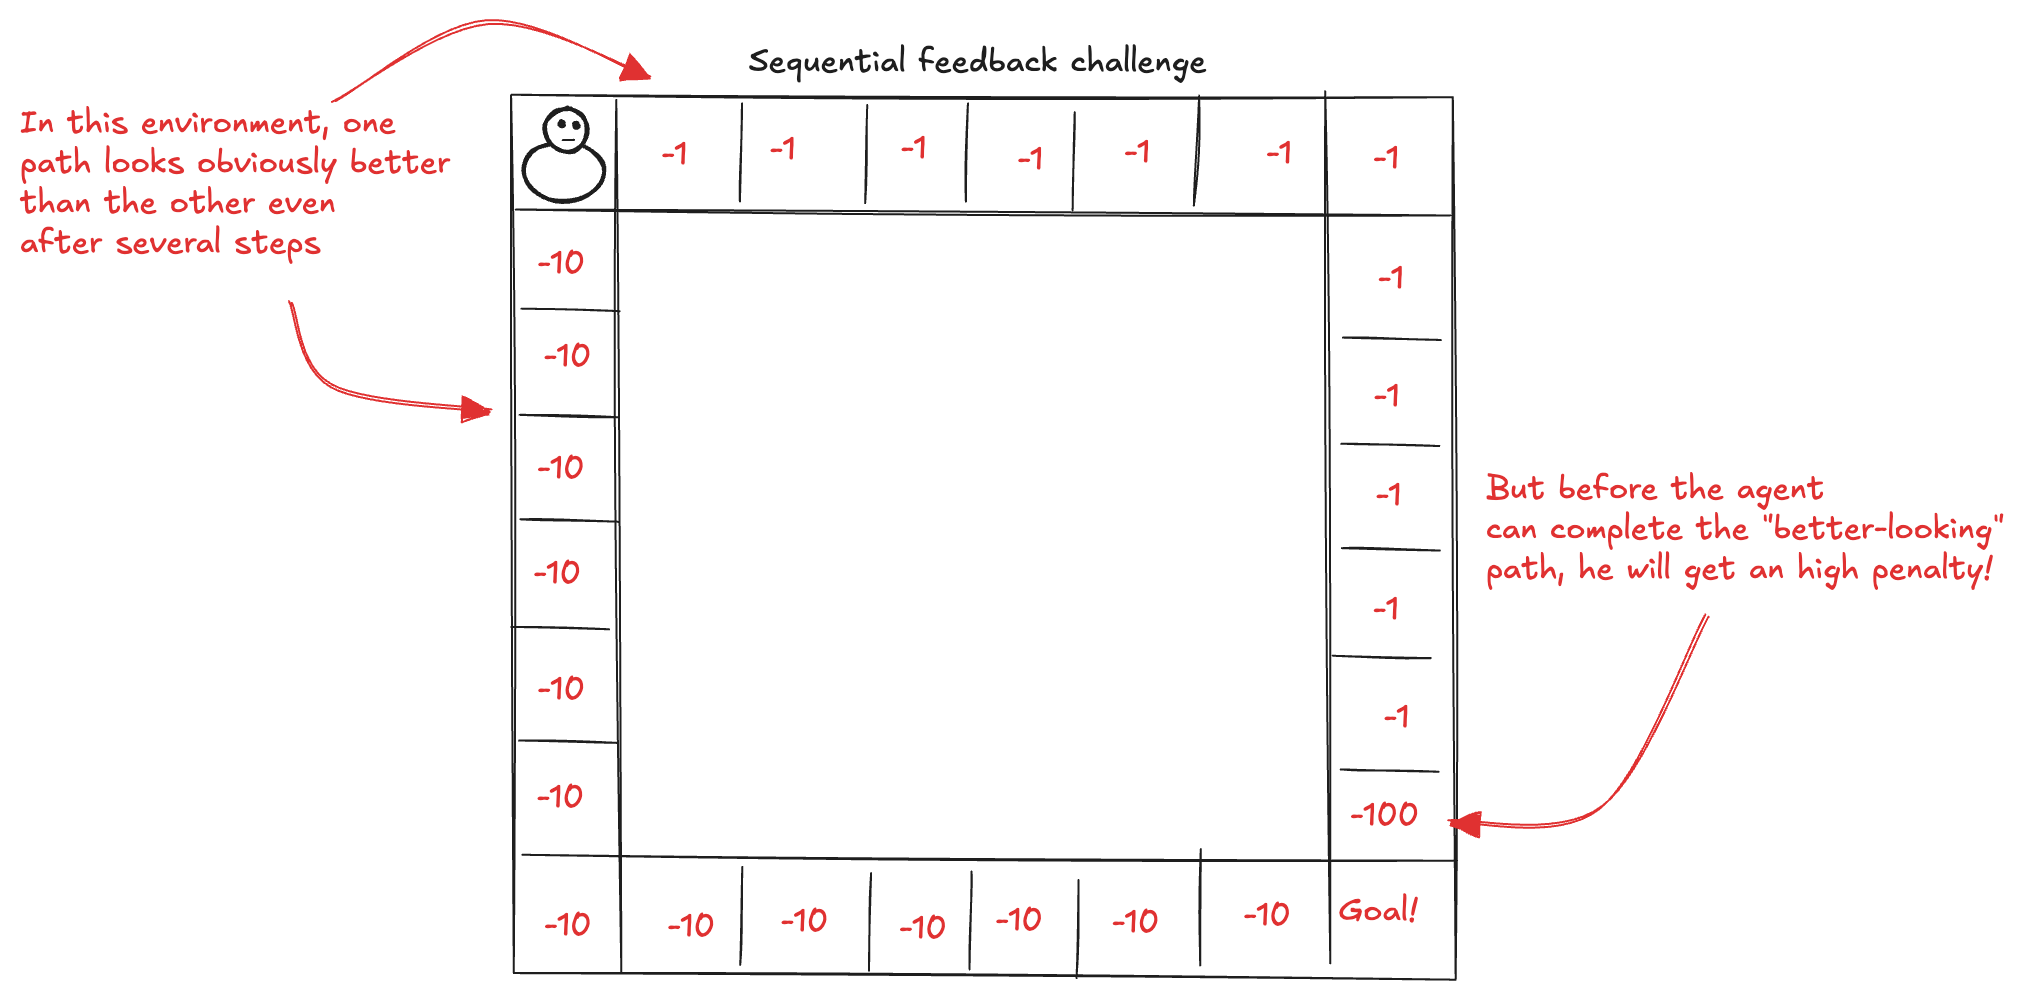

**Evaluative feedback**: feedback in reinforcement learning is only relative, because the environment is uncertain and the agent does not know its true dynamics. In particular, the agent has no direct access to the transition function or the reward function. As a result, it must learn by interacting with the environment and exploring different actions.
The difficulty is that exploration comes at a cost: while the agent is trying new actions to gain information, it may miss opportunities to exploit what it already knows. This tension is known as the **exploration-exploitation trade-off**. The opposite is **supervised feedback**. In a classification problem, for example, the model is given the correct label for each training sample. It does not need to discover the right answer through trial and error.

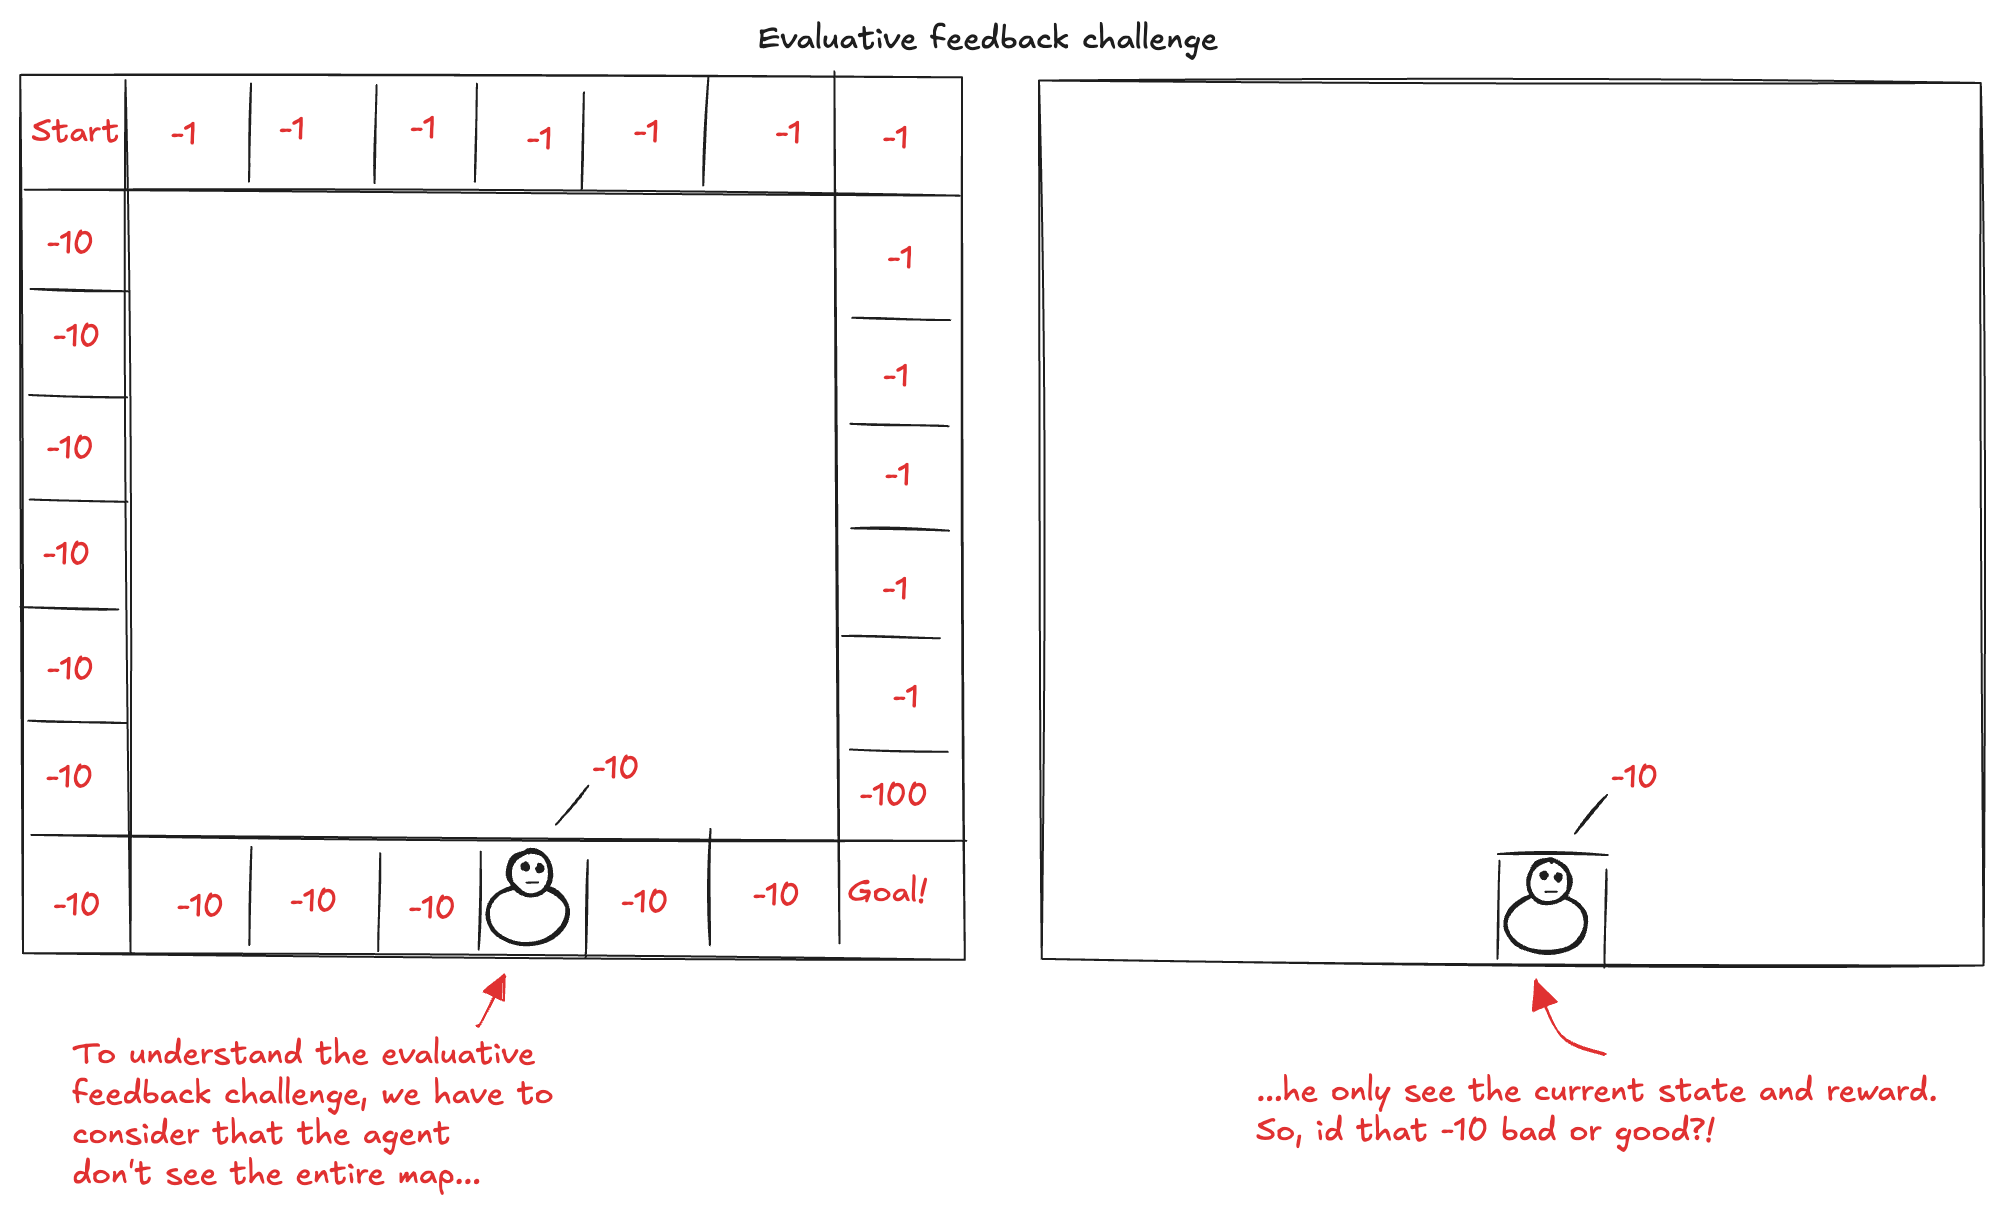

**Sampled feedback**: in real-world problems, agents are unlikely to observe every possible situation or receive feedback for every possible state-action pair. Instead, they must learn from a limited set of sampled experiences and generalize from them in order to make intelligent decisions in new situations. The opposite is exhaustive feedback, where the agent has access to all possible samples. In tabular reinforcement learning, this assumption can be reasonable in small environments with finite state and action spaces. If the agent samples long enough, it can eventually gather the information it needs, and many tabular methods come with convergence guarantees under assumptions such as "every state-action pair is sampled infinitely often". These assumptions may hold in small grid worlds, but they break down in realistic environments. Consider, for example, an agent playing a video game:

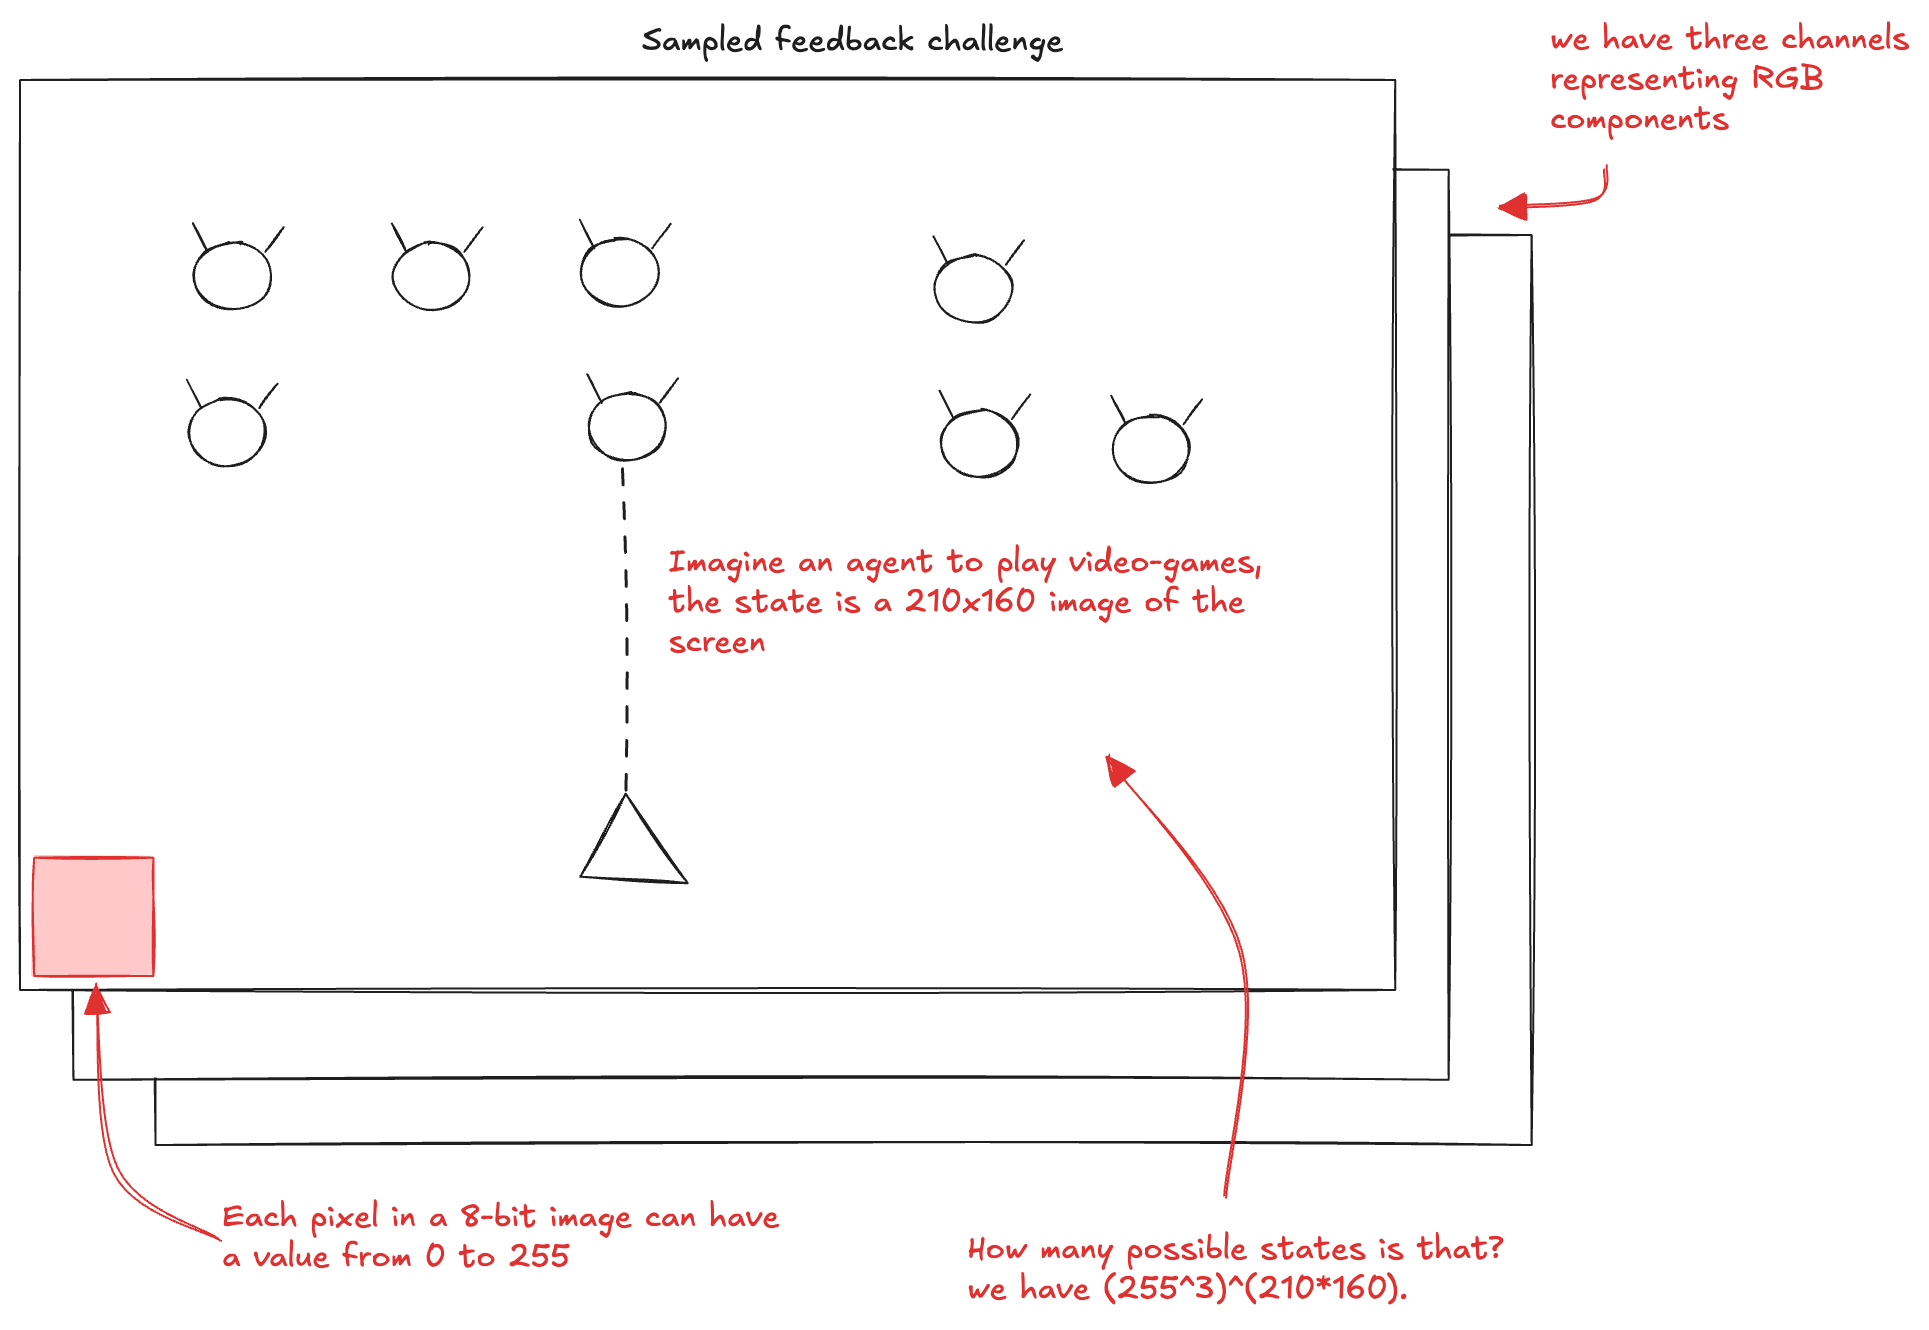

The number of possible states in a video game is enormous. This exposes the limitations of traditional tabular reinforcement learning and motivates the use of **learning methods** that can handle high-dimensional state spaces and learn effective policies from limited experience.

## The Need for Generalization

The main limitation of the methods we have seen so far is that they represent value functions using tables. For this reason, they are known as **tabular reinforcement learning** methods. This representation works well in small environments with a limited number of states and actions, but it quickly becomes impractical in complex problems. For example, Q-learning estimates the optimal action-value function using a table, or matrix, indexed by states and actions:

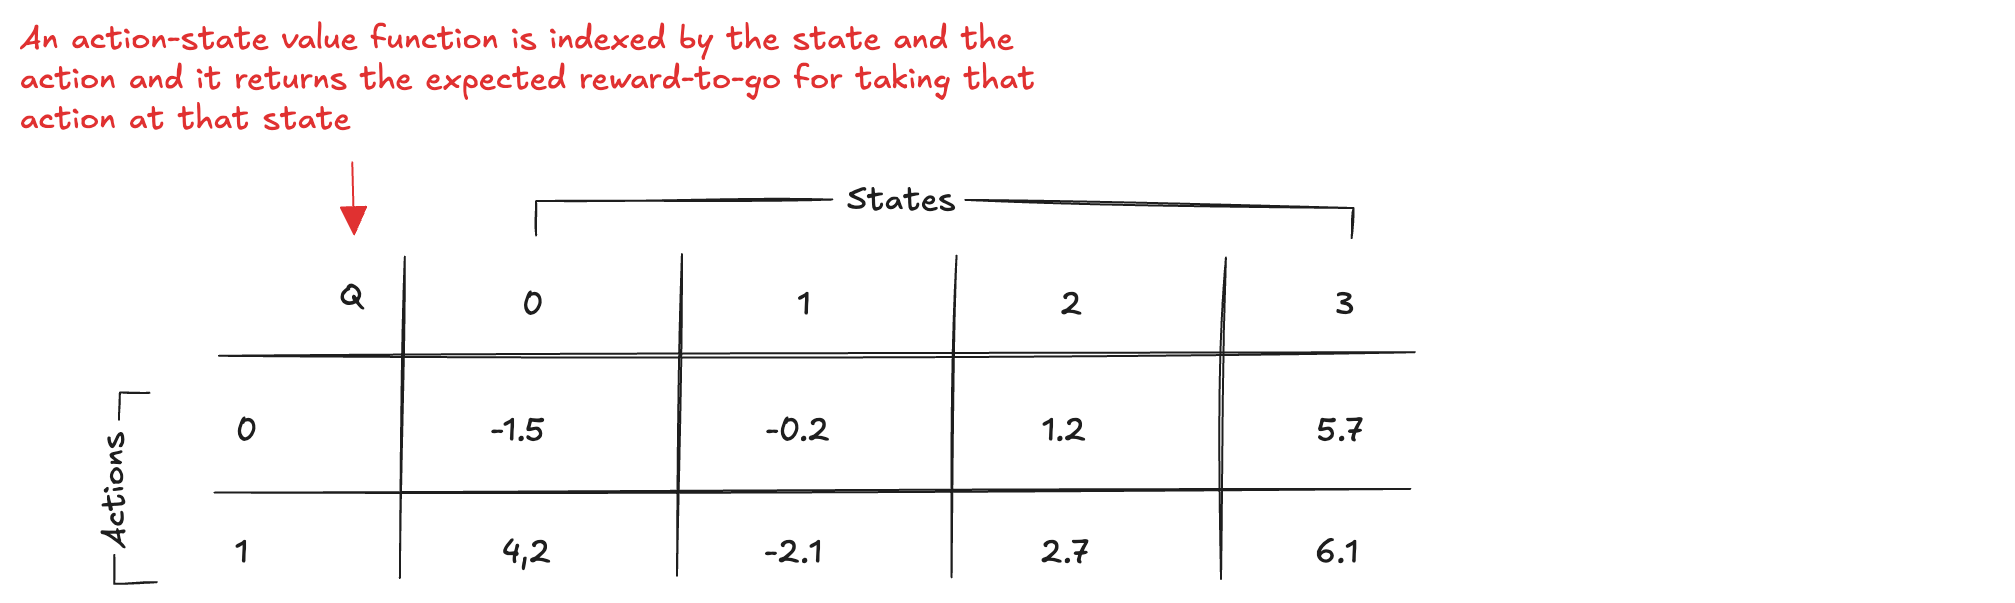

In many tasks where we would like to apply reinforcement learning, the **state space is combinatorial and enormous**. Environments may have **high-dimensional state spaces**, where each state is described by a large number of variables, or they may include **continuous variables**, where even a single variable can take infinitely many values.

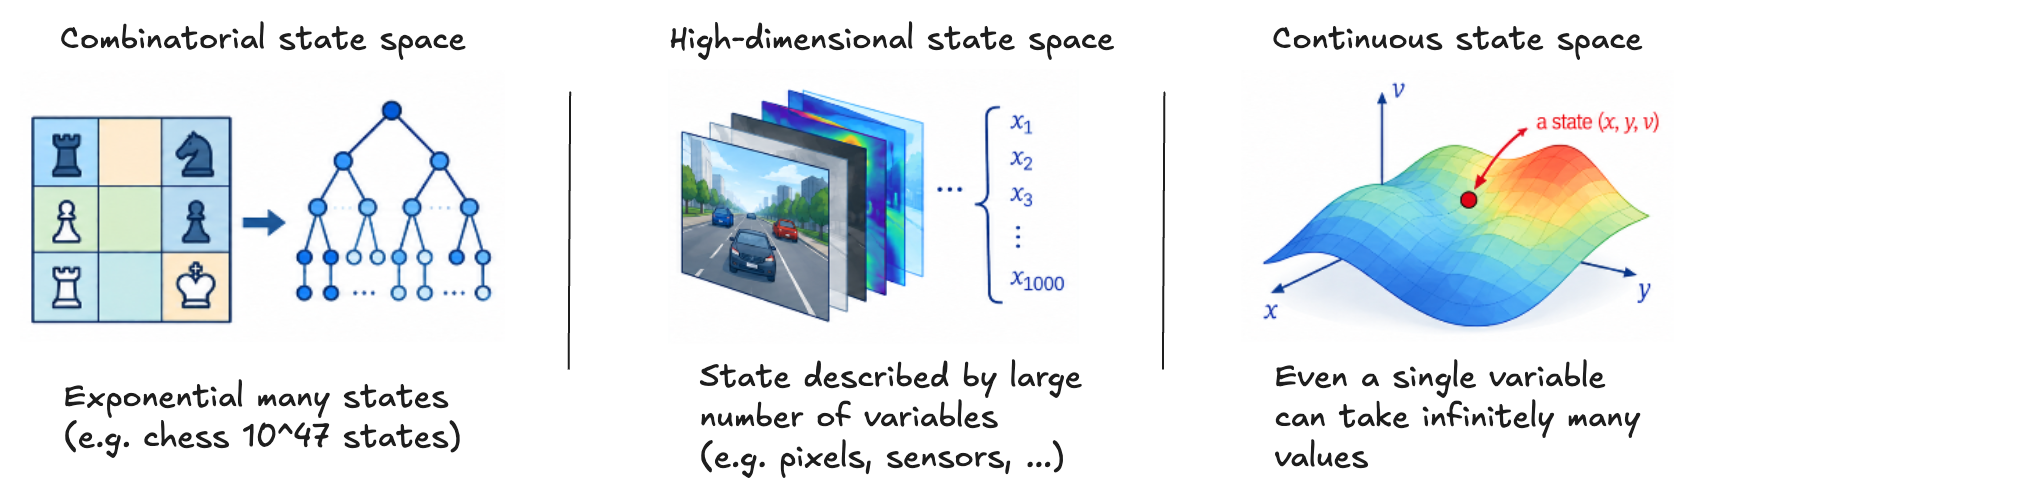

This immediately raises a practical question: how could we build a table that accounts for all of these possibilities? One option is to **discretize the state space**, but even then the number of possible values can remain extremely large, making tabular solutions **impractical** because of the size of the required tables. The issue is not only memory. It is also the **time needed to fill those tables accurately**. In many realistic tasks, almost every state the agent encounters will be new. To act sensibly, the agent must therefore **generalize** from previous experience with other states that are, in some relevant sense, similar to the current one. Tabular methods are inefficient precisely because they lack this ability to generalize. They treat states as separate entries, which prevents them from discovering underlying relationships among states. The key question, then, is how experience gathered from a limited subset of the state space can be used to produce a useful approximation over a much larger one. Under these conditions, we should not expect to find truly optimal policies. A more realistic goal is to find **good approximate solutions** using **limited computational resources**.

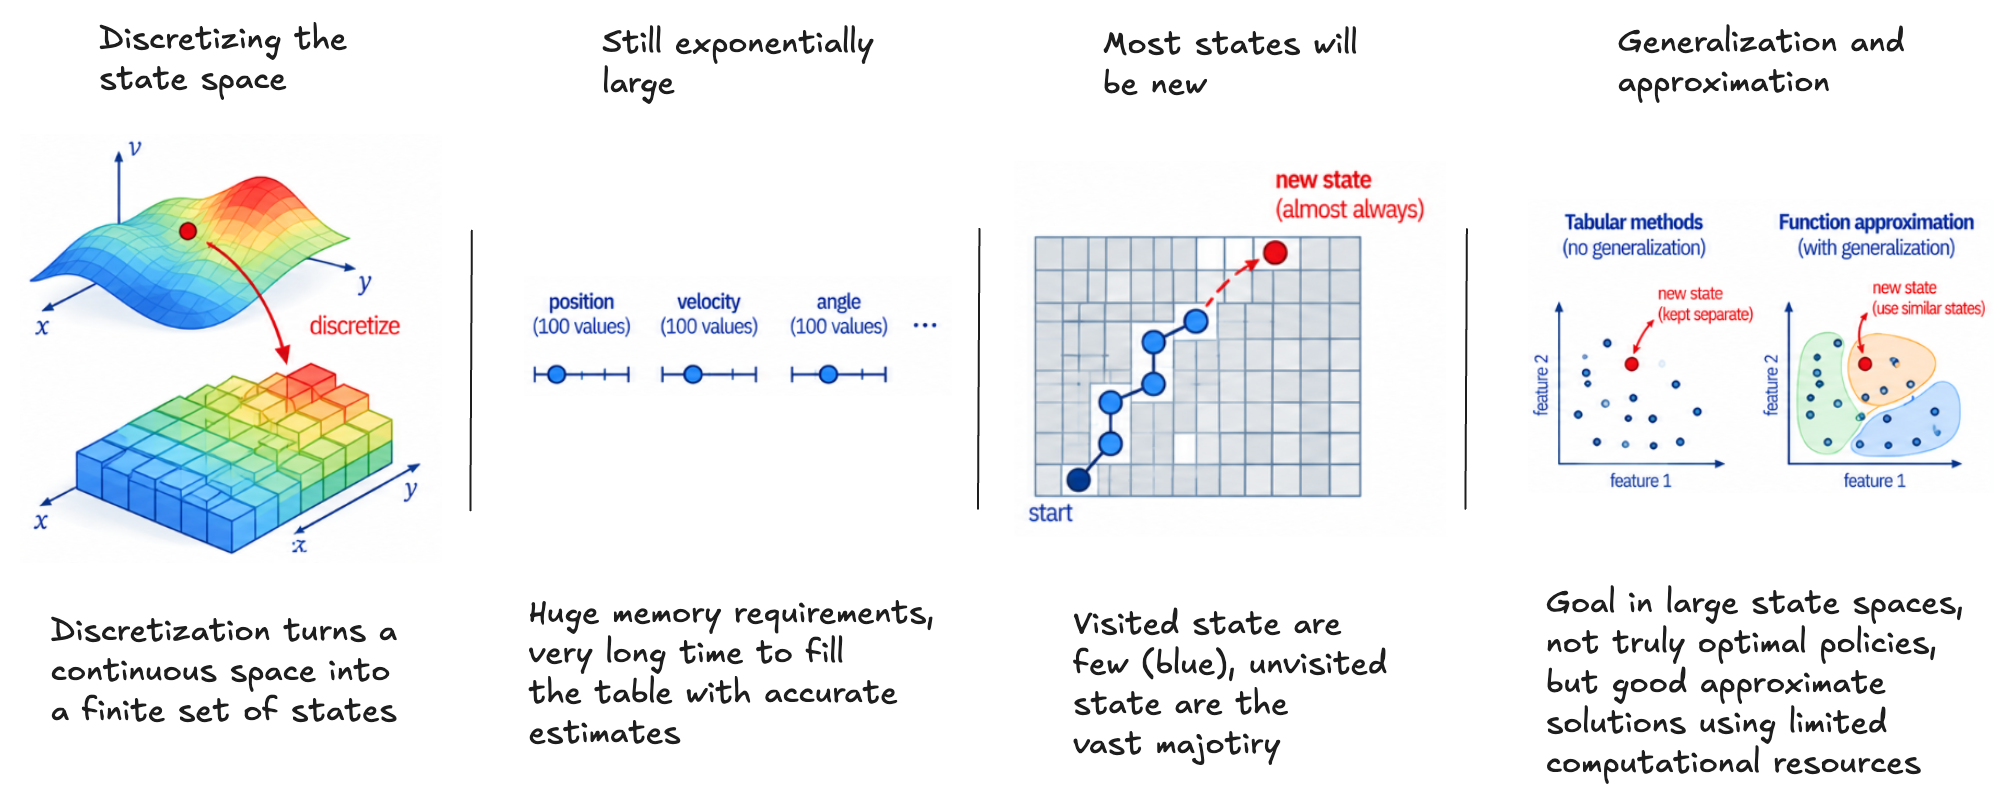

**Generalization from examples** has already been studied extensively, so we do not need to invent entirely new methods for reinforcement learning. Instead, we can combine reinforcement learning algorithms with existing generalization techniques. This kind of generalization is usually called **function approximation**. The idea is to take examples from a target function, such as a value function, and use them to construct an approximation of the full function. In this sense, function approximation is a form of **supervised learning**. In principle, almost any supervised learning method can be used as a function approximator inside a reinforcement learning algorithm, although in practice some methods fit this role more naturally than others.

### From Tables to Parameters

The simplest way to move from a table to a representation that can generalize is to describe each state-action pair using a **feature vector**. Instead of storing a separate value for every possible pair, we compute the value as a weighted combination of features:

$\displaystyle \phi(s,a) \in \mathbb{R}^n$

$\displaystyle Q_\theta(s,a) = \theta^\top \phi(s,a) = \sum_{i=1}^{n} \theta_i \phi_i(s,a)$

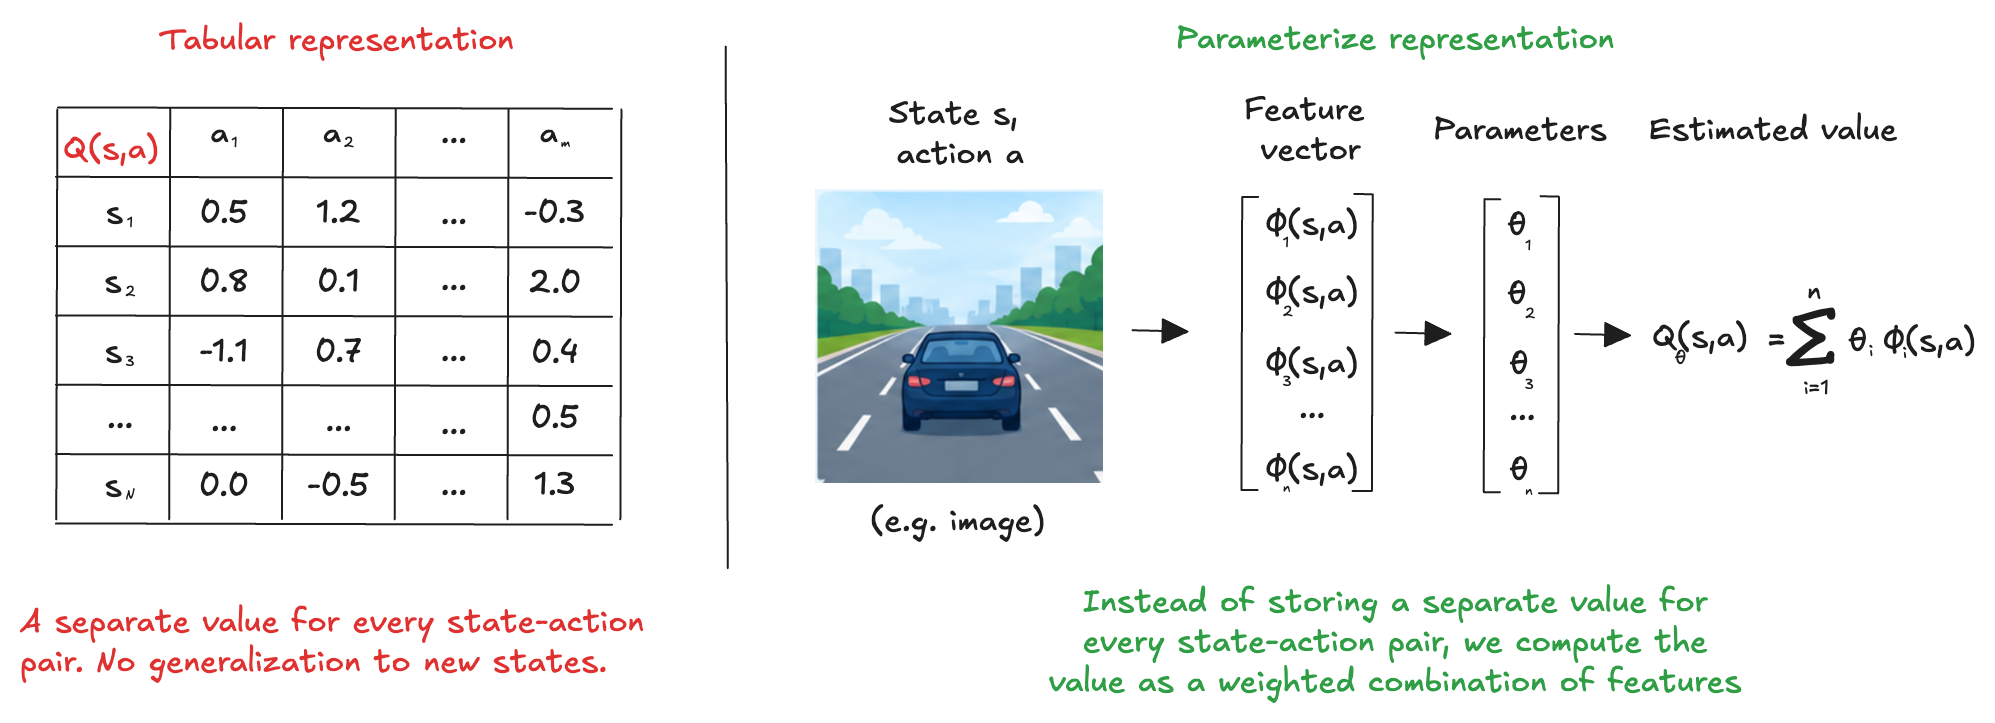

The vector contains the **parameters** of the approximator. From this point on, **learning a value function no longer means filling the cells of a table**. It means **adjusting the parameters of a function approximato**r. Linear function approximation is the natural starting point for this idea for two reasons. First, **a table is a special case**. If the feature vector is a one-hot encoding of a state-action pair, then the weighted sum simply selects the corresponding table entry. In other words, tabular reinforcement learning can be seen as linear function approximation with one independent parameter for every state-action pair:

$\displaystyle n = |\mathcal{S}|\,|\mathcal{A}|$

In this case, there is **no generalization**: updating one state-action pair changes only that entry. The real advantage appears when we use **fewer parameters** than state-action pairs:

$\displaystyle n \ll |\mathcal{S}|\,|\mathcal{A}|$

Now, **different pairs may share features**, and therefore share parameters. An update based on one state-action pair can also affect the estimated value of other pairs with similar features. This is exactly the kind of **generalization** we need, although it will also introduce new difficulties. Second, **the gradient of a linear approximator is especially simple**:

$\displaystyle \nabla_\theta Q(s,a;\theta) = \phi(s,a)$

As a result, the familiar incremental update pattern used throughout the course:

**NewEstimate $\leftarrow$ OldEstimate + StepSize $\times$ (Target - OldEstimate)**

can be reinterpreted in terms of function approximation. In tabular methods, the old estimate is a single table entry. Updating it changes only that one entry. With function approximation, however, the estimate is computed from the parameter vector:

$\displaystyle Q(s,a;\theta)$

So we cannot directly replace one table entry. Instead, we adjust the parameters so that the new value predicted for the current state-action pair moves closer to the target. The prediction error is:

$\displaystyle \text{Target} - Q(s,a;\theta)$

For a linear approximator, the gradient tells us how each parameter affects the current prediction. Since the gradient is simply the feature vector:

$\displaystyle \nabla_\theta Q_\theta(s,a) = \phi(s,a)$

we update the parameters in the direction of that feature vector:

$\displaystyle \theta \leftarrow \theta + \alpha \big[ \text{Target} - Q_\theta(s,a) \big] \phi(s,a)$

In words, the update says: change the parameters in proportion to the prediction error, scaled by the step size, and distribute that change according to the features that were active for the current state-action pair. A neural network is a **non-linear function approximator**. Its features are no longer designed by hand, they are learned by the hidden layers. The output layer then combines those learned features to produce the final value estimate. The update has the same general structure as before, but the gradient is now computed by backpropagation rather than being equal to the feature vector:

$\displaystyle \nabla_\theta Q_\theta(s,a)$

The price we pay for this additional flexibility is that the convergence guarantees available in the linear case no longer generally apply.

### The Cart-Pole Environment

To illustrate why generalization is needed, we will use a classic control problem: **Cart-Pole**. The goal is to balance a pole attached to a cart that moves along a frictionless track. The pole starts upright, and the agent must prevent it from falling by pushing the cart either left or right. Cart-Pole is useful because it is simple enough to train quickly, but still challenging enough to show the limitations of tabular methods. Its state space is low-dimensional, but **continuous**, which means that a table-based representation is already inconvenient and function approximation becomes useful.

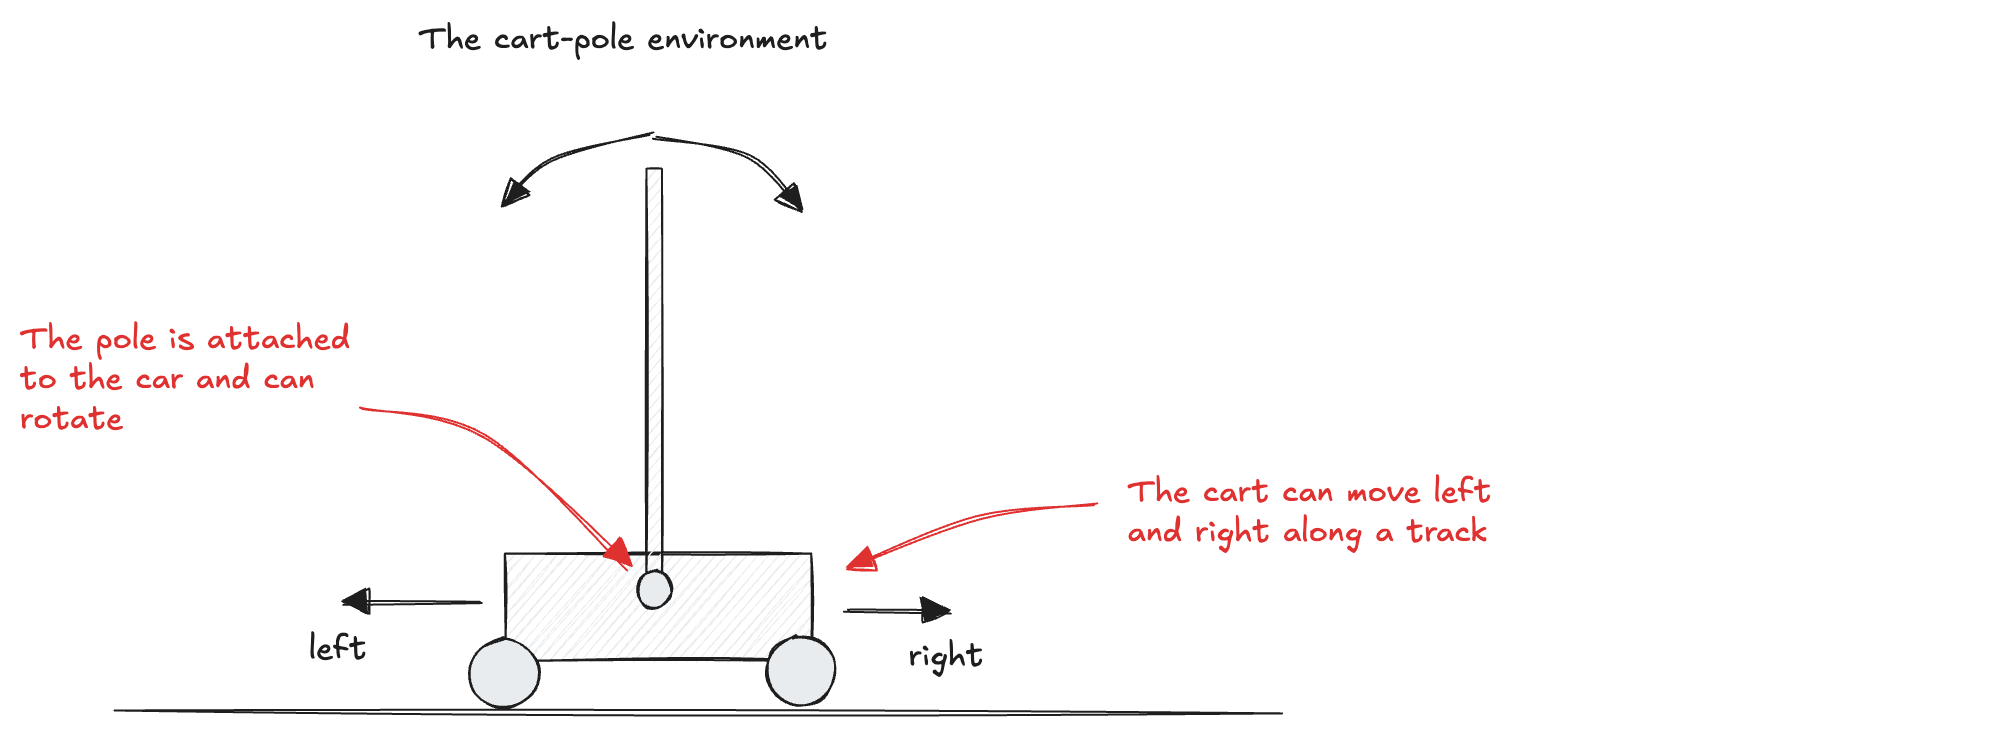

The state is a vector with four continuous variables:

- the cart position on the track
- the cart velocity
- the pole angle with respect to the vertical
- the pole angular velocity

In every state, the agent can choose between two actions:

- action 0 pushes the cart to the left
- action 1 pushes the cart to the right

The force has fixed magnitude, equal to 10 N. The agent only chooses the direction of the force. The reward is +1 at every time step, including the final one. Therefore, the return of an episode is simply its length. The episode terminates when the agent fails(the pole angle exceeds a threshold from the vertical), or if the cart position leaves the horizontal range. Since the reward is +1 per step and episodes are truncated after 500 steps, the maximum return is 500. The environment is conventionally considered solved when the average return exceeds 475. The Cart-Pole environment is available in the Gymnasium library:

In [2]:
import gymnasium

cart_pole = gymnasium.make('CartPole-v1', render_mode="rgb_array");

We can get the state space and the action space sizes of the environment:

In [3]:
print('State Space: ', cart_pole.observation_space.shape);
print('Action Space: ', cart_pole.action_space.n);

State Space:  (4,)
Action Space:  2


We want to be able to reproduce the results, so we will fix the random seed:

In [4]:
import torch
import numpy as np
import random

def seed_environment(env, seed):
    torch.manual_seed(seed)
    env.reset(seed=seed)
    env.action_space.seed(seed)
    env.observation_space.seed(seed)

seed_environment(cart_pole, seed=34)

As a baseline for comparison, we use a **random policy**, which selects actions uniformly at random from the action space. Although this policy does not learn, it provides a useful reference point: it allows us to measure how much a learned policy improves over uninformed behavior.

In [5]:
class RandomPolicy:
    
    def __init__(self, env):
        # Store the environment whose action space we will sample.
        self.env = env

    def select_action(self, state):
        
        # The state is unused, but keeps the same interface as other policies.
        # Select an action uniformly at random.
        return self.env.action_space.sample()

To better understand how the agent interacts with the environment, we define a visualization function that shows the policy in action, step by step. This allows us to observe how the agent’s decisions unfold over the course of an episode.

In [6]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

def show_policy(env, policy, n_episodes=1, max_steps=500):

    # start the episodes    
    for episode in range(n_episodes):

        # reset the environment
        state, _ = env.reset();
        done = False;

        # initialize the step counter
        step = 0;

        # run the episode until done or max_steps
        while not done and step < max_steps:

            # make a step
            action = policy.select_action(state);
            state, _, terminated, truncated, _ = env.step(action);
            done = terminated or truncated;
            
            # render the environment
            clear_output(wait=True)
            plt.imshow(env.render())
            plt.axis("off")
            plt.title(f"Episode {episode+1}, Step {step}")
            plt.show()
            plt.close()

            # increment the step counter
            step += 1;   

When applied to the Cart-Pole environment, the random policy performs very poorly. Since it selects actions uniformly at random, it has no notion of balance or control, and the pole usually falls after only a few time steps. As a result, episodes terminate quickly and produce very low total rewards:

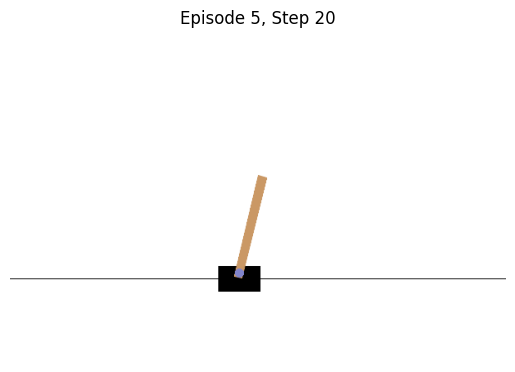

In [7]:
random_policy = RandomPolicy(cart_pole);
show_policy(cart_pole, random_policy, n_episodes=5, max_steps=500);

To **quantitatively assess** a policy on the environment, we define an **evaluation function** that runs the agent for a fixed number of episodes, records the total reward obtained in each one, and returns the average episode reward. This gives us a simple and consistent measure of policy quality, allowing us to compare different strategies under the same conditions:

In [8]:
def evaluate(env, policy, episodes=1):

    # collect total rewards per episode
    rewards = []

    for episode in range(episodes):

        # reset the environment
        state, _ = env.reset()
        done = False
        total_reward = 0.0

        # run one episode
        while not done:
            action = policy.select_action(state)
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            done = terminated or truncated

        rewards.append(total_reward)

    # return the average reward over episodes
    return float(np.mean(rewards))

To establish the numerical baseline, we evaluate the random policy:

In [9]:
random_score = evaluate(cart_pole, random_policy, episodes=1000);
print("Random score", random_score);

Random score 21.921


As expected, the random policy achieves a very low average reward on the Cart-Pole environment, usually failing after only a few time steps. This confirms that keeping the pole balanced requires structured decision-making, and gives us a clear benchmark against which to measure learned policies. We can now try to solve the environment using reinforcement learning. However, **tabular methods are not practical** here. The state space is continuous, so a table-based solution would require discretizing the four state variables into a grid of cells. Most of these cells would rarely, if ever, be visited, making the representation inefficient and unreliable. To solve this problem effectively, we need **function approximation**, so that the agent can generalize from the states it has experienced to similar states it has not seen before.

## Neural Fitted Q (NFQ)

[**Neural Fitted Q**](./papers/2005%20-%20Neural%20Fitted%20Q%20Iteration%20%E2%88%92%20First%20Experiences%20with%20a%20Data%20Efficient%20Neural%20Reinforcement%20Learning%20Method.pdf) was one of the first reinforcement learning algorithms to successfully use **neural networks as function approximators**. As in the linear case, we denote the approximate action-value function by:

$\displaystyle Q_\theta(s,a)$

Here, $\displaystyle \theta$ denotes the weights of the neural network.

### Network Architecture

To design the function approximator, we can start from the tabular representation. In a table, the action-value function is indexed by state-action pairs. A direct neural-network analogue is therefore to provide both the state and the action as input, and to output a single scalar value: the estimated value of that state-action pair.

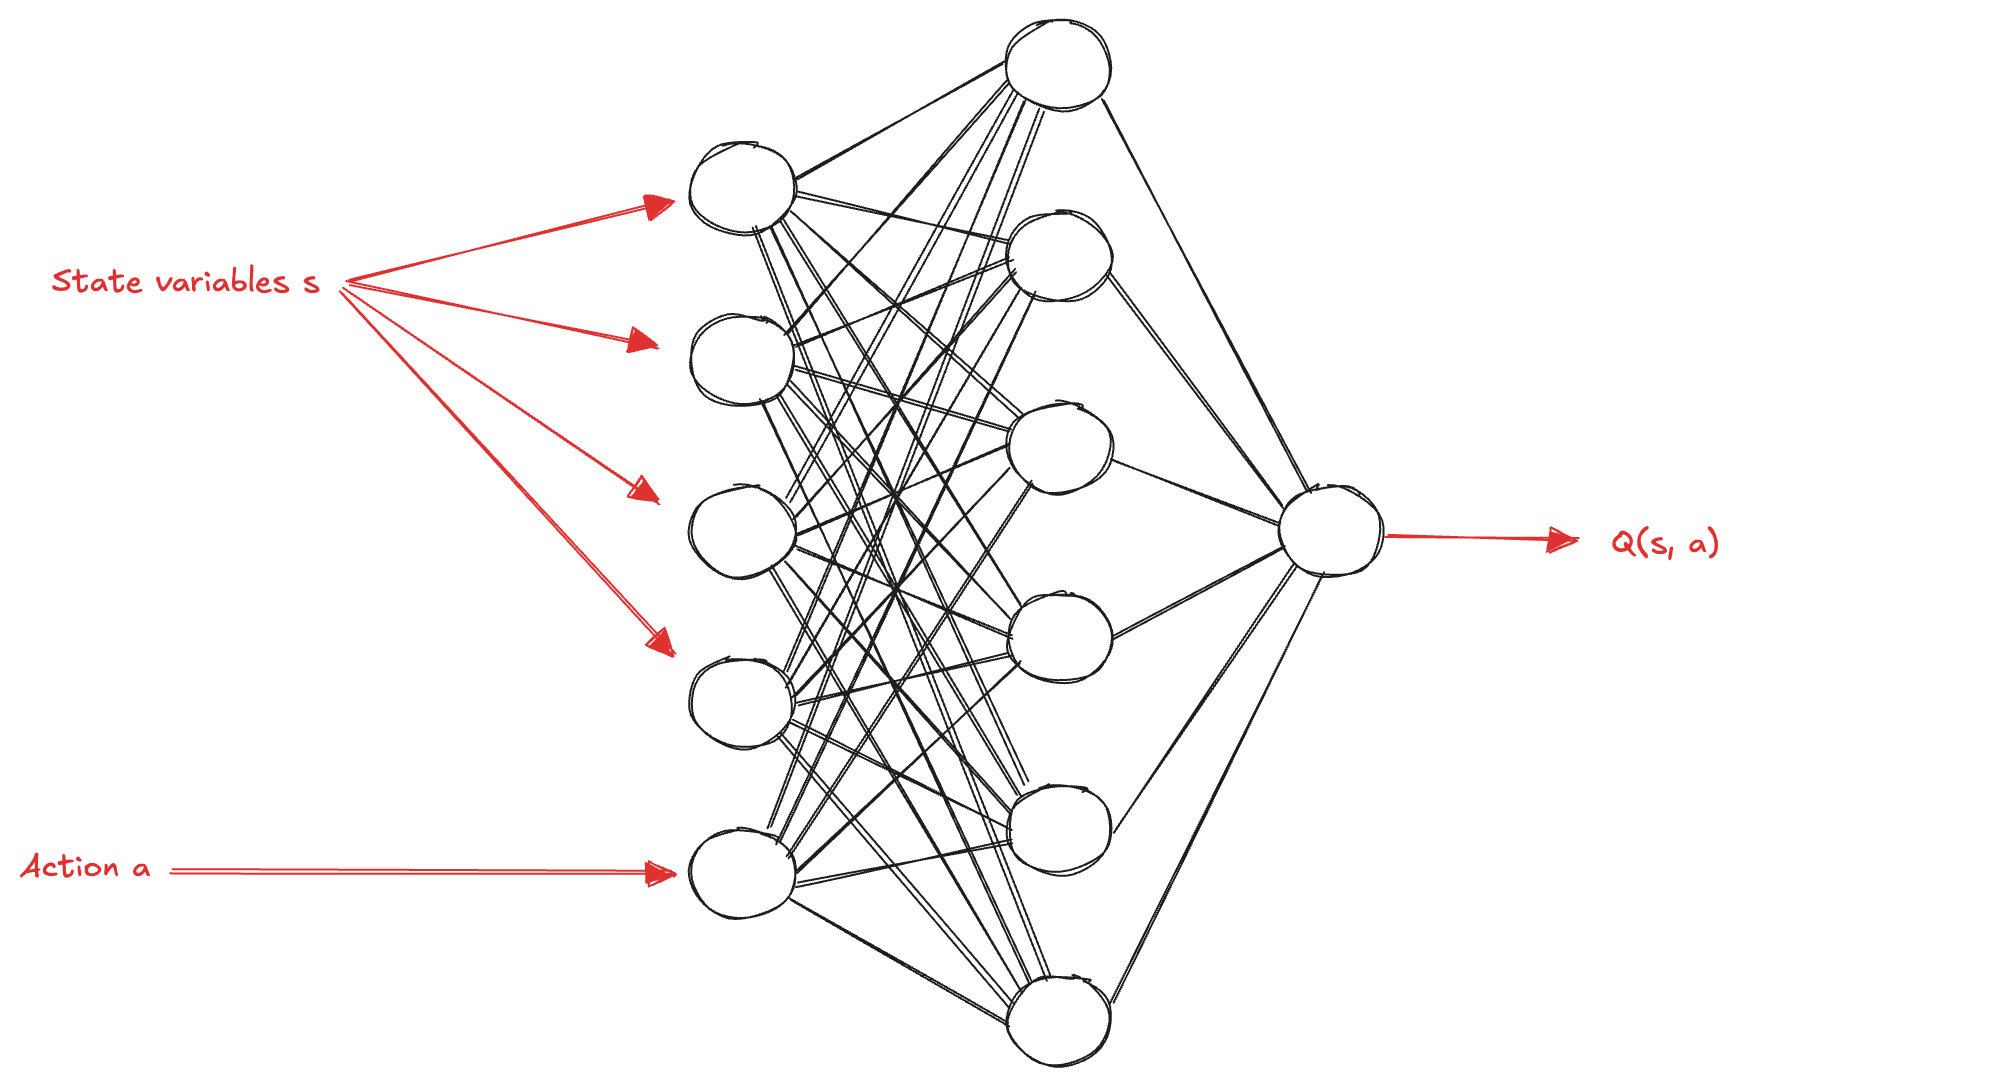

This architecture is valid, but there is a more efficient alternative. Instead of feeding both the state and a candidate action into the network, we feed only the state. The network then outputs one Q-value for each possible action in that state:

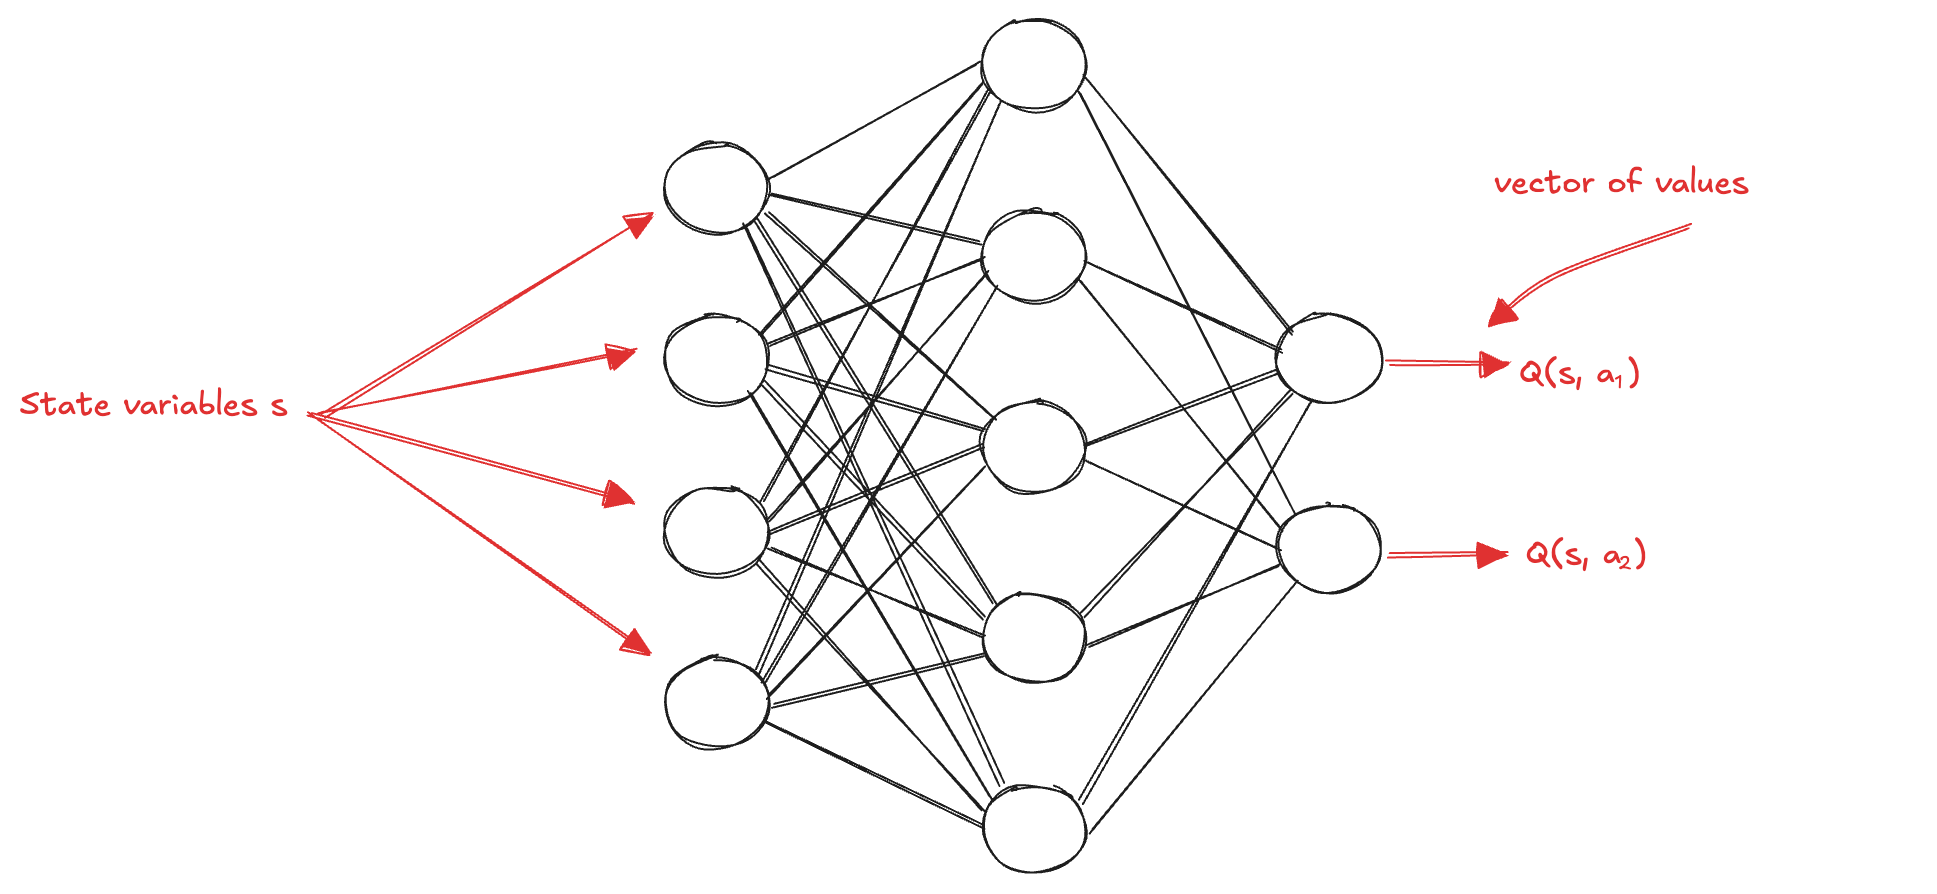

This architecture is especially useful with exploration strategies such as epsilon-greedy or softmax, because **a single forward pass gives the values of all available actions**. The state is passed through the network, and the network outputs an estimate of the action-value function for that state. 

### Universal Approximation

The policy remains implicit, as in Q-learning: the agent acts greedily, or approximately greedily during exploration, with respect to the estimated Q-values. This removes the need to store a separate value for every state-action pair. Instead, the network learns patterns from experience and uses them to generalize across states. This is essential in large or continuous environments, where enumerating all possible states is impossible. The parameters are learned from experience through gradient-based optimization. As the network weights are updated, the Q-value estimates improve, and so does the implicit policy derived from them:

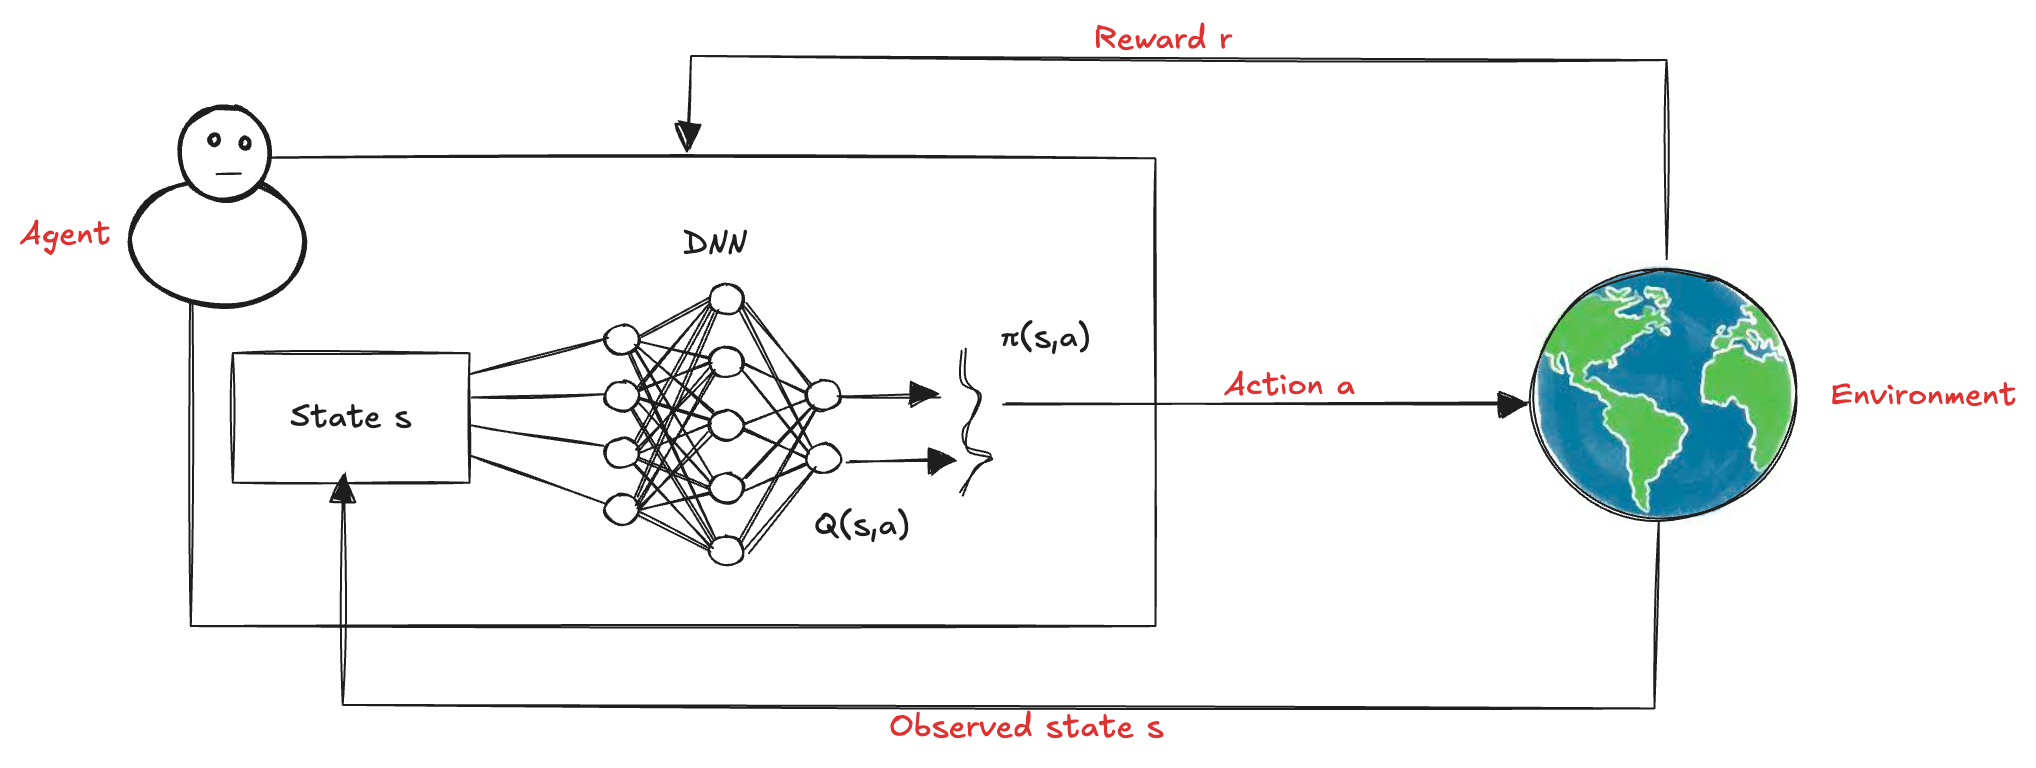

This use use of neural networks as function approximators is supported by the [**universal approximation theorem**](./papers/1989%20-%20Approximation%20by%20Superpositions%20of%20a%20Sigmoidal%20Function.pdf)). The theorem states that a feed-forward network with a single hidden layer and sufficiently many units can approximate any continuous function on a compact set to arbitrary accuracy. However, this is only an existence result. It tells us that a good approximation can exist, but it does not tell us whether gradient descent, applied to our reinforcement learning targets, will actually find it.  
We implement the function approximator in PyTorch. For Cart-Pole, a small network is sufficient: we use two hidden layers, both followed by ReLU activations. The input layer has one unit for each state variable, the output layer is linear and has one unit for each action, since the network must return the estimated Q-values directly:

In [10]:
import torch

def create_network(env, hidden_sizes=(512, 128)):

    # Unpack the hidden layer sizes.
    first_hidden, second_hidden = hidden_sizes

    return torch.nn.Sequential(
    
        # Map the state variables to the first hidden layer.
        torch.nn.Linear(env.observation_space.shape[0], first_hidden),
        torch.nn.ReLU(),

        # Connect the two hidden layers.
        torch.nn.Linear(first_hidden, second_hidden),
        torch.nn.ReLU(),

        # Output one Q-value per action, without a final activation.
        torch.nn.Linear(second_hidden, env.action_space.n),
    )

# Create a network for the CartPole environment 
# with two hidden layers of sizes 512 and 128.
q = create_network(cart_pole, hidden_sizes=(512, 128))

Using the neural network that estimates Q-values, we can define a greedy policy that selects the action with the highest predicted value in the current state. This means acting optimally with respect to the information currently encoded in the network:

In [11]:
class GreedyPolicy:
    
    def __init__(self, q):
        # Store the network used to estimate action values.
        self.q = q

    def select_action(self, state):
        # Convert the state to a floating-point tensor.
        state = torch.as_tensor(state, dtype=torch.float32)

        # Compute Q-values without tracking gradients.
        with torch.no_grad():
            q_values = self.q(state)

        # Select the action with the highest estimated Q-value.
        return int(q_values.argmax(dim=-1).item())

### Loss Function

To train a neural network, we need a **loss function**: a measure of how far the network’s predictions are from the values we want it to predict. In supervised learning, this is straightforward. We are given a dataset of examples, and each example comes with the correct output. The loss then measures the distance between the network’s prediction and the correct target. For regression problems, a common choice is the **mean squared error** (MSE), which averages the squared differences between predicted and target values. In reinforcement learning, the situation is more difficult for two reasons. First, **we do not start with a fixed dataset**: the agent must collect experience by interacting with the environment. Second, **we do not know the true action values**. Ideally, we would like to minimize the squared distance between our approximation and the optimal action-value function:

$\displaystyle \mathcal{L}(\theta)=\mathbb{E}_{s,a}\big[(q_*(s,a)-Q_\theta(s,a))^2\big]$

Of course, we do not have access to the optimal function. If we did, there would be nothing left to learn: 

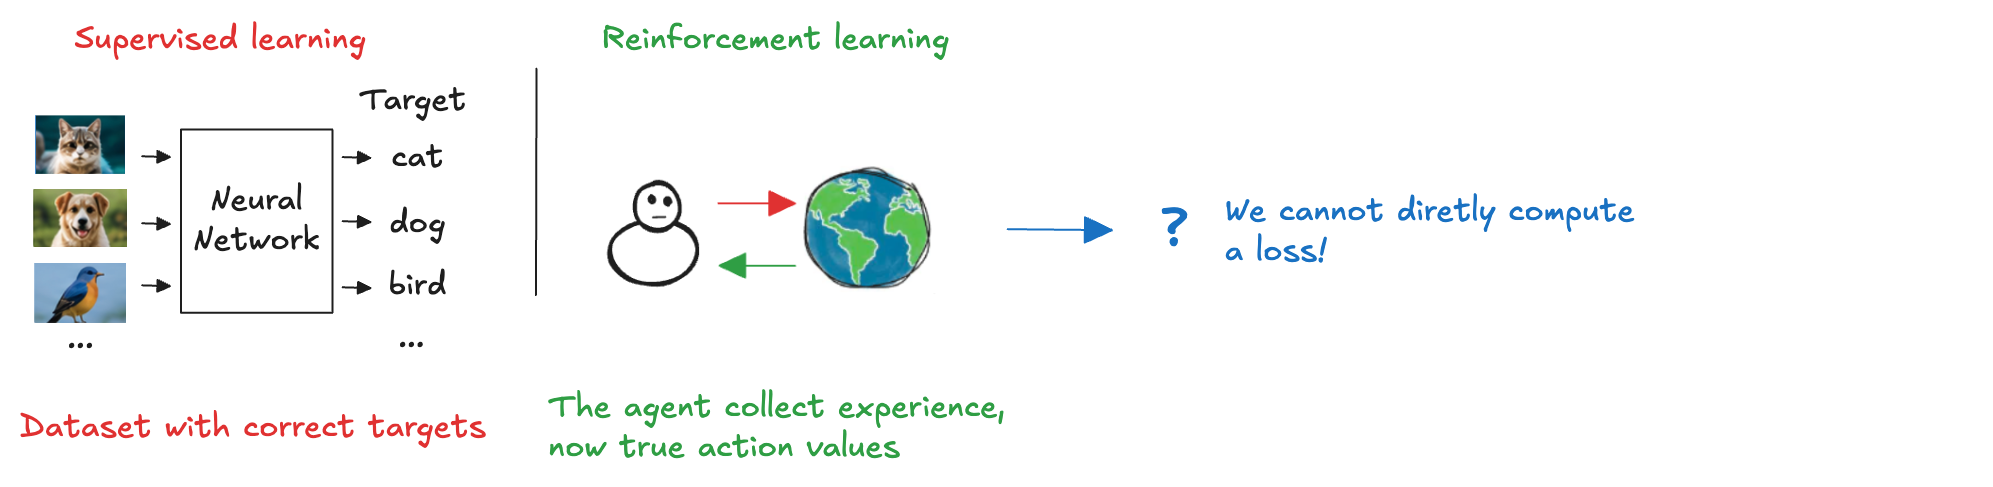

Instead, we build training targets using the same **bootstrapping** idea used in Q-learning. After observing a transition, we treat the immediate reward plus the estimated value of the next state as a **temporary target** for the current prediction. Since we are interested in the optimal action-value function, the next-state value is computed by taking the maximum over the available actions. In this sense, the update combines the two parts of generalized policy iteration. The network is **evaluated** by being trained to match the bootstrapped target, and the policy is **improved** because the target assumes greedy action selection in the next state. Thus, policy improvement is not a separate step here: it is built directly into the target through the maximum over actions. However, because we are using **non-linear function approximation**, the convergence guarantees of tabular Q-learning no longer apply. The targets used for training are not fixed labels. They depend on predictions made by the same network, especially through the estimated value of the next state. This creates a circular dependency:

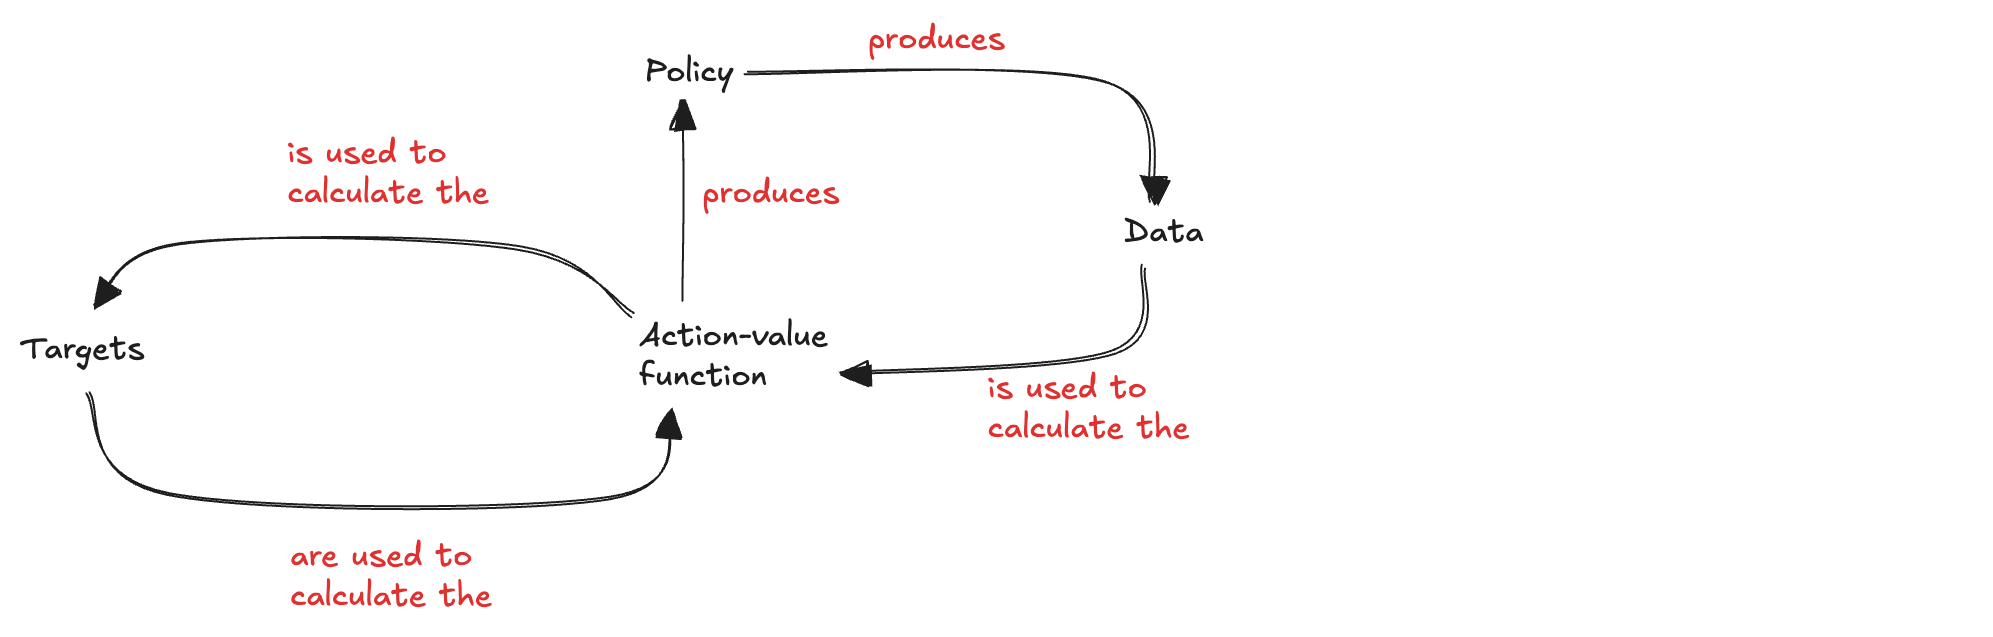

This circular dependency is **problematic**. It makes the learning problem less well behaved than standard supervised learning, because the targets are not fixed: they depend on the network’s own current predictions and change as the network changes Nevertheless, we can still use this idea and examine how far it takes us. As we have seen before, there are several possible targets for estimating an action-value function, including Monte Carlo (MC) targets, Temporal-Difference (TD) targets, n-step targets, and lambda targets:

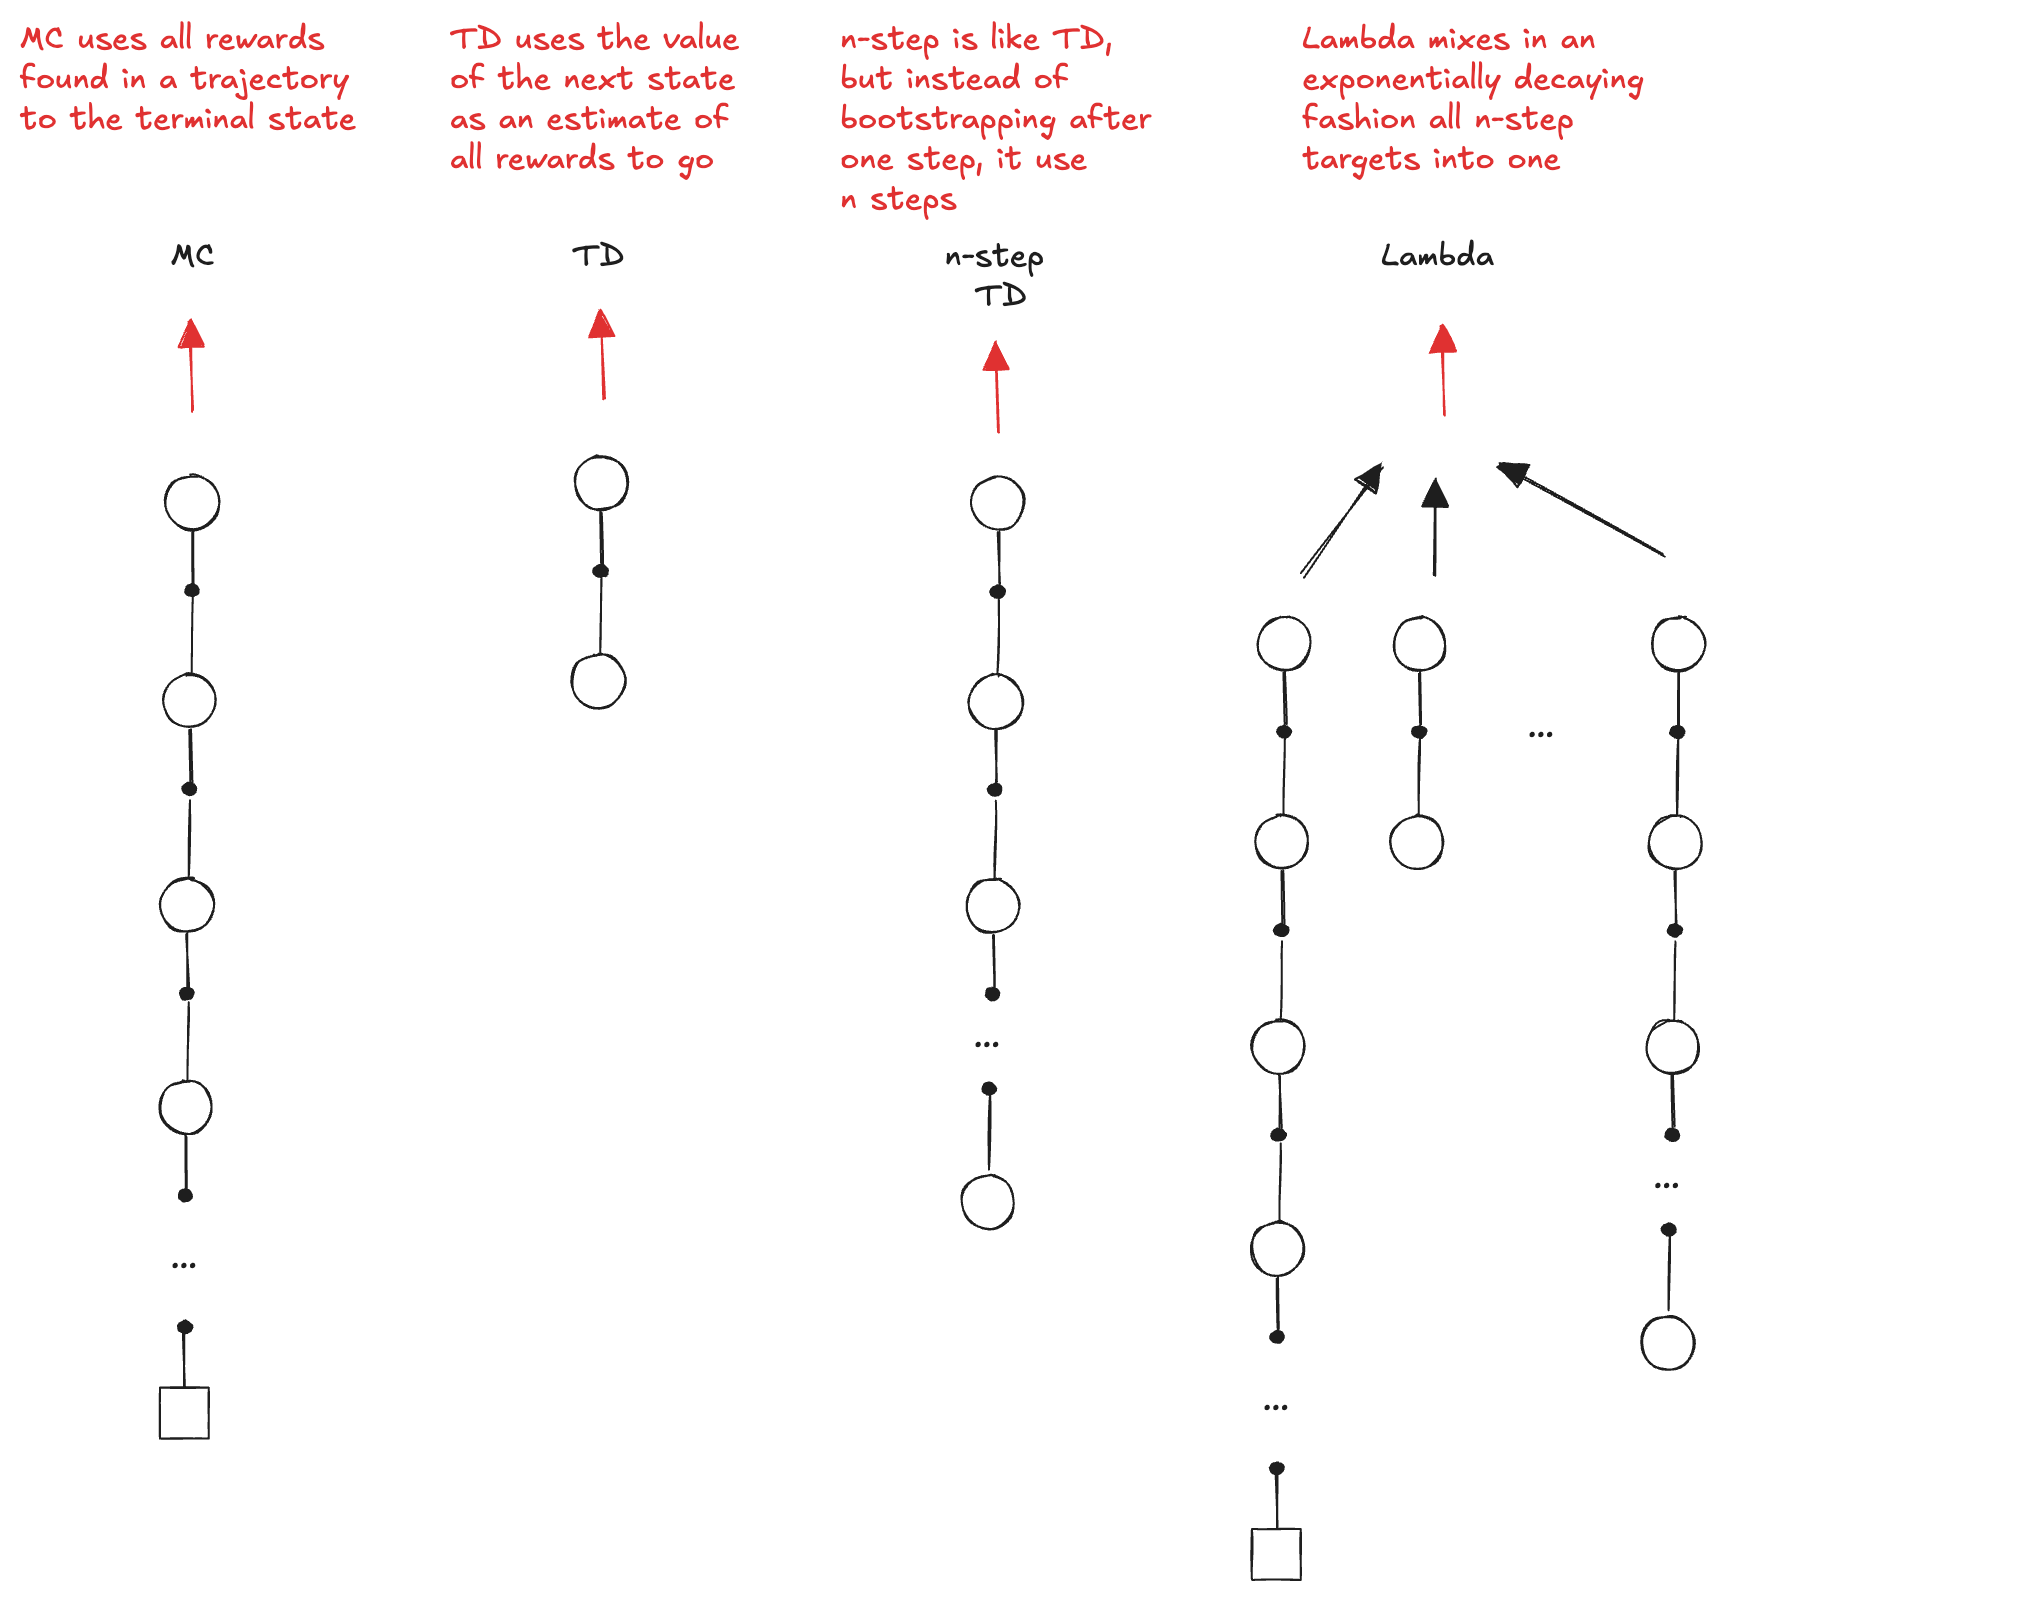

The target can be **on-policy** or **off-policy**, depending on how we bootstrap from the next state. In an on-policy method such as SARSA, the target uses the value of the action that the agent actually takes in the next state. In an off-policy method such as Q-learning, the target uses the value of the best action available in the next state. The corresponding tabular update rules are:

$\displaystyle Q_\text{SARSA}(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \big[ R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \big]$

$\displaystyle Q_\text{Q-learning}(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \big[ R_{t+1} + \gamma \max_{a'} Q(S_{t+1}, a') - Q(S_t, A_t) \big]$

NFQ uses the Q-learning target, so it is an **off-policy** method and its loss is:

$\displaystyle \mathcal{L}(\theta)=\mathbb{E}_{s,a,r,s'} \Big[ \big( r + \gamma \max_{a'} Q_\theta(s',a') - Q_\theta(s,a) \big)^2 \Big]$

### Optimization

To minimize the loss, we use the same **gradient-based optimizers** commonly used in supervised learning. **Batch gradient descent** computes the gradient using the entire dataset before each parameter update:

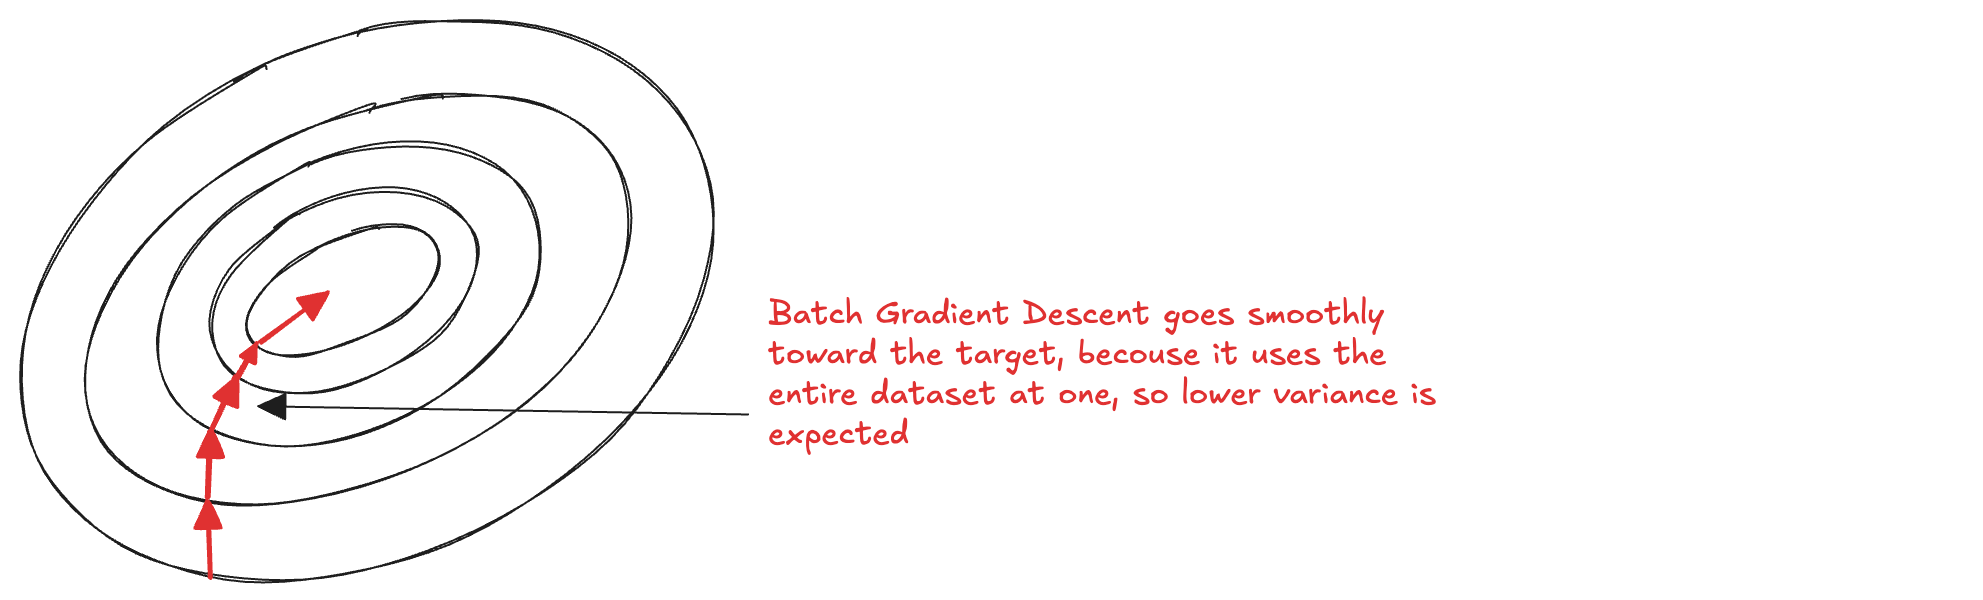

**Mini-batch gradient descent** computes the gradient using only a subset of the data at each update. If the subset contains a single sample, the method becomes stochastic gradient descent. Larger batches usually produce lower-variance updates, but each update is more expensive to compute:

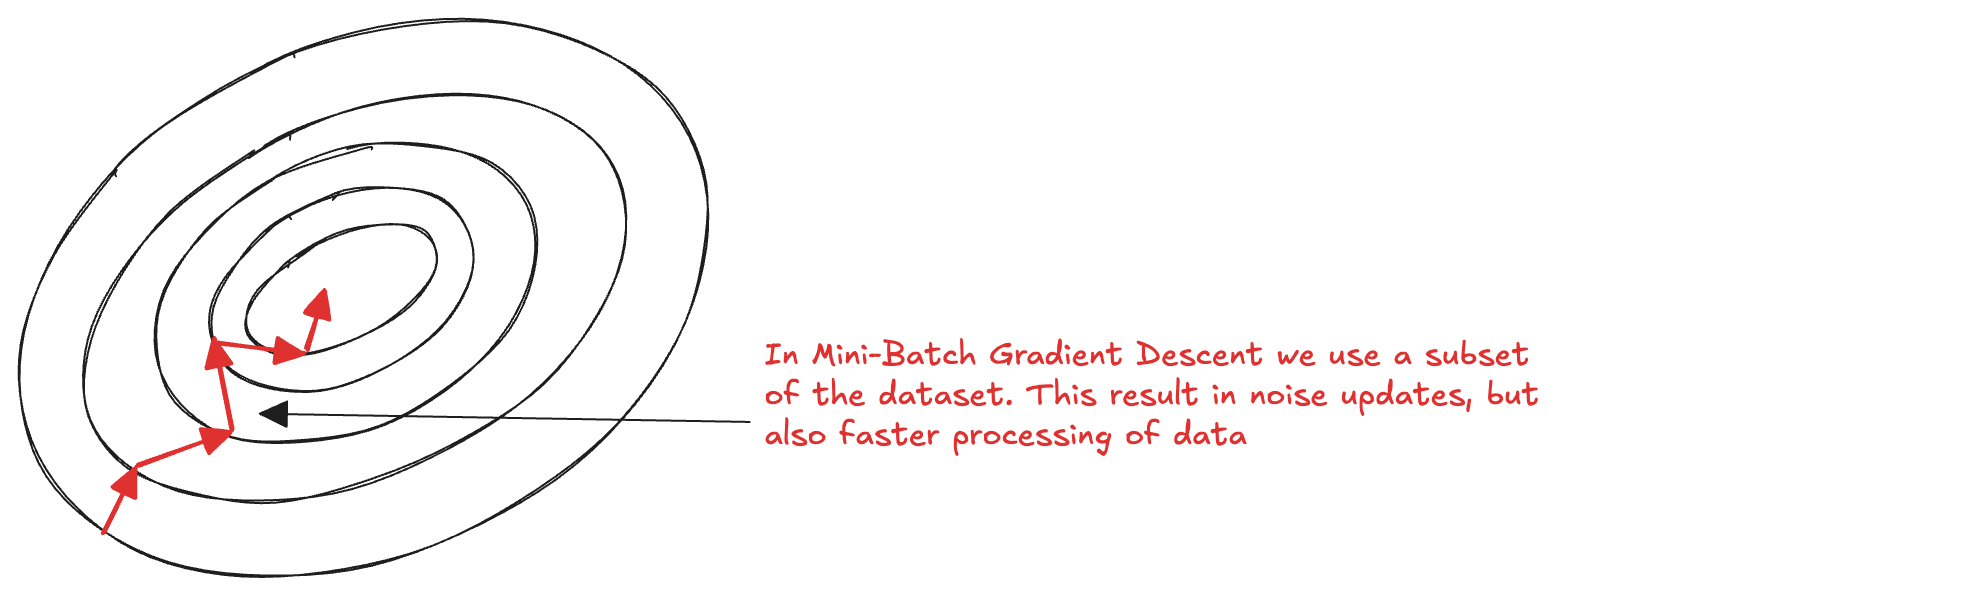

Several optimizers improve on this basic idea. **Momentum** updates the parameters using a moving average of past gradients rather than only the current gradient. **RMSprop** adapts the step size of each parameter by scaling it according to the recent magnitude of its gradients. **Adam** combines both ideas: momentum-like averaging and adaptive per-parameter step sizes.

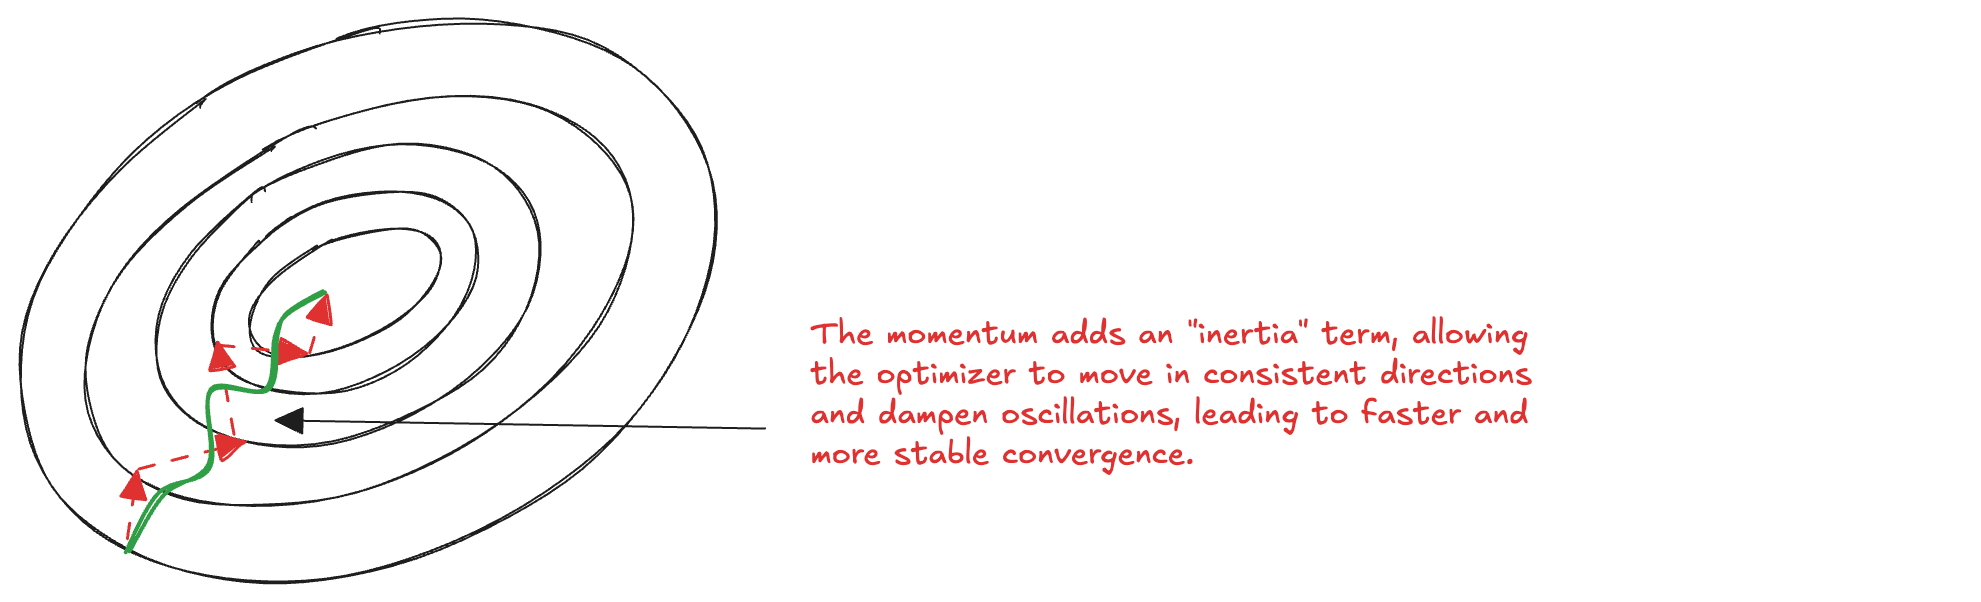

For our purposes, the key issue is not the optimizer itself, but the assumptions under which these methods are usually analyzed. Standard optimization in supervised learning typically assumes that the samples are **independent and identically distributed (IID)**, and that the targets are **stationary**. In reinforcement learning, neither assumption holds. Consecutive experiences are **strongly correlated**, the **data distribution changes** as the policy changes, and **the targets move** as the network is updated. Moreover, we do not start with a complete dataset, so pure batch gradient descent is not directly applicable. For this reason, the choice of optimizer can matter a great deal. In practice, robust adaptive optimizers such as RMSprop and Adam are often sensible choices for reinforcement learning:

In [12]:
def create_optimizer(q, learning_rate):
    return torch.optim.RMSprop(q.parameters(), lr=learning_rate)

All these optimizers require **the gradient of the loss**, and this introduces an important subtlety. In supervised learning, the target values are fixed labels provided in advance. The gradient is therefore computed only with respect to the model’s prediction. In NFQ, however, the target is also built using the same network we are training. In principle, this means that the target depends on the parameters too. The loss is:

$\displaystyle \mathcal{L}(\theta)=\mathbb{E}_{s,a,r,s'} \Big[ \big( r + \gamma \max_{a'} Q_\theta(s',a') - Q_\theta(s,a) \big)^2 \Big]$

However, when computing the update, **we treat the bootstrapped target as fixed**:

$\displaystyle \underbrace{r + \gamma \max_{a'} Q_\theta(s',a')}_{\text{treated as fixed target}}$

and differentiate only through the current prediction:

$\displaystyle \underbrace{Q_\theta(s,a)}_{\text{differentiated}}$

With this convention, the gradient used by NFQ is:

$\displaystyle \nabla_{\theta} \mathcal{L}(\theta) = -2\, \mathbb{E}_{s,a,r,s'} \Big[ \big( r + \gamma \max_{a'} Q_\theta(s',a') - Q_\theta(s,a) \big)\, \nabla_{\theta} Q_\theta(s,a) \Big]$

A gradient descent step then gives the familiar parametric update:

$\displaystyle \theta \leftarrow \theta + \alpha\, \big( r + \gamma \max_{a'} Q_\theta(s',a') - Q_\theta(s,a) \big)\, \nabla_{\theta} Q_\theta(s,a)$

Because we ignore the dependence of the target on the parameters, this is called a **semi-gradient method**. In PyTorch, this is the role of ".detach()" or "torch.no_grad()": they prevent gradients from flowing through the target.

### Dataset and training

At this point, we have a neural network, a bootstrapped target, and a loss function. A natural first idea would be to imitate tabular Q-learning as closely as possible: let the agent interact with the environment, and after each transition, immediately update the network using that single experience. With a table, this works reasonably well because each update affects only one entry. With a neural network, the situation is different. The same parameters are shared across many states and actions, so changing the weights to improve the prediction for one state-action pair can also change the predictions elsewhere in the state-action space. In principle, this shared structure is exactly what we want: it is what allows the network to generalize. In practice, however, online updates can make learning **unstable** and **slow**, because each new experience may partially undo or distort what the network learned from previous ones. The basic idea of NFQ is therefore to move from online updates to an **offline training procedure**. Instead of updating the network after every single transition, we first collect a set of transition experiences and then train the network on the whole dataset. For this reason, we store the agent’s experiences in a training set:

In [13]:
def create_experience_type(env):

    # State and next_state have the same shape as an observation.
    state_shape = env.observation_space.shape

    # Define the fields stored for each transition.
    fields = [
        ("state", np.float32, state_shape),      # observation before the action
        ("action", np.int8),                     # discrete action selected
        ("reward", np.float32),                  # immediate reward received
        ("next_state", np.float32, state_shape), # observation after the action
        ("failure", np.int8),                    # 1 if terminated, 0 otherwise
    ]
    
    return np.dtype(fields)

To train the agent, we must collect batches of experiences by interacting with the environment. During this phase, we use an **exploration strategy** to balance the trade-off between exploring new actions and exploiting what the agent has already learned. The common choice is the ε-greedy policy. We use a constant and rather large ε = 0.5: in the Cart-pole a mostly random behaviour produces short episodes that end in failure, but this is not a problem here, since the transitions that lead to termination are exactly those from which the network must learn that a state is bad, and what we evaluate is the greedy policy, not the exploratory one. A decaying ε, as seen in Chapter 04, is the usual refinement:


In [14]:
class EpsilonGreedyPolicy:

    def __init__(self, env, q, epsilon=0.5):
        
        # Create the random and greedy policies using the same environment/network.
        self.random_policy = RandomPolicy(env)
        self.greedy_policy = GreedyPolicy(q)

        # Store
        self.epsilon = epsilon

    def select_action(self, state):
        
        # Explore with probability epsilon.
        if random.random() < self.epsilon:
            return self.random_policy.select_action(state)

        # Otherwise, exploit the current Q-value estimates.
        return self.greedy_policy.select_action(state)

We collect the experience by interacting with the environment. During this data-collection phase, the agent follows an **exploration strategy**, so that it can try different actions instead of always exploiting its current estimates. A common choice is the **epsilon-greedy policy**. This means that the exploratory policy is quite noisy, and many episodes will be short and end in failure. For NFQ, this is acceptable. The transitions that lead to failure are informative: they teach the network **which states and actions are dangerous**. Moreover, the policy we ultimately evaluate is not the exploratory policy, but the greedy policy derived from the learned Q-values. Once a batch of transitions has been collected, we can **train the network** by computing one bootstrapped target for each transition and then fitting the predicted Q-values to those targets for several optimization epochs:

In [15]:
def optimize_nfq(batch, q, optimizer, gamma, epochs):

    # Convert the transition fields into tensors.
    states = torch.from_numpy(batch["state"].copy()).float()
    actions = torch.from_numpy(batch["action"].copy()).long()
    rewards = torch.from_numpy(batch["reward"].copy()).float()
    next_states = torch.from_numpy(batch["next_state"].copy()).float()
    failures = torch.from_numpy(batch["failure"].copy()).float()

    # Compute the bootstrapped targets once, without tracking gradients.
    # True terminal transitions use only the immediate reward
    with torch.no_grad():
        max_q_next = q(next_states).max(dim=1).values
        target = rewards + gamma * max_q_next * (1.0 - failures)

    # Fit the network to these fixed targets for several epochs
    for epoch in range(epochs):
        
        # Select Q(s, a) for the action actually taken in each transition.
        q_current = q(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        # Compute the mean squared difference between targets and predictions.
        loss = (target - q_current).pow(2).mean()

        # Clear previous gradients, compute new ones and update the parameters.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Return the final loss
    return loss.item()

### Algorithm

We can now put the pieces together and describe the full training loop:

1. Use a fully connected neural network that takes the state as input and outputs one Q-value for each action
2. Use an epsilon-greedy policy to interact with the environment and collect a batch of experiences
3. Using the current network, compute the off-policy target for each transition in the batch
4. Fit the network to these targets by minimizing the mean squared TD error for several epochs
5. Repeat the process: collect new experiences, compute new targets, and update the network again.

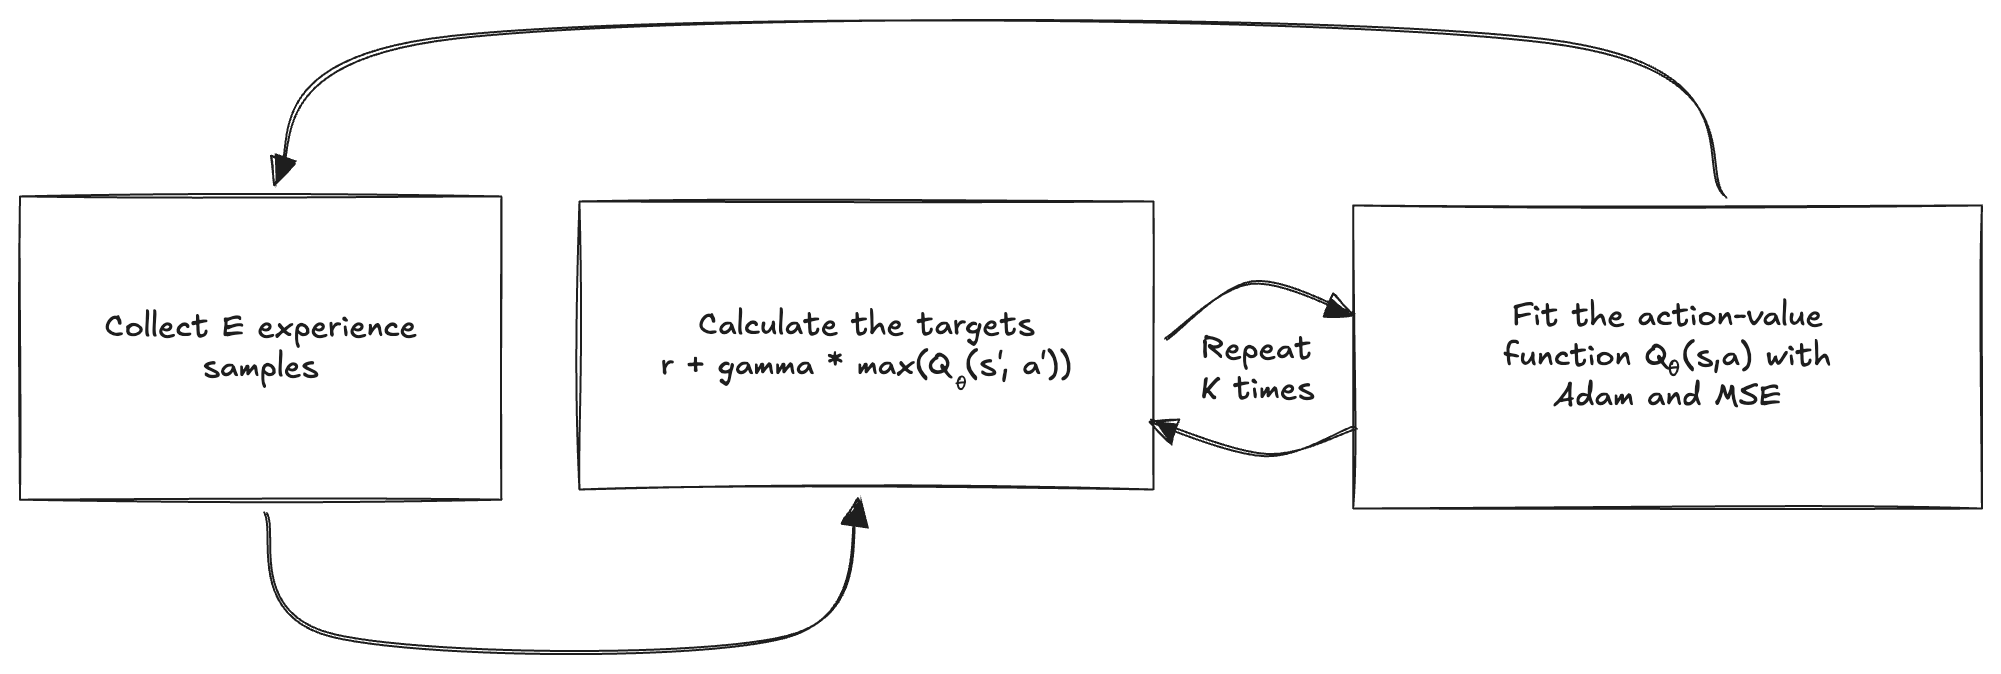

In [16]:
def nfq(env, max_episodes,
        hidden_sizes=(512, 128), 
        learning_rate=0.007, batch_size=1024, epochs=40,
        gamma=0.99, epsilon=0.5,
        evaluation_episodes=10, seed=34, verbose=True):
    
    # Seed the environment, network initialization and exploration.
    seed_environment(env, seed)
    random.seed(seed)

    # Create a fresh network and optimizer.
    q = create_network(env, hidden_sizes)
    optimizer = create_optimizer(q, learning_rate)

    # Create the greedy and exploratory policies, which share the same network.
    greedy_policy = GreedyPolicy(q)
    exploratory_policy = EpsilonGreedyPolicy(env, q, epsilon)

    # Collect batches of transitions, possibly spanning multiple episodes.
    experience_type = create_experience_type(env)
    batch = np.empty(batch_size, dtype=experience_type)
    index = 0

    # Track the score and training steps for each episode.
    step = 0
    scores, training_steps = [], []

    # Run the episodes, collecting transitions and fitting the network.
    for episode in range(max_episodes):

        # Start a new episode.
        state, _ = env.reset()
        done = False

        # Run the episode until termination or truncation.
        while not done:

            # Select an action using epsilon-greedy exploration.
            action = exploratory_policy.select_action(state)

            # Take a step in the environment and store the transition.
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Only true termination disables bootstrapping.
            batch[index] = (state, action, reward, next_state, terminated)
            index += 1
            step += 1

            # Fit the full batch, then reuse its storage for new transitions.
            if index == batch_size:
                optimize_nfq(batch, q, optimizer, gamma, epochs)
                index = 0

            state = next_state

        # Evaluate without exploration; do not count evaluation transitions.
        score = evaluate(env, greedy_policy, evaluation_episodes)
        scores.append(score)
        training_steps.append(step)

        # Show the current episode and score, overwriting the previous line.
        if verbose:
            print(f"Episode {episode + 1:03}, score {score:05.1f}",
                  end="\r", flush=True)

    # Return the learning curve, cumulative training steps
    # and trained network.
    return {
        "scores": np.asarray(scores),
        "steps": np.asarray(training_steps),
        "network": q,
    }

### Solve Cart-Pole

We can apply the algorithm to the Cart-pole environment:

In [17]:
nfq_run = nfq(cart_pole, max_episodes=220)

# Create a greedy policy using the trained network.
nfq_policy = GreedyPolicy(nfq_run["network"])

# Retrieve the evaluation scores recorded during training.
scores = nfq_run["scores"]

We can evaluate the performance of the learned agent versus the random one:

In [18]:
agent_score = evaluate(cart_pole, nfq_policy, episodes=10)
print("Random score", random_score)
print("Agent score", agent_score)

Random score 21.921
Agent score 500.0


And we can see the agent in action:

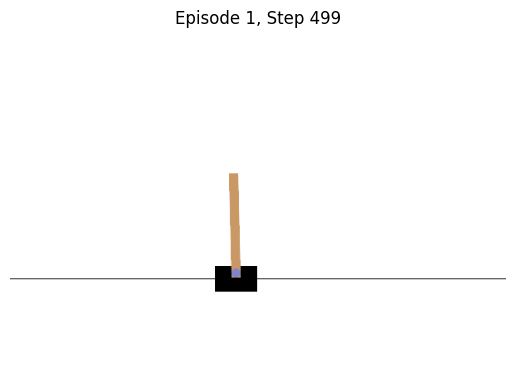

In [19]:
show_policy(cart_pole, nfq_policy, n_episodes=1, max_steps=500)

The trained agent can balance the pole for a considerable amount of time, but this result was obtained by choosing a number of training steps that gives good performance; with different choices, the outcome can change substantially. A single run is herefore not enough to understand **how the algorithm learns**, or **how reliable the result is**. To study the learning process, we repeat the complete algorithm with different seeds, creating fresh networks and optimizers on every run. It keeps the raw scores and training-step counts, then summarizes the smoothed curves across seeds. We can assess **how stable the algorithm is** and **how sensitive it is to random initialization and exploration**. This allows us to distinguish **genuine learning behavior** from a **lucky run**, and to evaluate whether the algorithm converges reliably across repetition.

In [20]:
from pathlib import Path
import joblib

def experiment(
    # 
    name, env, algorithm, max_episodes,
    
    # Experiment settings
    seeds=(12, 34, 56, 78, 90),
    evaluation_episodes=10,
    smoothing_window=25,
    verbose=True,
    
    # Shared learning parameters
    hidden_sizes=(512, 128),
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=32,
    
    # Algorithm-specific parameters
    **algorithm_parameters
):
    
    # Load the results of a previously saved experiment
    results_path = Path("temp") / f"{name}_results.joblib"
    if results_path.exists():
        if verbose:
            print(f"Loaded results from {results_path}")
        return joblib.load(results_path)

    # Initialize lists to store the raw scores, training steps, final network
    # parameters and any additional data returned by each run
    raw_scores, training_steps, networks, runs = [], [], [], []

    # Repeat training with different seeds
    for seed in seeds:

        # Run the algorithm with the current seed
        run = algorithm(
            env,
            max_episodes=max_episodes,
            seed=seed,
            hidden_sizes=hidden_sizes,
            learning_rate=learning_rate,
            gamma=gamma,
            batch_size=batch_size,
            evaluation_episodes=evaluation_episodes,
            verbose=verbose,
            **algorithm_parameters,
        )

        # Store the raw scores and training steps for this run
        raw_scores.append(run["scores"])
        training_steps.append(run["steps"])

        # Store the trained parameters and any extra per-run data
        # (e.g. the replay diagnostics of the next sections)
        networks.append(run["network"].state_dict())
        runs.append({key: value for key, value in run.items()
                     if key not in ("scores", "steps", "network")})

    # Apply a moving average to each run separately
    raw_scores = np.asarray(raw_scores, dtype=float)
    kernel = np.ones(smoothing_window) / smoothing_window
    smoothed_scores = []
    for scores in raw_scores:
        smoothed_scores.append(np.convolve(scores, kernel, mode="valid"))
    smoothed_scores = np.asarray(smoothed_scores)

    # Compute the mean and range across seeds, retaining the original data
    results = {
        "mean_score": smoothed_scores.mean(axis=0),
        "min_score": smoothed_scores.min(axis=0),
        "max_score": smoothed_scores.max(axis=0),
        "raw_scores": raw_scores,
        "training_steps": np.asarray(training_steps),
        "seeds": seeds,
        "max_episodes": max_episodes,
        "smoothing_window": smoothing_window,
        "networks": networks,
        "runs": runs,
    }

    # Save the results
    results_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(results, results_path)

    return results


We now define the hyperparameters that control both the training procedure and the neural network architecture. These values are different from those used in the initial run: the first hidden layer is smaller, the learning rate is much lower, and the number of optimization epochs per batch is reduced. These choices were selected using a **grid search**:

In [21]:
nfq_results = experiment(
    name="nfq_cartpole",
    env=cart_pole,
    algorithm=nfq,
    max_episodes=1500,
    # Shared learning parameters.
    hidden_sizes=(256, 128),
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=1024,
    # NFQ-specific parameters.
    epochs=16,
    epsilon=0.5,
)

Loaded results from temp/nfq_cartpole_results.joblib


After running the experiment, we plot the learning curve by showing the mean score across seeds, together with the range between the best and worst run. This gives a quick visual summary of both performance and variability:

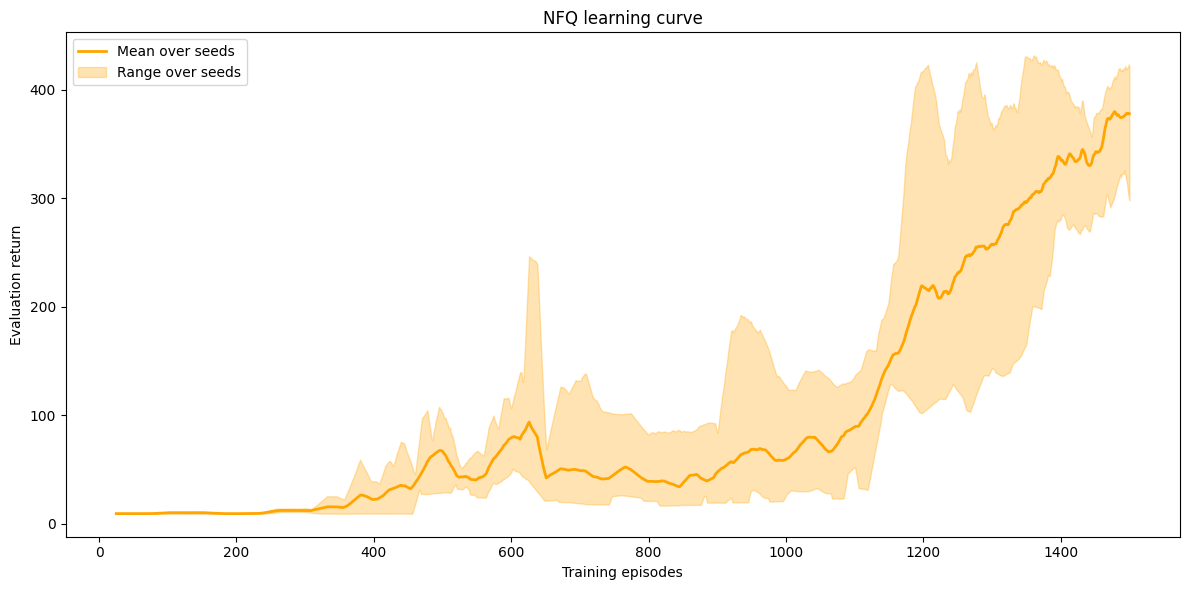

In [22]:
# Plot each moving average at the final episode of its window.
window = nfq_results["smoothing_window"]
episodes = np.arange(window, window + len(nfq_results["mean_score"]))

# Create the figure and label the axes
plt.figure(figsize=(12, 6))
plt.title("NFQ learning curve")
plt.xlabel("Training episodes")
plt.ylabel("Evaluation return")

# Plot the mean of the smoothed evaluation curves across seeds.
plt.plot(episodes, nfq_results["mean_score"],
         color="orange", linewidth=2, label="Mean over seeds")

# Shade the minimum–maximum range across seeds.
# This shows variability between runs, not a confidence interval.
plt.fill_between(episodes, nfq_results["min_score"], nfq_results["max_score"],
                 color="orange", alpha=0.3, label="Range over seeds")

plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

The NFQ experiment shows that the algorithm can learn a useful policy for Cart-Pole, but also that **the learning process is unstable**. At the beginning, the average score stays close to the random-policy baseline. After a few hundred episodes, performance improves sharply, showing that the network has started to discover a policy that can keep the pole balanced for longer. However, **the improvement is not smooth**. The mean curve fluctuates substantially, and the shaded region between the best and worst seeds is wide. This means that different runs, initialized with different random seeds, learn at different speeds and sometimes reach very different levels of performance. In some runs the agent solves the task almost perfectly, while in others performance remains much lower or deteriorates after improving. Overall, NFQ is able to learn in this simple environment, but the plot also shows that **it is not reliable**. A good result is possible, but it is not guaranteed across seeds. This variability suggests that the algorithm is sensitive to initialization, exploration, and the particular transitions collected during training

## Deep Q-Network (DQN)

NFQ shows that neural networks can approximate action-value functions, but it also reveals why combining value-based reinforcement learning with function approximation is delicate. The agent is not learning from a fixed dataset with fixed labels. It collects its own data, updates its policy while learning, and builds its targets from the same value estimates it is trying to improve. **Deep Q-Networks**, or DQN, were introduced to make this idea **more stable and scalable**. They keep the core structure of Q-learning with a neural network, but add two crucial mechanisms: a replay buffer, which reduces the correlation between consecutive samples, and a target network, which makes the bootstrapped targets more stable.

### Deadly Triad

NFQ exposes two fundamental difficulties that appear whenever value-based reinforcement learning is combined with function approximation. The first difficulty is **non-stationary targets**. In supervised learning, targets are fixed labels. In value-based reinforcement learning, however, targets are built from the network’s own predictions. When the network is updated, the estimated value of the next state changes as well, and therefore the target changes too. The network is trying to chase a target that moves while it is being learned. NFQ reduces this instability by using fitted batch learning: targets are computed once for a batch and then kept fixed during the optimization phase. This makes each fitting step more similar to supervised learning. However, the targets still change from one batch to the next, because they are recomputed using the updated network.

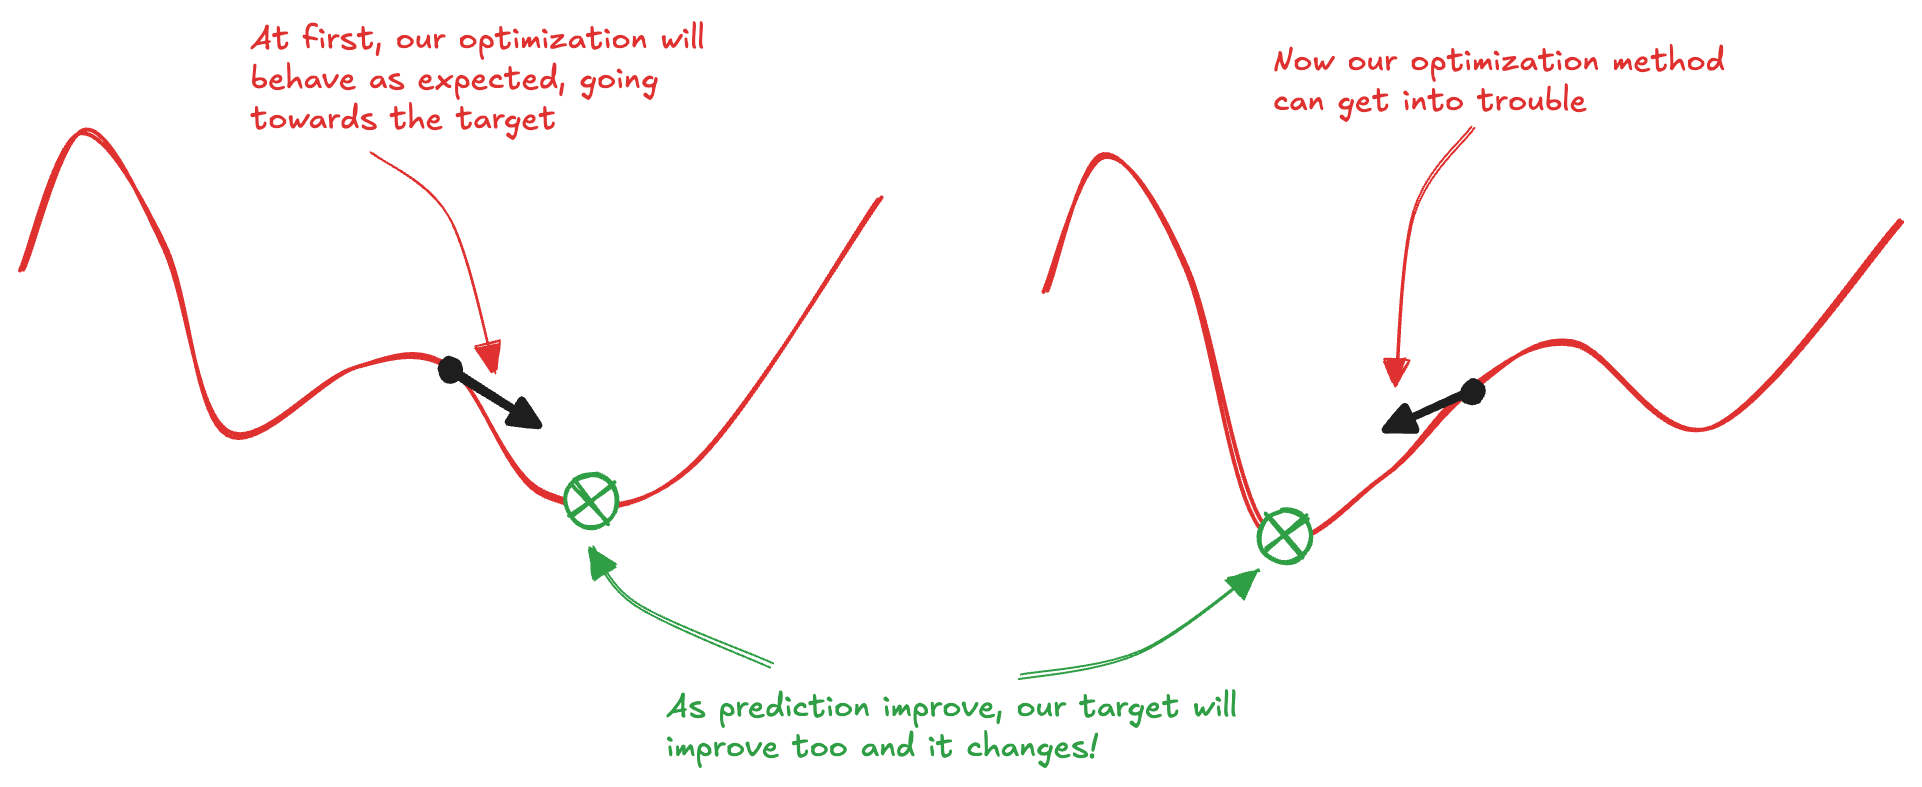

The second difficulty is **correlated samples**. Gradient-based optimizers are usually designed for data that is approximately independent and identically distributed. In reinforcement learning, experience is collected online, along trajectories. The transition observed at time step t+1 is strongly related to the transition observed at time step t. Moreover, the data distribution changes over time because the policy used to collect experience changes as the agent learns.

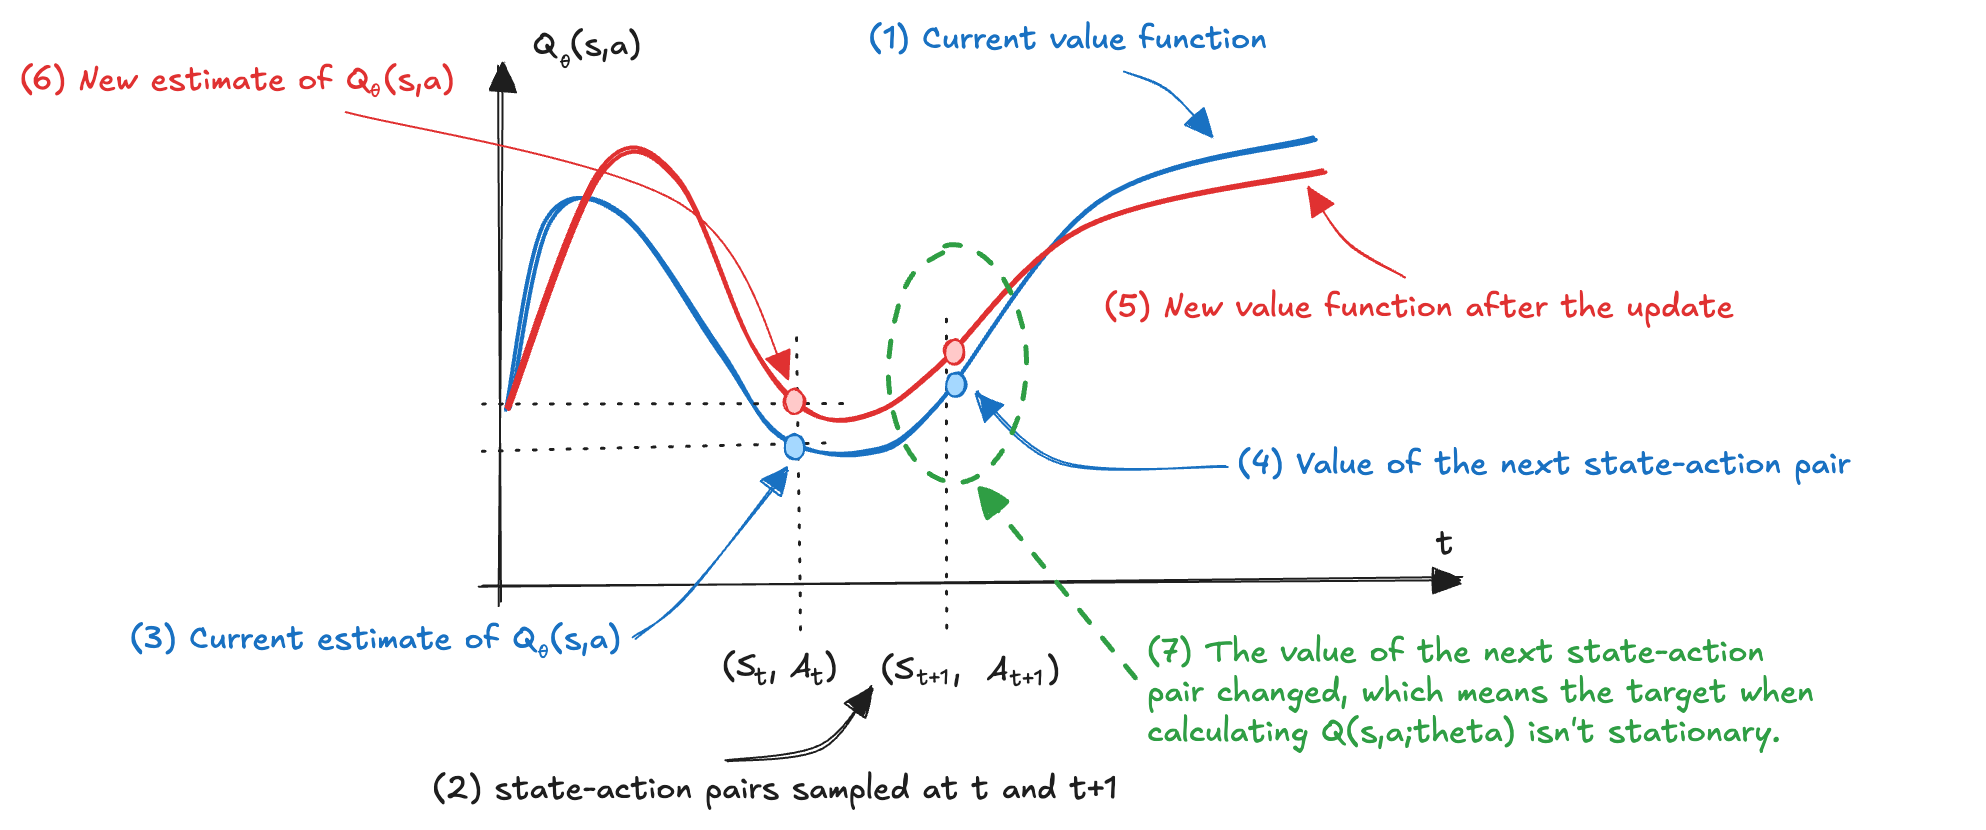

These two problems are symptoms of a deeper source of instability known as the [**deadly triad**](./papers/2018%20-%20Deep%20Reinforcement%20Learning%20and%20the%20Deadly%20Triad.pdf). Instability can arise when three ingredients are combined: **function approximation**, **bootstrapping**, and **off-policy learning**. NFQ contains all three. It uses a neural network as a function approximator, it bootstraps because its targets depend on current value estimates, and it is off-policy because the data is collected with an exploratory policy while the targets are computed using greedy action selection.

### Experience Replay

In NFQ, the network is trained on a batch of recently collected transitions. Even if the batch contains many samples, those samples are still **strongly correlated**, because they usually come from the same few trajectories. As a result, the optimizer repeatedly sees data that are too similar and too dependent on the agent’s most recent behavior. **Experience replay** addresses this problem by storing past transitions in a **replay memory**. Instead of training only on the most recent batch, the agent keeps **a large collection of experiences** gathered over time. At each update, it **samples a mini-batch uniformly at random from this memory**.

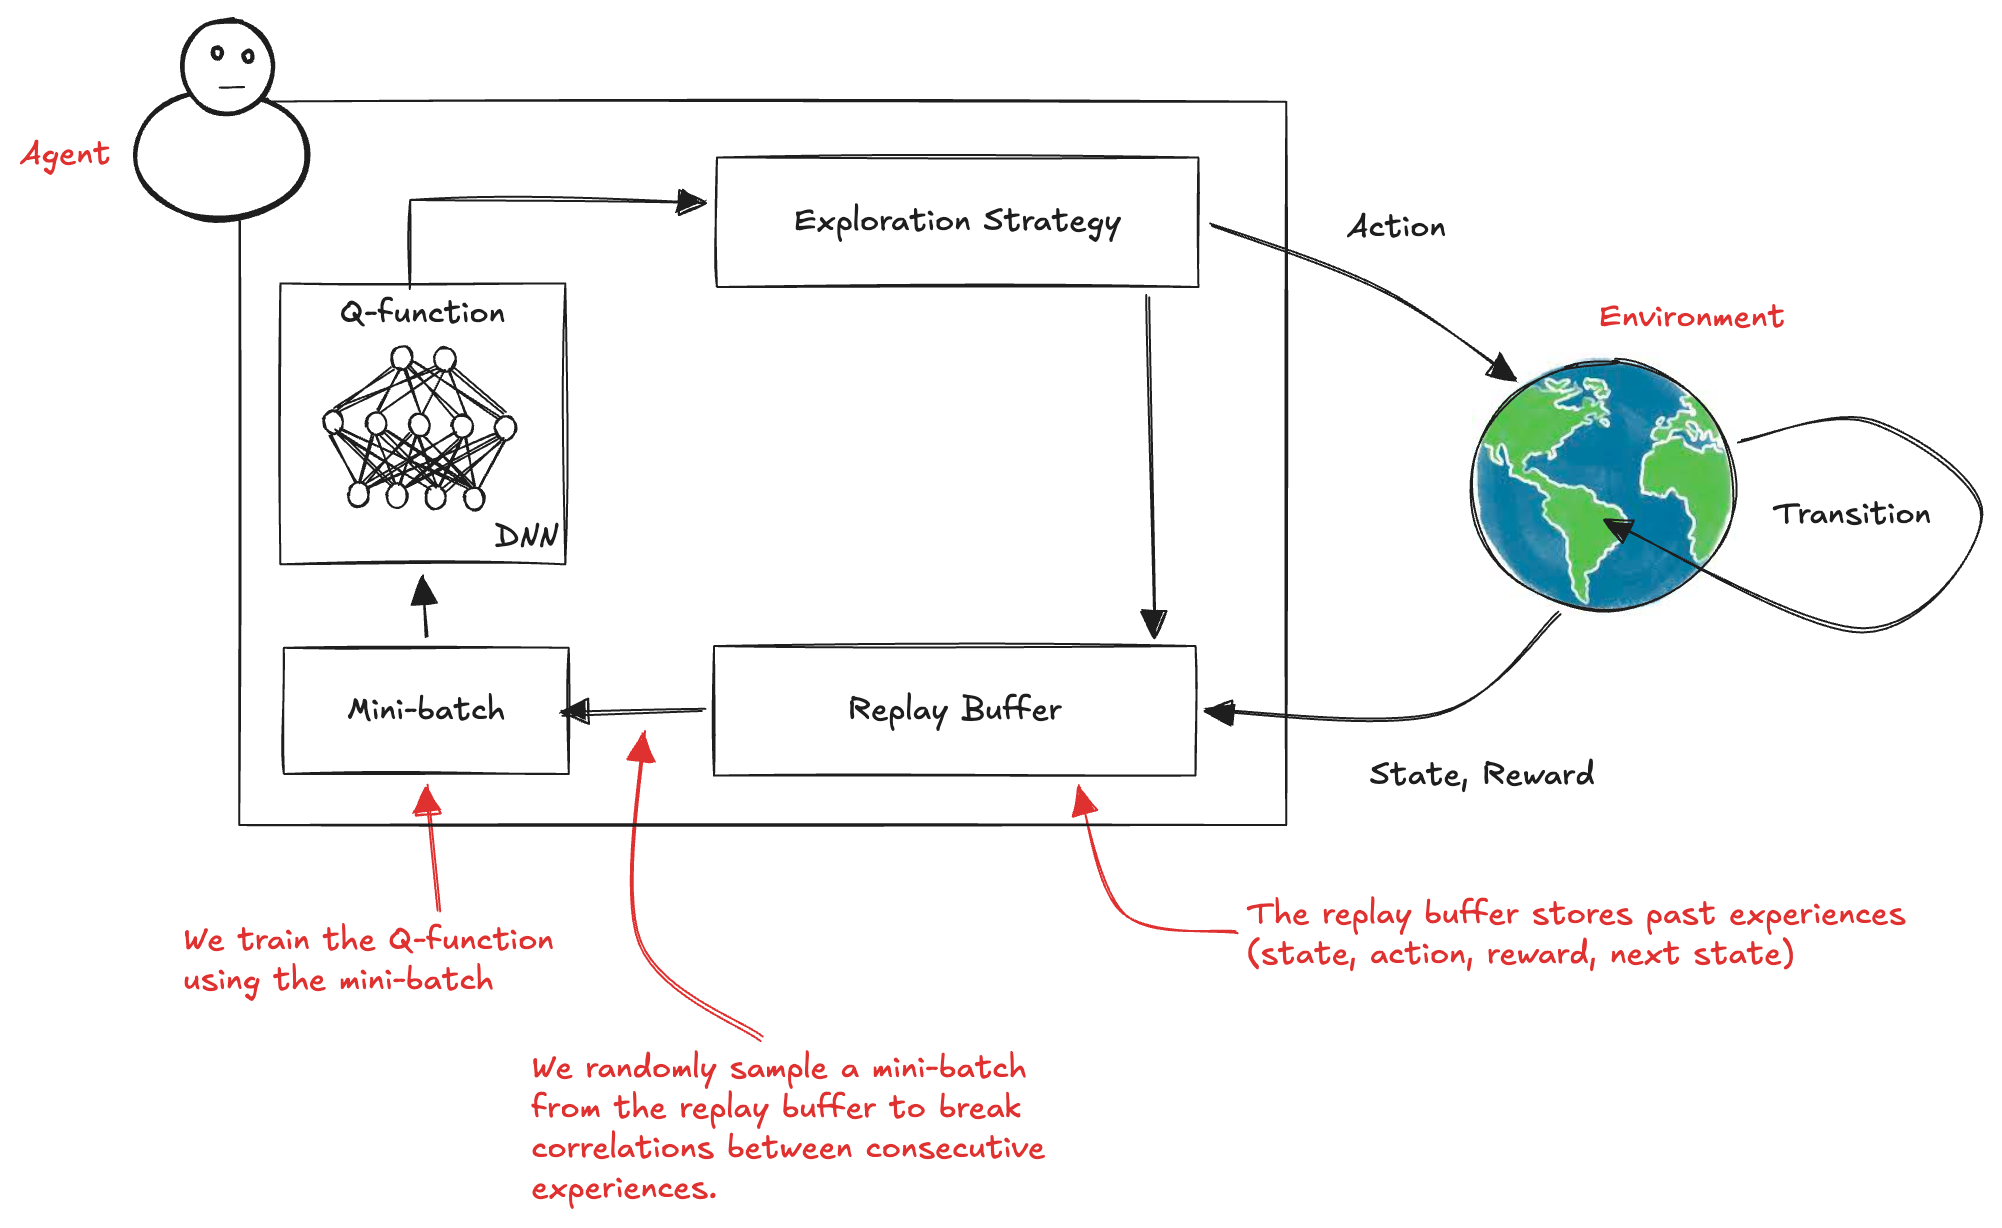

This has two important effects. First, the **mini-batches become more diverse**, because they contain transitions from different episodes and different moments of training. Second, **the samples look more like the independent and identically distributed data** assumed by standard optimizers. They are **not truly IID**, but random sampling from a large memory reduces the strongest temporal correlations and makes training more stable. Compared with NFQ, the main change is therefore not the target itself, but where the training samples come from. Instead of using only the most recent online experience, DQN trains on transitions sampled uniformly from the replay buffer:

$\displaystyle \mathcal{L}(\theta) = \mathbb{E}_{(s,a,r,s') \sim U(\mathcal{D})} \Big[ \big( r + \gamma \max_{a'} Q_\theta(s',a') - Q_\theta(s,a) \big)^2 \Big]$

In practice, replay memory must be implemented carefully. With high-dimensional observations, such as images, **a naive buffer can quickly run into memory limits**. For example, if each state is represented by a stack of recent frames, storing every full state separately would duplicate many frames and waste memory. For Cart-Pole, the observations are small, so a simple implementation is enough. We use a **circular buffer**: a fixed-size array that stores new transitions until it is full, and then overwrites the oldest transitions with the newest ones. This solves the fixed-size storage problem. In image-based environments, more efficient implementations usually store each frame only once and reconstruct stacked states when sampling.

In [23]:
def create_replay_memory(env, memory_size):
    
    # Define the fields and state dimensions of each stored transition.
    experience_type = create_experience_type(env)

    # Allocate fixed-size storage; its entries are initially uninitialized.
    buffer = np.empty(memory_size, dtype=experience_type)

    return {
        "size": memory_size,  # maximum number of stored transitions
        "buffer": buffer,     # array containing the transitions
        "index": 0,           # position where the next transition will be stored
        "entries": 0,         # number of transitions currently available
    }

Each time the agent observes a transition, we insert it into the replay memory. When the buffer is full, the oldest transitions are overwritten in circular order:

In [24]:
def store_experience(replay_memory, experience):
    
    # Store the transition at the next available position.
    # If the buffer is full, this overwrites the oldest transition.
    replay_memory["buffer"][replay_memory["index"]] = experience

    # Increase the number of stored transitions, up to the buffer capacity.
    replay_memory["entries"] = min(
        replay_memory["entries"] + 1,
        replay_memory["size"],
    )

    # Move to the next position, wrapping back to zero at the end of the buffer.
    replay_memory["index"] = (
        replay_memory["index"] + 1
    ) % replay_memory["size"]

Once the replay memory contains enough transitions, we can draw a random mini-batch from it and use that batch to update the network:

In [25]:
def sample_experiences(replay_memory, batch_size):

    # Sample uniformly from populated entries only.
    # Without replacement, each transition appears at most once in the batch.
    indices = np.random.choice(
        replay_memory["entries"],
        size=batch_size,
        replace=False,
    )

    # Return the selected transitions as a mini-batch.
    return replay_memory["buffer"][indices]

### Target Networks

The replay buffer reduces the correlation between training samples, but it does not solve the second problem of value-based deep reinforcement learning: the targets are still non-stationary:

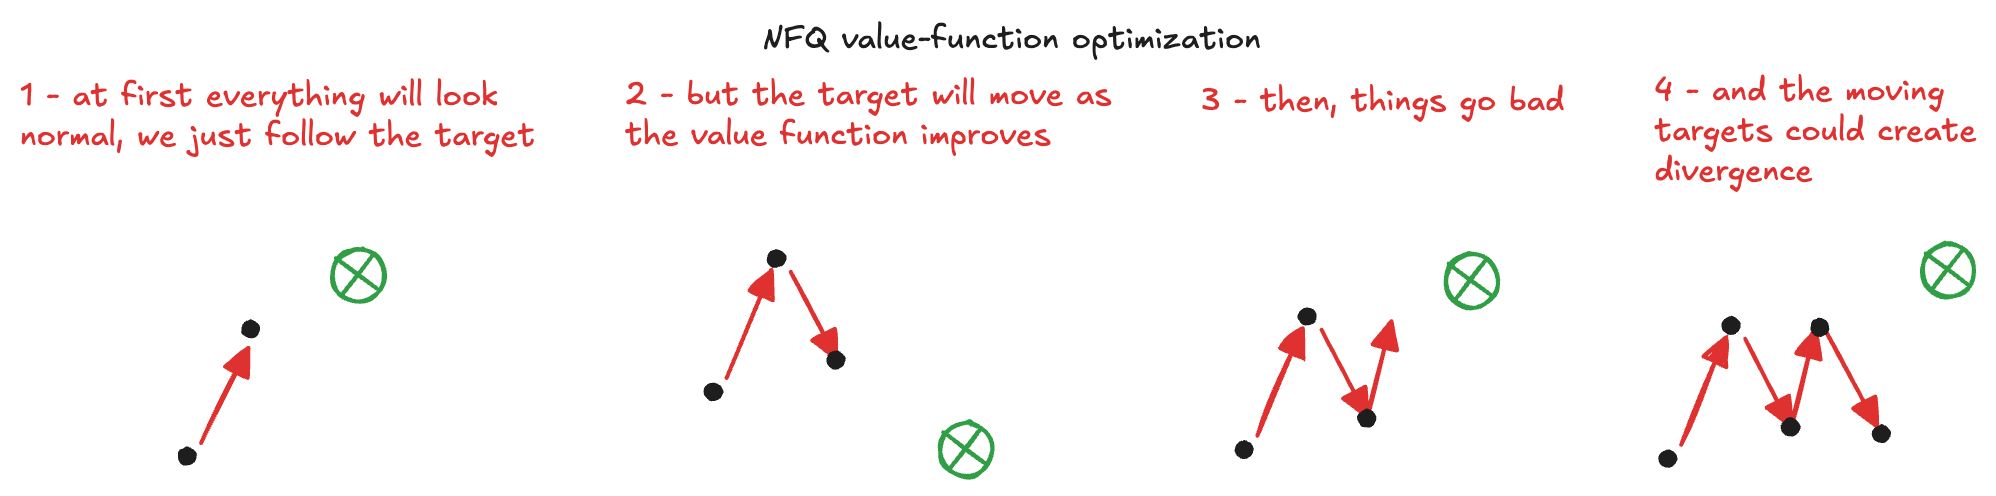

The issue is that the same network is used both to make the current prediction and to construct the target. When the network is updated, the prediction changes, but the target can change as well, because it depends on the estimated value of the next state. The optimizer is therefore trying to move toward a target that keeps moving. A **target network** makes this process more stable. The idea is to keep two copies of the same neural network. The first is the **online network** and it is updated at every training step. The second is the **target network** and it is used only to compute the bootstrapped targets:

 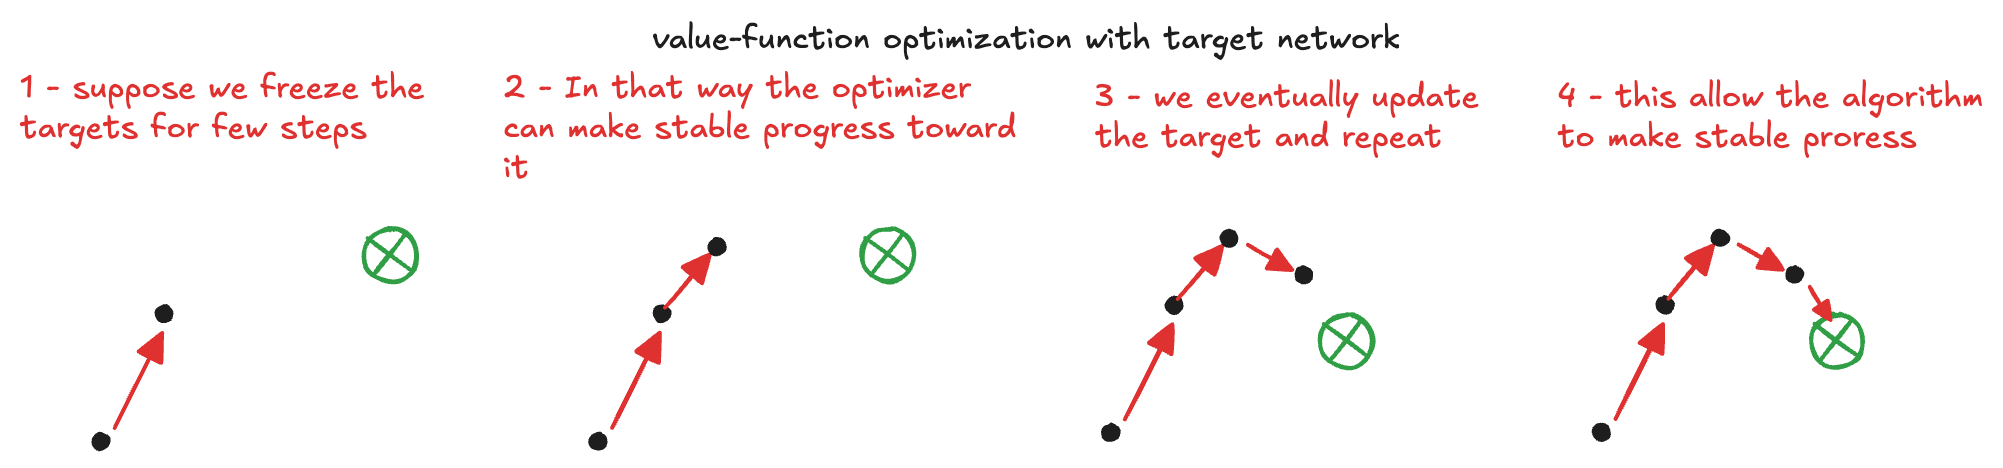

The target network is not a different architecture. It is a delayed copy of the online network. Every few steps, we copy the weights of the online network into the target network. Between two copies, the target network remains fixed, so the targets remain more stable. **This turns training into a sequence of smaller supervised learning problems**: for a while, the labels are fixed, the online network moves toward them, and only later are the labels updated. With a target network, the DQN loss becomes:

$\displaystyle \mathcal{L}(\theta_{\text{online}}) = \mathbb{E}_{(s,a,r,s') \sim U(\mathcal{D})} \Big[ \big( r + \gamma \max_{a'} Q_{\theta_{\text{target}}}(s',a') - Q_{\theta_{\text{online}}}(s,a) \big)^2 \Big]$

The semi-gradient idea is the same as in NFQ. The bootstrapped target, now computed with the frozen target network, is treated as a constant.  Freezing the target network does not make the targets perfectly correct, but it makes them stable for long enough that optimization can make meaningful progress. To implement this idea, we use the same network architecture as before and create two instances of it, one online network for learning, and one target network for computing targets:

In [26]:
# The online network learns Q-values through gradient updates.
online_q = create_network(cart_pole, hidden_sizes=(512, 128))

# The target network has the same architecture and provides bootstrapped targets.
target_q = create_network(cart_pole, hidden_sizes=(512, 128))

# Start with identical parameters; later, synchronize them periodically.
target_q.load_state_dict(online_q.state_dict());

The online network is the one whose parameters are updated during training, so we attach an optimizer to it:

In [27]:
# Attach the optimizer to the online network: only its parameters are learned.
# The target network is updated by copying parameters from the online network.
optimizer = create_optimizer(online_q, learning_rate=0.007)

The target network is not optimized directly. Instead, we periodically **copy the weights** of the online network into it:

In [28]:
def update_target(online_q, target_q):
    # Copy the online network's current parameters into the target network.
    # Between these updates, the target network remains fixed.
    target_q.load_state_dict(online_q.state_dict())

The online network learns the action values, while the target network is used only to construct training targets. As in NFQ, we can use a greedy policy to select the action with the highest value estimated by the online network:

In [29]:
# Select actions greedily using the online network.
dqn_policy = GreedyPolicy(online_q)

Using a target network makes learning more stable because the targets remain fixed for several updates. This gives the online network time to move toward them before the target values are refreshed. The trade-off is that the targets are slightly outdated. If we update the target network too rarely, **learning can become slow or biased** toward old estimates. If we update it too often, **we lose the stabilizing effect**. The **update frequency** therefore controls the balance between stability and speed. The optimization step now uses the target network to compute the value of the next state, and the online network to compute the value of the current state-action pair:

In [30]:
def optimize_dqn(batch, online_q, target_q, optimizer, gamma):
    
    # Convert the sampled transitions into tensors.
    # Actions must be integer indices for selecting Q(s, a).
    states = torch.from_numpy(batch["state"].copy()).float()
    actions = torch.from_numpy(batch["action"].copy()).long()
    rewards = torch.from_numpy(batch["reward"].copy()).float()
    next_states = torch.from_numpy(batch["next_state"].copy()).float()
    failures = torch.from_numpy(batch["failure"].copy()).float()

    # Build fixed targets using the target network, without tracking gradients.
    # True terminal transitions use only the immediate reward.
    with torch.no_grad():
        max_q_next = target_q(next_states).max(dim=1).values
        target = rewards + gamma * max_q_next * (1.0 - failures)

    # Use the online network to estimate Q(s, a) for each action taken.
    q_current = online_q(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Compute the TD errors and their mean squared value.
    td_errors = target - q_current
    loss = td_errors.pow(2).mean()

    # Update only the online network's parameters.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Return the errors as NumPy values for later use in prioritized replay.
    return td_errors.detach().numpy()

### Exploration Strategies

Exploration is essential in reinforcement learning, because the agent must try different actions in order to discover which ones lead to better long-term outcomes. In NFQ, we used an epsilon-greedy strategy with a fixed exploration rate. This is simple, but it keeps the same amount of randomness throughout training. For DQN, we use a **decaying epsilon-greedy strategy**:

In [31]:
class DecayingEpsilonGreedyPolicy:
    def __init__(self, env, q,
                 epsilon_max=1.0, epsilon_min=0.01, epsilon_decay_steps=10_000):
        
        # Create the policies used for exploration and exploitation.
        self.random_policy = RandomPolicy(env)
        self.greedy_policy = GreedyPolicy(q)

        # Gradually reduce exploration using logarithmically spaced rates.
        self.epsilons = np.logspace(
            start=np.log10(epsilon_max),
            stop=np.log10(epsilon_min),
            num=epsilon_decay_steps,
        )
        self.step = 0

    def select_action(self, state):
        
        # Follow the schedule, then maintain its final exploration rate.
        if self.step < len(self.epsilons):
            epsilon = float(self.epsilons[self.step])
        else:
            epsilon = float(self.epsilons[-1])

        self.step += 1

        # Explore with probability epsilon; otherwise act greedily.
        if random.random() < epsilon:
            return self.random_policy.select_action(state)

        return self.greedy_policy.select_action(state)

The fixed exploration rate treats the beginning and end of training alike. A decaying schedule instead **encourages exploration early**, when the network knows little, and gradually gives more weight to the greedy policy. The logarithmic schedule decreases the exploration rate rapidly at first, then more slowly. After the schedule ends, exploration remains at its minimum rate rather than stopping entirely:

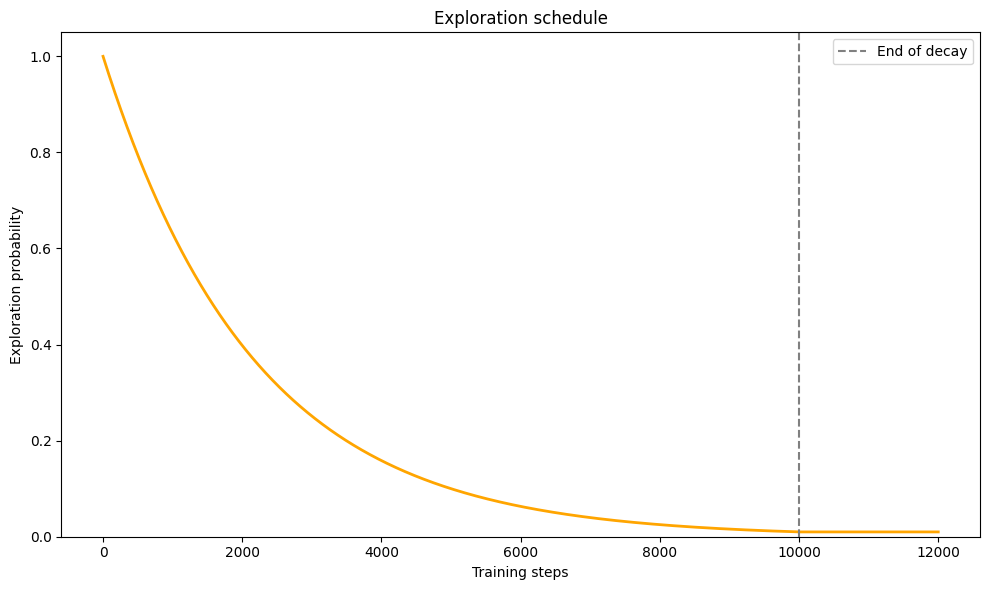

In [32]:
# Create a policy whose exploration rate decreases from 100% to 1%.
epsilon_decay_steps = 10_000
exploratory_policy = DecayingEpsilonGreedyPolicy(
    cart_pole,
    online_q,
    epsilon_max=1.0,
    epsilon_min=0.01,
    epsilon_decay_steps=epsilon_decay_steps,
)

# Read the rates stored by the policy without advancing its step counter.
epsilons = exploratory_policy.epsilons

# Extend the plot to show that exploration continues at the final rate.
exploration_rates = np.concatenate([
    epsilons,
    np.full(2_000, epsilons[-1]),
])
steps = np.arange(len(exploration_rates))

# Plot the probability of choosing a random action during training.
plt.figure(figsize=(10, 6))
plt.plot(steps, exploration_rates, 
         color="orange", linewidth=2)

# Mark where decay ends and the exploration rate becomes constant.
plt.axvline(epsilon_decay_steps,
            color="gray", linestyle="--", label="End of decay")

plt.title("Exploration schedule")
plt.xlabel("Training steps")
plt.ylabel("Exploration probability")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### Algorithm

DQN is among the most influential algorithms in deep reinforcement learning. It showed that a neural network could learn effective value functions directly from **high-dimensional observations**, such as raw pixels. This result led to **human-level, and in some cases superhuman, performance** on several games in the [**Atari benchmark**](./papers/2015%20-%20Human-level%20control%20through%20deep%20reinforcement%20learning.pdf). We now implement the full training loop. Compared with the simplified NFQ implementation, DQN introduces the three key changes: a **replay buffer**, a **target network**, and a **decaying ε-greedy exploration strategy**. The algorithm proceeds as follows:

1. Collect a transition by interacting with the environment and store it in the replay buffer
2. Sample a mini-batch uniformly at random from the replay buffer
3. Use the target network to compute the next-state Q-values, and the online network to compute the current-state Q-values
4. Compute the loss and update only the online network
5. Periodically copy the online network weights into the target network

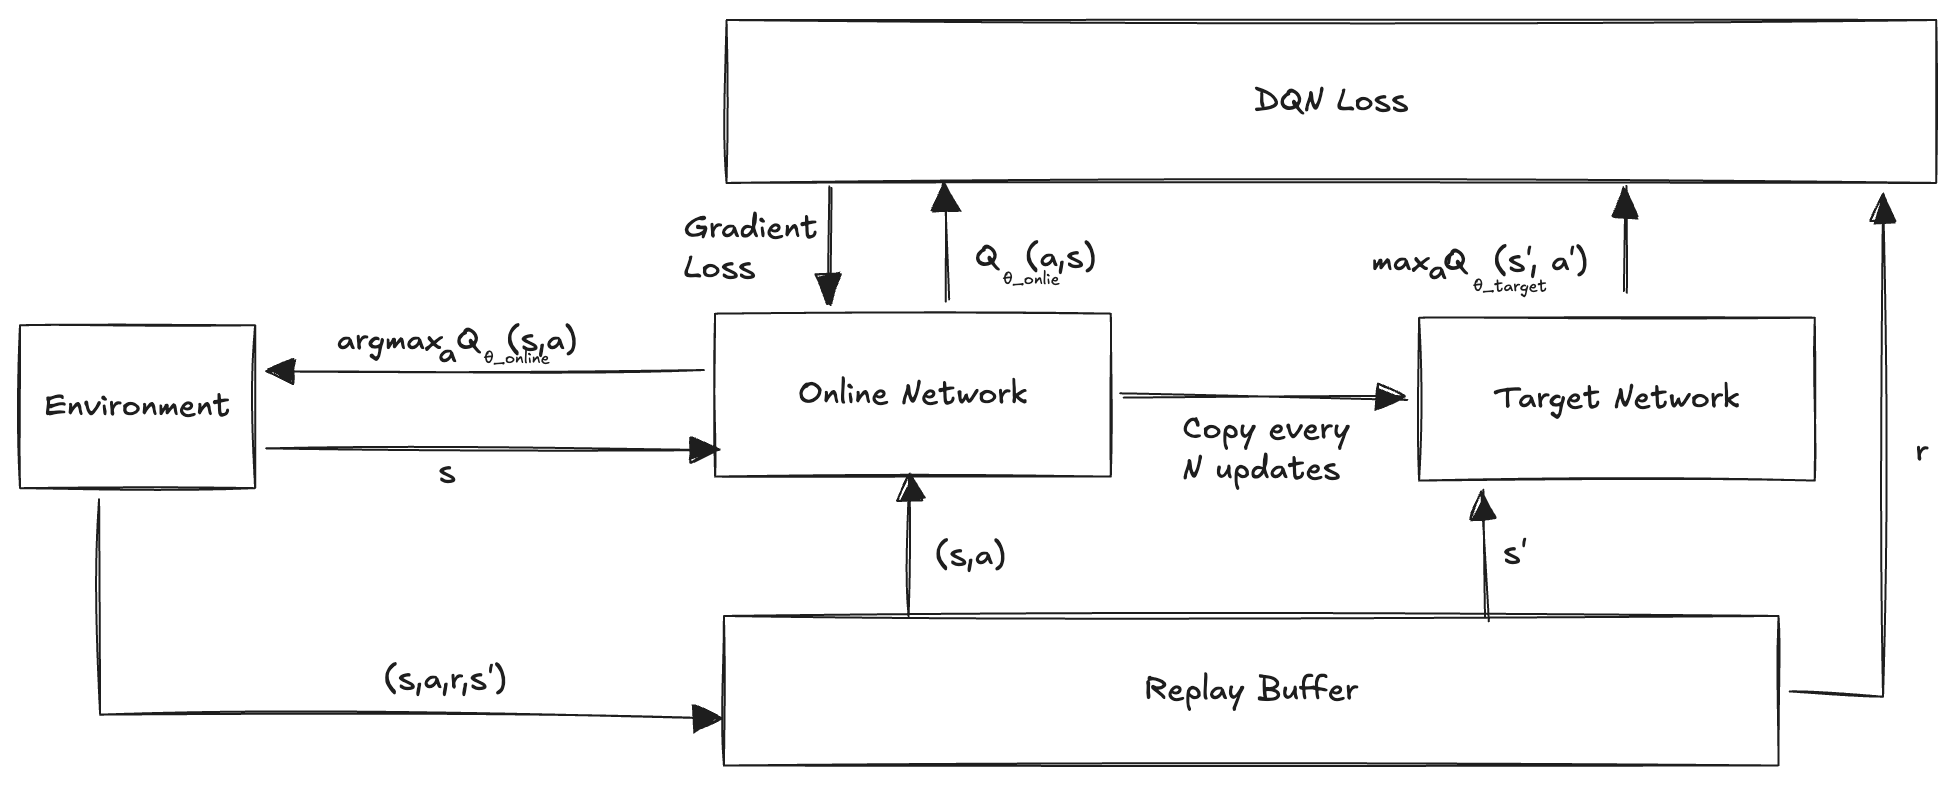

We can now write the DQN training loop. The agent first fills the replay buffer with a minimum number of transitions, then alternates between collecting new experience, sampling mini-batches for optimization, and periodically synchronizing the target network with the online network:

In [33]:
def dqn(env, max_episodes,
        hidden_sizes=(512, 128),
        learning_rate=0.0005, batch_size=32, optimization_step=optimize_dqn,
        gamma=0.99,
        epsilon_max=1.0, epsilon_min=0.01, epsilon_decay_steps=10_000,
        memory_size=100_000, memory_start_size=1000,
        target_update_steps=100,
        evaluation_episodes=10, seed=34, verbose=True):
    
    # Seed network initialization, exploration and replay sampling.
    seed_environment(env, seed)
    random.seed(seed)
    np.random.seed(seed)

    # Create the online network and an initially identical target network.
    online_q = create_network(env, hidden_sizes=hidden_sizes)
    target_q = create_network(env, hidden_sizes=hidden_sizes)
    update_target(online_q, target_q)
    optimizer = create_optimizer(online_q, learning_rate=learning_rate)

    # Create the greedy and exploratory policies, which share the same 
    # online network.
    greedy_policy = GreedyPolicy(online_q)
    exploratory_policy = DecayingEpsilonGreedyPolicy(
        env,
        online_q,
        epsilon_max=epsilon_max,
        epsilon_min=epsilon_min,
        epsilon_decay_steps=epsilon_decay_steps,
    )

    # Create the replay memory and track training progress.
    replay_memory = create_replay_memory(env, memory_size)

    # Track the score and training steps for each episode.
    step = 0
    scores, training_steps = [], []

    # Run the episodes, collecting transitions and fitting the online network.
    for episode in range(max_episodes):

        # Start a new episode.
        state, _ = env.reset()
        done = False

        # Run the episode until termination or truncation.
        while not done:

            # Select an action using decaying epsilon-greedy exploration
            action = exploratory_policy.select_action(state)

            # Take a step in the environment and store the transition.
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Store the transition; only termination disables bootstrapping.
            experience = (state, action, reward, next_state, terminated)
            store_experience(replay_memory, experience)
            step += 1

            # Sample and learn once enough transitions have been collected.
            if replay_memory["entries"] >= max(memory_start_size, batch_size):
                batch = sample_experiences(replay_memory, batch_size)
                optimization_step(batch, online_q, target_q, optimizer, gamma)

            # Periodically copy the online parameters into the target network.
            if step % target_update_steps == 0:
                update_target(online_q, target_q)

            state = next_state

        # Evaluate the greedy policy
        score = evaluate(env, greedy_policy, episodes=evaluation_episodes)
        scores.append(score)
        training_steps.append(step)

        # Show the current episode and score, overwriting the previous line.
        if verbose:
            print(f"Episode {episode + 1:03}, score {score:05.1f}",
                  end="\r", flush=True)

    print()

    # Return the learning curve, cumulative training steps
    # and trained online network.
    return {
        "scores": np.asarray(scores),
        "steps": np.asarray(training_steps),
        "network": online_q,
    }

### Solve Cart-Pole

We can now apply DQN to the Cart-Pole environment. As before, the agent’s performance depends strongly on the choice of hyperparameters, so careful tuning is important. A single run is not enough to compare DQN and NFQ reliably. We repeat training with the same set of seeds and inspect both the average learning curves and their variability. The algorithms can differ in episode length and update frequency, so equal episode counts do not imply equal numbers of transitions or equal computational cost. The experiment also records cumulative training steps for a more detailed comparison. Then we run the experiment for the DQN agent on the cart-pole environment:

In [35]:
dqn_results = experiment(
    name="dqn_cartpole",
    env=cart_pole,
    algorithm=dqn,
    max_episodes=500,
    # Shared learning parameters.
    hidden_sizes=(512, 128),
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=128,
    # DQN-specific parameters.
    memory_size=100_000,
    memory_start_size=1000,
    target_update_steps=100,
    epsilon_max=1.0,
    epsilon_min=0.01,
    epsilon_decay_steps=10_000
)

Loaded results from temp/dqn_cartpole_results.joblib


To compare the algorithms, we plot their mean learning curves together with the minimum–maximum range across random seeds, showing both performance and variability. We define a reusable plotting function because we will make the same comparison for several pairs of algorithms. The curves are drawn against training episodes:

In [36]:
def plot_comparison(first_results, second_results,
                    first_label, second_label,
                    first_color, second_color,):

    plt.figure(figsize=(12, 6))

    # Place each moving average at the final episode of its window.
    first_episodes = (
        np.arange(len(first_results["mean_score"]))
        + first_results["smoothing_window"]
    )
    second_episodes = (
        np.arange(len(second_results["mean_score"]))
        + second_results["smoothing_window"]
    )

    # Plot the first algorithm's mean and range across seeds.
    plt.plot(
        first_episodes, first_results["mean_score"],
        color=first_color, linewidth=2, label=f"{first_label} mean",
    )
    plt.fill_between(
        first_episodes,
        first_results["min_score"], first_results["max_score"],
        color=first_color, alpha=0.20, label=f"{first_label} range",
    )

    # Plot the second algorithm's mean and range across seeds.
    plt.plot(
        second_episodes, second_results["mean_score"],
        color=second_color, linewidth=2, label=f"{second_label} mean",
    )
    plt.fill_between(
        second_episodes,
        second_results["min_score"], second_results["max_score"],
        color=second_color, alpha=0.20, label=f"{second_label} range",
    )

    # The shaded ranges show variability, not confidence intervals.
    plt.title(f"{second_label} vs {first_label}")
    plt.xlabel("Training episodes")
    plt.ylabel("Evaluation return")
    plt.legend()
    plt.tight_layout()
    plt.show()

We now compare NFQ and DQN by plotting their mean evaluation returns and the ranges across random seeds, showing both learning progress and variability between runs:

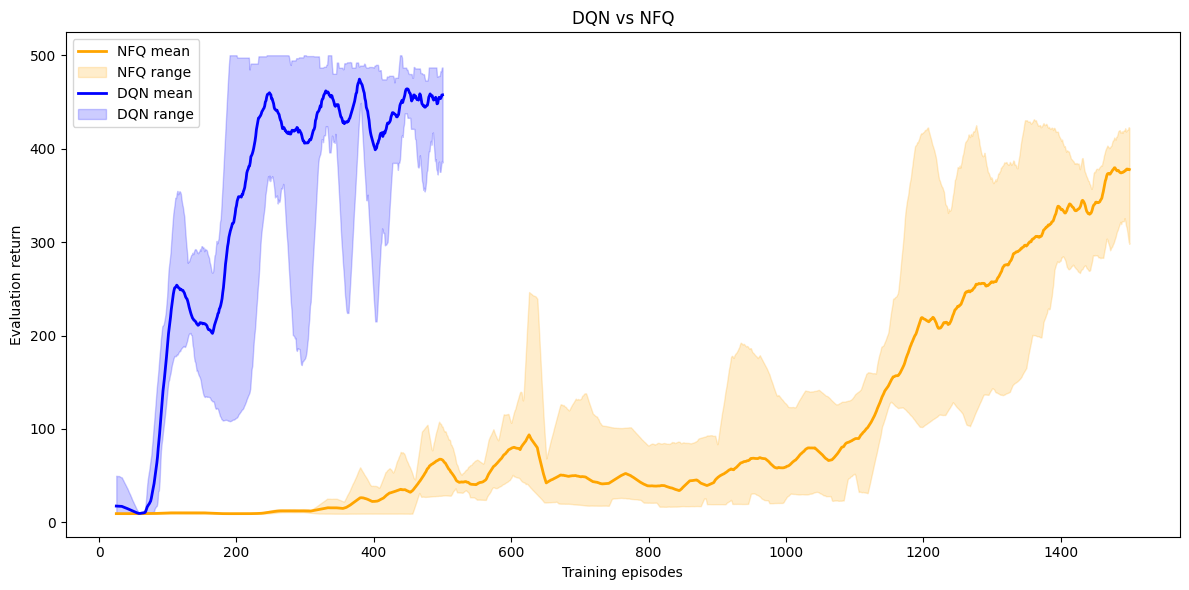

In [37]:
plot_comparison(
    nfq_results,
    dqn_results,
    first_label="NFQ",
    second_label="DQN",
    first_color="orange",
    second_color="blue"
)

The comparison suggests that **DQN learns much faster than NFQ** on Cart-Pole. The DQN curve starts improving within the first few dozen episodes, while NFQ needs several hundred episodes before its average score rises substantially. This is consistent with the role of experience replay and the target network: the replay buffer provides more diverse mini-batches, and the target network makes the bootstrapped targets more stable. At the same time, the shaded region shows that the **variability across seeds is still large**. Some runs improve quickly, while others remain much weaker or fluctuate substantially. This is an important reminder that value-based deep reinforcement learning can remain sensitive to initialization, exploration, and the particular sequence of experiences collected during training.

## Beyond DQN: Improving Value Estimation and Learning Efficiency

Experience replay and target networks make DQN a practical approach to learning action values with neural networks. However, they do not resolve every difficulty: value estimates can be overly optimistic, uniform replay can spend updates on transitions that offer little new information, and the network may fail to exploit structure shared across action values. Several extensions address these limitations from different directions. Double DQN separates action selection from action evaluation to reduce overestimation. Prioritized Experience Replay directs more updates towards transitions with larger TD errors. Dueling networks separate the value of a state from the relative advantages of its actions. These ideas modify different components of DQN and can be combined. Their benefits are not universal, however: they depend on the task and training conditions. We therefore examine both why each extension can help and how to evaluate its contribution to learning efficiency, stability and final performance.

### Double Deep Q-Learning (DDQN)

Q-learning tends to **overestimate action values**, a phenomenon known as **maximization bias**. This bias appears because the target uses a maximum over estimated values. When those estimates are noisy, the maximum is more likely to select an action whose value has been overestimated. DQN has the same problem, because it uses the same off-policy target with a max operator. To see where the bias comes from, we can rewrite the maximum explicitly as an action selection step followed by an action evaluation step:

$\displaystyle \max_{a'} Q_{\theta_{\text{target}}}(s',a') = Q_{\theta_{\text{target}}}\big(s', \arg\max_{a'} Q_{\theta_{\text{target}}}(s',a')\big)$

This expression shows that the max operation is really doing two things at once. First, it selects the action with the highest estimated value in the next state. Then, it uses the value of that same action to build the target. In standard DQN, both steps are performed using the target network. The same estimates are used both to choose the action and to evaluate it. If those estimates contain noise, the selected action is likely to be one whose value is too high, and this produces a positive bias in the target. [**Double Q-learning**](./papers/2015%20-%20Deep%20Reinforcement%20Learning%20with%20Double%20Q-learning.pdf) addresses this problem by separating action selection from action evaluation. One estimator selects the action, while another estimator evaluates that action. In deep reinforcement learning, we can implement this idea without adding extra networks. DQN already has two networks: the online network and the target network. DDQN uses them as follows:

- the **online network** selects the best next action
- the **target network** evaluates the value of that selected action

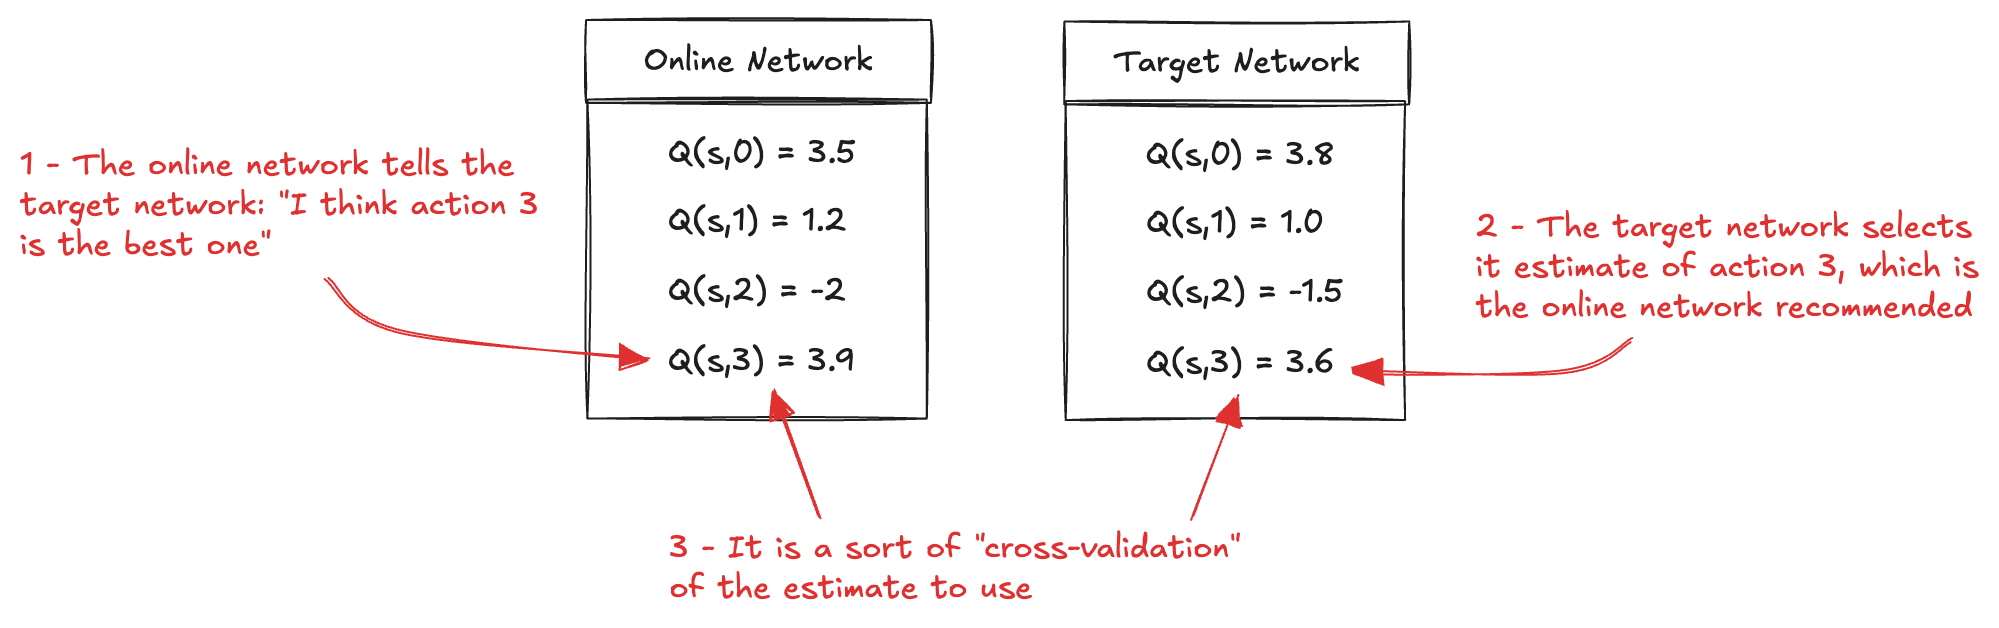

The DDQN target therefore differs from the DQN target only in how the next-state action is selected. The online network chooses the action, while the target network assigns its value:

$\displaystyle \mathcal{L}(\theta_{\text{online}}) = \mathbb{E}_{(s,a,r,s') \sim U(\mathcal{D})} \Big[ \big( r + \gamma Q_{\theta_{\text{target}}}\big(s', \arg\max_{a'} Q_{\theta_{\text{online}}}(s',a')\big) - Q_{\theta_{\text{online}}}(s,a) \big)^2 \Big]$

This small change reduces overestimation. The online network may still choose an action whose value it overestimates, but the target value is computed by the separate target network. As a result, the action selection and action evaluation errors are partially decoupled. We can now modify the optimization step to implement this idea:

In [38]:
def optimize_ddqn(batch, online_q, target_q, optimizer, gamma):

    # Convert the sampled transitions into tensors.
    states = torch.from_numpy(batch["state"].copy()).float()
    actions = torch.from_numpy(batch["action"].copy()).long()
    rewards = torch.from_numpy(batch["reward"].copy()).float()
    next_states = torch.from_numpy(batch["next_state"].copy()).float()
    failures = torch.from_numpy(batch["failure"].copy()).float()

    # Compute fixed targets: gradients must not flow through them.
    with torch.no_grad():

        # Use the online network to SELECT the best next action.
        best_actions = online_q(next_states).argmax(dim=1)

        # Use the target network to EVALUATE that same action.
        # gather selects one Q-value per transition.
        q_next = target_q(next_states).gather(
            1, best_actions.unsqueeze(1)
        ).squeeze(1)

        # Bootstrap unless the transition is terminal.
        # Truncated episodes still use the estimated next-state value.
        target = rewards + gamma * q_next * (1.0 - failures)

    # Select the online predictions for the actions actually taken.
    q_current = online_q(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    # Measure the difference between targets and current predictions.
    td_errors = target - q_current
    loss = td_errors.pow(2).mean()

    # Adjust the online network to reduce the prediction error.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Return the pre-update TD errors, without gradient tracking.
    # Prioritized replay will use their magnitudes to update priorities.
    return td_errors.detach().numpy()

### Lunar Lander

To explore the improvements introduced by DDQN, we will use a more demanding control problem: Lunar Lander. The goal of Lunar Lander environment is to guide a spacecraft to a safe landing on a designated pad. The agent must control its descent, correct its horizontal motion and keep it upright by choosing among four discrete actions: fire the main engine, fire either side engine, or do nothing. Its observations describe position, velocity, orientation and ground contact, while the reward encourages a controlled landing and penalizes crashes and engine use:

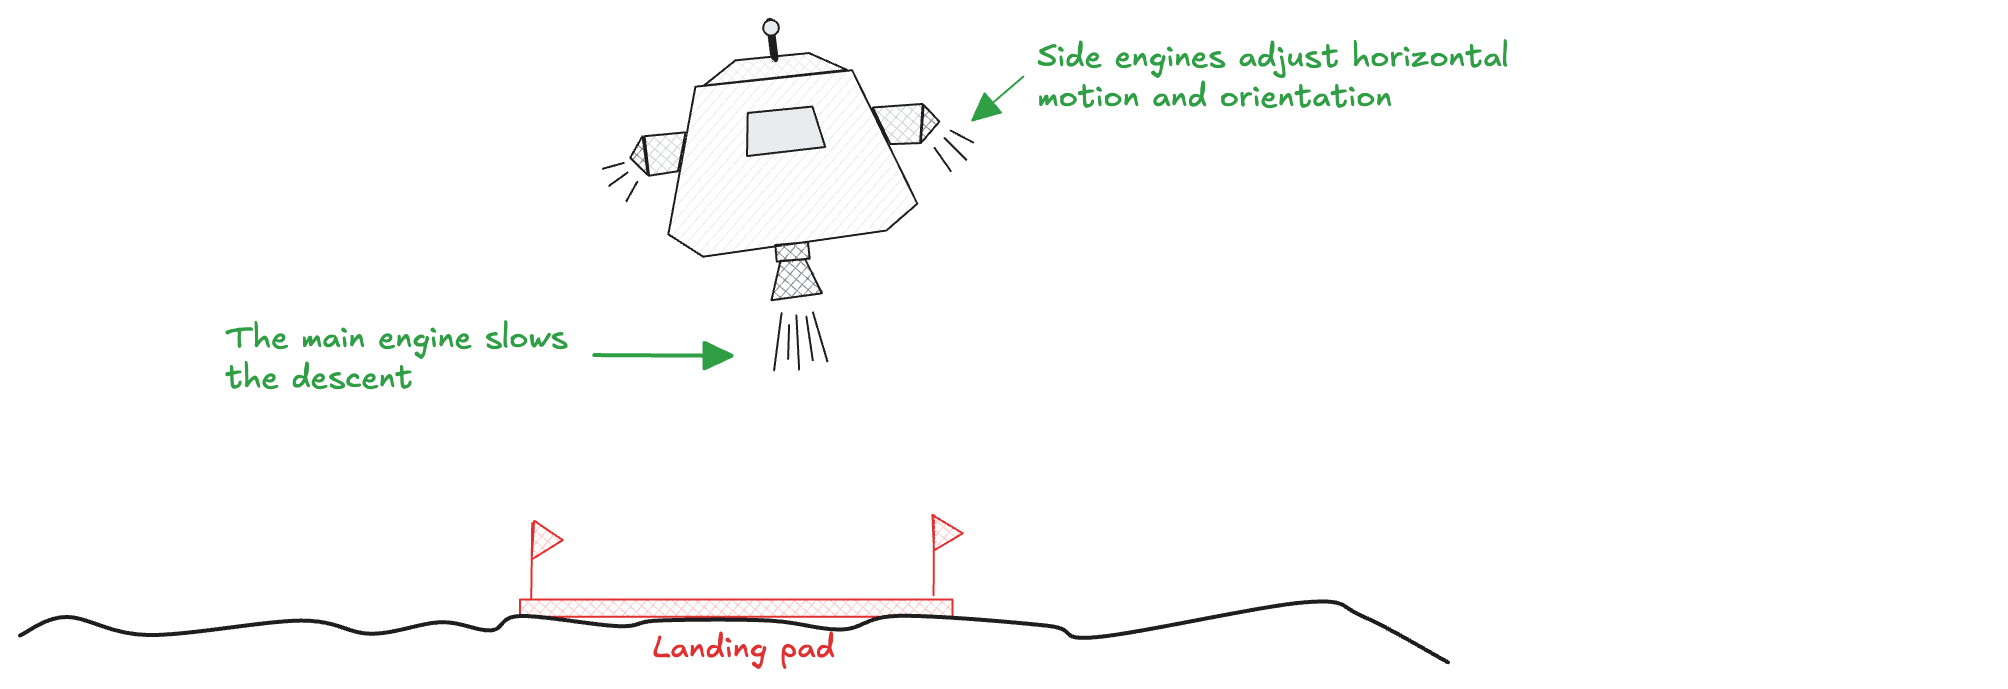

The state is a vector with **eight components**: six continuous variables describing the lander’s motion and two binary indicators describing ground contact:

- the horizontal position relative to the landing pad
- the vertical position relative to the landing pad
- the horizontal velocity
- the vertical velocity
- the angle with respect to the vertical
- the angular velocity
- whether the left leg touches the ground
- whether the right leg touches the ground

In every state, the agent can choose among **four discrete actions**:

- action 0 leaves all engines off
- action 1 fires the left orientation engine
- action 2 fires the main engine
- action 3 fires the right orientation engine

The agent selects which engine to fire, but does not control its throttle. The main engine primarily controls the descent, while the side engines affect horizontal motion and rotation. The reward is not constant. Intermediate rewards encourage progress towards the pad, lower speed and a more upright orientation. Establishing ground contact adds a bonus; losing contact removes it. Engine use incurs a small penalty at each step: 0.3 for the main engine and 0.03 for a side engine. The terminal reward is +100 when the lander comes to rest, or −100 for a crash or leaving the horizontal boundaries. Consequently, the episode return measures landing quality and control effort rather than simply episode length.

The episode terminates when the lander crashes, leaves the horizontal boundaries or comes to rest. Episodes that continue are truncated after 1000 steps. The conventional target is an average return of at least 200, which is a performance threshold, not a maximum score. 

The discrete-action LunarLander environment is available in the Gymnasium library:

In [40]:
lunar_lander = gymnasium.make("LunarLander-v3", render_mode="rgb_array")

We can get the state space and the action space sizes of the environment:

In [41]:
print('State Space: ', lunar_lander.observation_space.shape);
print('Action Space: ', lunar_lander.action_space.n);

State Space:  (8,)
Action Space:  4


Before training, we visualize an episode with a random policy to see the lander’s dynamics and why a safe landing requires coordinated engine control:

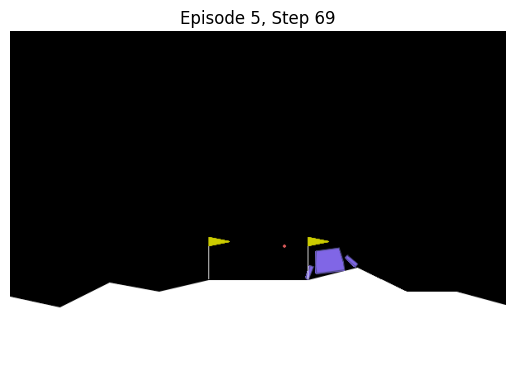

In [42]:
random_policy = RandomPolicy(lunar_lander);
show_policy(lunar_lander, random_policy, n_episodes=5, max_steps=500);

agent_score = evaluate(cart_pole, nfq_policy, episodes=10)

Compared with Cart-Pole, the agent must coordinate more aspects of motion and balance competing objectives. This makes LunarLander a useful setting for investigating whether Double DQN extension improves learning speed, stability and final performance. We will first establish a DQN baseline, then compare each extension under the same experimental conditions. 

In [ ]:
dqn_lunar_results = experiment(

    # 
    name="dqn_lunarlander",
    env=lunar_lander,
    algorithm=dqn,
    max_episodes=250,

    # Repeat training across seeds and evaluate without exploration.
    seeds=(12, 34, 56, 78, 90),
    evaluation_episodes=10,
    smoothing_window=25,

    # Network architecture and learning parameters.
    hidden_sizes=(512, 128),
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=32,

    # Replay memory and target-network synchronization.
    memory_size=100_000,
    memory_start_size=1000,
    target_update_steps=100,

    # Gradually reduce the probability of choosing a random action.
    epsilon_max=1.0,
    epsilon_min=0.01,
    epsilon_decay_steps=10_000,
)

Loaded results from temp/dqn_lunarlander_results.joblib


We reuse the DQN training loop, replacing its default optimization step with optimize_ddqn. All other settings, including the replay memory, exploration schedule and network architecture, remain identical to the DQN baseline:

In [42]:
ddqn_lunar_results = experiment(
    name="ddqn_lunarlander",
    env=lunar_lander,

    # Reuse the DQN training loop with the Double DQN update.
    algorithm=dqn,
    optimization_step=optimize_ddqn,
    max_episodes=250,

    # Keep the same seeds and evaluation settings as the DQN baseline.
    seeds=(12, 34, 56, 78, 90),
    evaluation_episodes=10,
    smoothing_window=25,

    # Keep the network architecture and learning parameters unchanged.
    hidden_sizes=(512, 128),
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=32,

    # Store past transitions and periodically update the target network.
    memory_size=100_000,
    memory_start_size=1000,
    target_update_steps=100,

    # Reduce exploration using the same schedule as the DQN baseline.
    epsilon_max=1.0,
    epsilon_min=0.01,
    epsilon_decay_steps=10_000,
)

Loaded results from temp/ddqn_lunarlander_results.joblib


To see whether separating action selection from action evaluation improves learning, we compare the DQN and DDQN learning curves across the same set of random seeds:

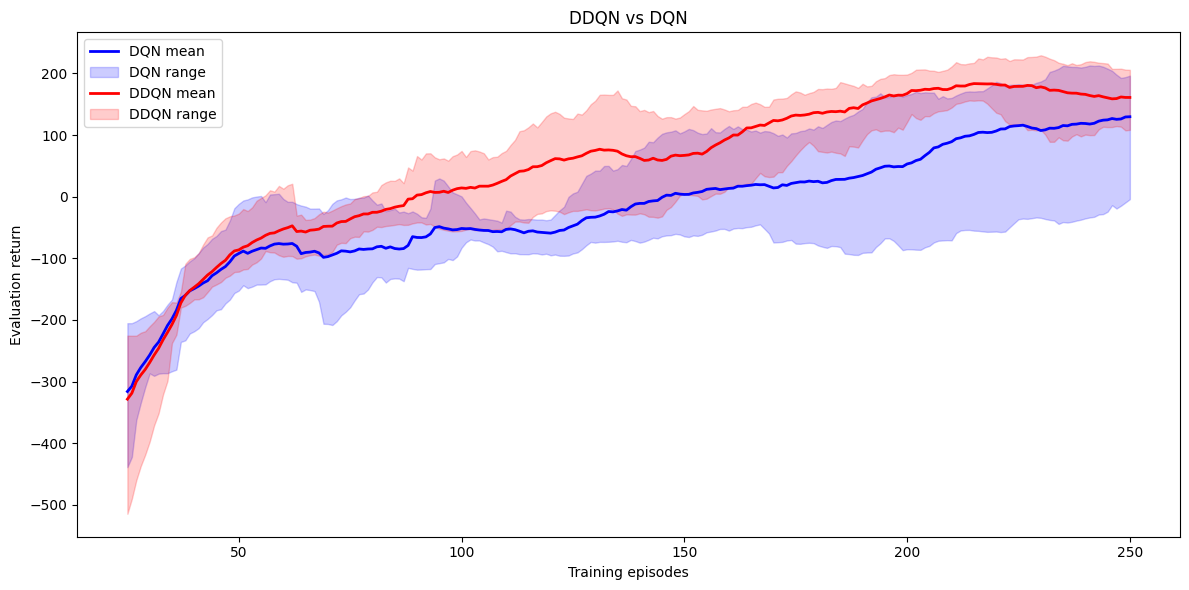

In [43]:
plot_comparison(
    dqn_lunar_results,
    ddqn_lunar_results,
    first_label="DQN",
    second_label="DDQN",
    first_color="blue",
    second_color="red",
)

On LunarLander, DDQN learns faster than DQN and maintains a higher mean evaluation return through most of training.  The shaded regions show substantial variability across random seeds. In the later stages, DDQN has a narrower range and a higher minimum return, suggesting more consistent performance across the tested runs. These results suggest that separating action selection from action evaluation is beneficial in this experiment. They do not, by themselves, demonstrate that reduced overestimation caused the improvement: the curves measure returns, not value-estimation bias.

### Prioritized Experience Replay (PER)

So far, transitions have been sampled uniformly from the replay buffer. This is simple and useful, because it breaks temporal correlations between consecutive experiences. However, uniform sampling also treats all transitions as equally informative. This is not always ideal. Some transitions are already well understood by the agent and produce very small updates. Others are **surprising**: the target value is very different from the value currently predicted by the network. These surprising transitions are often more useful for learning. The key idea of [**Prioritized Experience Replay (PER)**](./papers/(2016)%20-%20Prioritized%20Experience%20Replay.pdf) is to sample important transitions more often. A natural measure of surprise is the absolute TD error (here written with the DDQN target):

$\displaystyle |\delta| = \big| r + \gamma Q_{\theta_{\text{target}}}\big(s', \arg\max_{a'} Q_{\theta_{\text{online}}}(s',a')\big) - Q_{\theta_{\text{online}}}(s,a) \big|$

A large TD error means that the prediction was far from the target, so replaying that transition may produce a useful update. PER therefore assigns each transition a priority based on its TD error:

$\displaystyle p_i = |\delta_i| + \epsilon_p$

A small positive constant keeps every transition eligible for sampling, even when its TD error is zero. The offset should be chosen relative to the scale of the TD errors. For rewards of order one, a possible starting value is:

$\displaystyle \epsilon_p = 0.01$

An excessively small offset can make low-error transitions unlikely to be replayed, although their sampling probabilities also depend on the other priorities and the strength of prioritization. To implement prioritized replay, we extend the experience type with two fields: the priority, which determines the sampling probability, and the importance-sampling weight, which is computed when sampling and later used to weight the loss:

In [44]:
def create_prioritized_experience_type(env):

    # Match the dimensions of the environment's observations.
    state_shape = env.observation_space.shape

    # Keep the original transition fields and add priority and weight.
    return np.dtype([
        ("state", np.float32, state_shape),      # State before the action.
        ("action", np.int8),                     # Discrete action taken.
        ("reward", np.float32),                  # Immediate reward received.
        ("next_state", np.float32, state_shape), # State after the action.
        ("failure", np.int8),                    # True termination, not truncation.

        # Stored priority: updated using the most recent measured TD error.
        ("priority", np.float32),

        # Importance-sampling weight: computed for the sampled batch,
        # then used to adjust this transition's contribution to the loss.
        ("weight", np.float32),
    ])

The replay memory keeps the same circular-buffer layout as before. We add a counter of how many times each stored transition has been replayed: it plays no role in the algorithm, but it will let us see where prioritized sampling concentrates the updates:

In [45]:
def create_prioritized_replay_memory(env, memory_size):

    # Define the transition fields, including priority and importance weight.
    experience_type = create_prioritized_experience_type(env)

    # Allocate fixed-size storage. Its contents are initially uninitialized,
    # so sampling must use only the occupied entries.
    buffer = np.empty(memory_size, dtype=experience_type)

    # Track how often each transition is sampled, counting repeated draws.
    # These counters are for diagnostics; they do not affect prioritization.
    sample_counts = np.zeros(memory_size, dtype=np.int64)

    return {
        "size": memory_size,             # Maximum number of stored transitions.
        "buffer": buffer,                # Circular storage for transitions.
        "index": 0,                      # Slot where the next transition is stored.
        "entries": 0,                    # Number of currently occupied slots.
        "sample_counts": sample_counts,  # Sampling count for each stored transition.
    }

New transitions receive the largest priority currently stored in the memory, encouraging them to be sampled before their TD error has been measured. This increases their chance of early replay, but does not guarantee that every transition will be sampled. We use the current maximum, rather than the largest priority ever observed. As learning progresses, priorities may decrease; retaining an outdated maximum could give new transitions an unnecessarily large advantage over existing ones.The insertion function receives the replay memory explicitly:

In [46]:
def store_prioritized_experience(replay_memory, experience):

    # A new transition has no measured TD error yet.
    # Give it the largest priority among the stored transitions to encourage
    # early sampling. This increases its chance of replay, but guarantees none.
    entries = replay_memory["entries"]

    if entries > 0:
        # Ignore unused slots, whose contents are still uninitialized.
        priorities = replay_memory["buffer"]["priority"][:entries]
        priority = float(priorities.max())
    else:
        # Use a positive initial priority when the memory is empty.
        priority = 1.0

    # Extend the transition with its priority and a placeholder weight.
    # The actual importance weight will be computed when sampling a batch.
    prioritized_experience = experience + (priority, 1.0)

    # Store the transition using the existing circular-buffer operation.
    # This also advances the index to the next slot.
    store_experience(replay_memory, prioritized_experience)

    # Recover the slot just written, accounting for wraparound.
    written_index = (
        replay_memory["index"] - 1
    ) % replay_memory["size"]

    # Reset its replay counter: the new transition has never been sampled,
    # even if it overwrote an older transition that had been replayed.
    replay_memory["sample_counts"][written_index] = 0

When sampling a mini-batch, priorities are converted into sampling probabilities:

$\displaystyle P(i)=\frac{p_i^\alpha}{\sum_k p_k^\alpha}$

The hyperparameter controls how strongly priorities affect sampling. When it is 0, all transitions are sampled uniformly. When it is 1, sampling is fully proportional to the priorities. Intermediate values create a compromise between uniform replay and greedy prioritization. This makes sampling stochastic: **higher-priority transitions are more likely to be selected, but lower-priority transitions can still be replayed**. Prioritized sampling improves learning efficiency, but it also introduces bias. Since **high-error transitions are over-represented**, the gradient computed from a mini-batch is no longer an unbiased estimate of the gradient we would obtain under uniform sampling. To compensate for this, PER uses importance-sampling weights. Transitions that are sampled more often receive smaller weights in the loss:

$\displaystyle w_i = \left(\frac{1}{N}\frac{1}{P(i)}\right)^\beta$

Here, N is the number of transitions in the replay memory, and the other parameter controls how much bias correction is applied. When it is 0, no correction is used. When it is 1, the correction is fully applied. In practice, its value is increased gradually during training, from an initial $\beta_0$ to 1: early on the bias matters little, because the value estimates are poor anyway; it matters at the end, when we want the updates to converge to the right solution. The weights are normalized so that the largest weight in the sampled mini-batch is equal to one:

$\displaystyle w_i \leftarrow \frac{w_i}{\max_j w_j}$

This keeps the scale of the loss under control: the weights only scale updates down, and the normalization by the largest weight of the batch (rather than of the whole memory) keeps the effective step size comparable with that of uniform replay.

In [47]:
def sampling_probabilities(replay_memory, alpha):

    # Read only occupied slots, ignoring uninitialized buffer entries.
    entries = replay_memory["entries"]
    priorities = replay_memory["buffer"]["priority"][:entries]

    # Use float64 for the power and normalization operations.
    priorities = priorities.astype(np.float64)

    # Control how strongly priorities influence sampling:
    # alpha = 0 gives uniform sampling; larger values favor high priorities.
    scaled_priorities = priorities ** alpha

    # Normalize the values so that the sampling probabilities sum to one.
    probabilities = scaled_priorities / scaled_priorities.sum()

    return probabilities

We now sample a mini-batch with replacement according to the priorities, compute importance-sampling weights to adjust each transition’s contribution to the loss, and return the sampled indices so their priorities can be updated after learning:

In [48]:
def sample_prioritized_experiences(replay_memory, batch_size, alpha, beta):

    # Compute sampling probabilities from the stored priorities.
    # alpha controls how strongly high-priority transitions are favored.
    probabilities = sampling_probabilities(replay_memory, alpha)
    entries = replay_memory["entries"]

    # Sample with replacement: the same transition can appear more than once.
    # Each draw follows the probabilities computed above.
    indices = np.random.choice(
        entries,
        size=batch_size,
        replace=True,
        p=probabilities,
    )

    # Reduce the contribution of frequently sampled transitions to the loss.
    # beta controls the correction strength; beta = 0 gives equal weights.
    weights = (entries * probabilities[indices]) ** (-beta)

    # Scale the weights so that the largest in this batch is one.
    # Their relative proportions remain unchanged.
    weights = weights / weights.max()

    # Count every sampled occurrence, including repeated indices.
    # These counters are used only for diagnostics.
    np.add.at(replay_memory["sample_counts"], indices, 1)

    # Attach the weights to a separate batch, not to the stored transitions.
    batch = replay_memory["buffer"][indices].copy()
    batch["weight"] = weights

    # Return the indices too, so their priorities can be updated after learning.
    return batch, indices

After each optimization step, we refresh the sampled transitions’ priorities using the TD errors computed for that update. Because sampling is with replacement, a transition may appear several times in a mini-batch; for repeated indices, we retain the largest absolute error and add the positive priority offset. **We update only the sampled entries**, avoiding the cost of recomputing errors for the entire memory. Other transitions retain their previous priorities, which may become outdated as the network changes. A prioritization exponent below one softens the preference for high-priority transitions, while the positive offset keeps even zero-error transitions eligible for sampling. Together, these choices help prevent previously low-error experiences from being neglected:

In [49]:
def update_priorities(replay_memory, indices, td_errors, priority_epsilon):

    # Use the magnitude of each TD error as its new priority.
    # The positive offset keeps zero-error transitions eligible for sampling.
    priorities = np.abs(td_errors) + priority_epsilon

    # Sampling with replacement can select a transition more than once.
    # Identify the distinct indices and map each sample to its group.
    unique_indices, inverse = np.unique(indices, return_inverse=True)

    # For each distinct transition, keep the largest proposed priority.
    unique_priorities = np.zeros(len(unique_indices), dtype=np.float32)
    np.maximum.at(unique_priorities, inverse, priorities)

    # Replace the stored priorities, allowing them to decrease as well as grow.
    # Transitions not included in this batch retain their previous priorities.
    replay_memory["buffer"]["priority"][unique_indices] = unique_priorities


Prioritized replay changes **both the sampling distribution and the loss**. Transitions are drawn according to their priorities rather than uniformly, and each squared TD error is multiplied by an **importance-sampling weight**. Frequently sampled transitions receive smaller weights, partially compensating for their increased representation in the updates. The **Double DQN target remains unchanged**: the online network selects the next action, and the target network evaluates it:

$\displaystyle y_i = r_i + \gamma(1-d_i)\,Q_{\theta_{\mathrm{target}}}\!\left(s'_i,\arg\max_{a'}Q_{\theta_{\mathrm{online}}}(s'_i,a')\right)$

The terminal indicator is one for true termination and zero otherwise; truncation alone does not disable bootstrapping. The loss averages the weighted squared errors under the priority-based sampling distribution:

$\displaystyle \mathcal{L}(\theta_{\mathrm{online}}) = \mathbb{E}_{i\sim P}\!\left[w_i\left(y_i-Q_{\theta_{\mathrm{online}}}(s_i,a_i)\right)^2\right]$

We implement this by modifying the DDQN optimization step to apply the weights before averaging the squared errors:

In [50]:
def optimize_per(batch, online_q, target_q, optimizer, gamma):

    # Convert the sampled transitions into tensors.
    # Actions need int64 indices for the gather operation.
    states = torch.from_numpy(batch["state"].copy()).float()
    actions = torch.from_numpy(batch["action"].copy()).long()
    rewards = torch.from_numpy(batch["reward"].copy()).float()
    next_states = torch.from_numpy(batch["next_state"].copy()).float()
    failures = torch.from_numpy(batch["failure"].copy()).float()

    # Retrieve the importance weights computed during prioritized sampling.
    weights = torch.from_numpy(batch["weight"].copy()).float()

    # Build Double DQN targets without tracking gradients.
    with torch.no_grad():

        # Select the best next action using the online network.
        best_actions = online_q(next_states).argmax(dim=1)

        # Evaluate that action using the target network.
        q_next = target_q(next_states).gather(
            1, best_actions.unsqueeze(1)
        ).squeeze(1)

        # Bootstrap unless the transition is truly terminal.
        # Truncation alone does not disable the next-state estimate.
        target = rewards + gamma * q_next * (1.0 - failures)

    # Select the online predictions for the actions actually taken.
    q_current = online_q(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    # Compute one TD error per sampled transition.
    td_errors = target - q_current

    # Weight each squared error before averaging.
    # This reduces the influence of frequently sampled transitions.
    loss = (weights * td_errors.pow(2)).mean()

    # Update only the online network.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Return the unweighted, pre-update TD errors for refreshing priorities.
    # Importance weights affect the loss, not the priorities themselves.
    return td_errors.detach().numpy()

We now combine these components in an online training loop that follows DDQN, replacing uniform replay with priority-based sampling, applying importance-weighted updates, and refreshing the sampled transitions’ priorities after each learning step:

In [51]:
def per(env, max_episodes,
        hidden_sizes=(512, 128), 
        learning_rate=0.0005, batch_size=32, optimization_step=optimize_per, 
        gamma=0.99,
        epsilon_max=1.0, epsilon_min=0.01, epsilon_decay_steps=10_000,
        memory_size=100_000, memory_start_size=1000, 
        target_update_steps=100,
        alpha=0.5, beta=0.4, priority_epsilon=0.01,
        evaluation_episodes=10, seed=34, verbose=True):
    
    # Seed network initialization, exploration and replay sampling.
    seed_environment(env, seed)
    random.seed(seed)
    np.random.seed(seed)

    # Create identical online and target networks.
    online_q = create_network(env, hidden_sizes=hidden_sizes)
    target_q = create_network(env, hidden_sizes=hidden_sizes)
    update_target(online_q, target_q)
    optimizer = create_optimizer(online_q, learning_rate=learning_rate)

    # Share the online network between training and evaluation policies.
    greedy_policy = GreedyPolicy(online_q)
    exploratory_policy = DecayingEpsilonGreedyPolicy(
        env, online_q, epsilon_max, epsilon_min, epsilon_decay_steps
    )

    # Start this run with an empty prioritized replay memory.
    replay_memory = create_prioritized_replay_memory(env, memory_size)
    scores, training_steps = [], []
    step = 0

    for episode in range(max_episodes):
        state, _ = env.reset()
        done = False
        while not done:
            action = exploratory_policy.select_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Store termination only; truncation still permits bootstrapping.
            experience = (state, action, reward, next_state, terminated)
            store_prioritized_experience(replay_memory, experience)
            step += 1

            # Learn once enough transitions have been collected.
            if replay_memory["entries"] >= max(memory_start_size, batch_size):
                batch, indices = sample_prioritized_experiences(
                    replay_memory, batch_size, alpha, beta
                )
                td_errors = optimization_step(
                    batch, online_q, target_q, optimizer, gamma
                )
                update_priorities(
                    replay_memory, indices, td_errors, priority_epsilon
                )

            # Periodically synchronize the target network.
            if step % target_update_steps == 0:
                update_target(online_q, target_q)
            state = next_state

        # Evaluate without exploration; count training transitions only.
        score = evaluate(env, greedy_policy, episodes=evaluation_episodes)
        scores.append(score)
        training_steps.append(step)
        if verbose:
            print(f"Episode {episode + 1:03}, score {score:05.1f}",
                  end="\r", flush=True)

    if verbose:
        print()
    return {
        "scores": np.asarray(scores),
        "steps": np.asarray(training_steps),
        "network": online_q,
    }

### Acrobot

PER changes **which experiences are replayed**, giving greater sampling probability to transitions with large TD errors. Its potential benefit is particularly clear when **informative experiences are surrounded by many repetitive ones**. To study this mechanism, we use **Acrobot**, an underactuated two-link pendulum. The agent applies torque at the joint between the links to swing the free end above a target height. Each step before reaching the goal receives a reward of −1, while the successful terminal transition receives a reward of 0. The agent must therefore learn to reach the target in as few steps as possible.



Early experience often consists of unsuccessful oscillations, while transitions associated with reaching the target are less frequent. **Uniform replay samples every stored transition with equal probability**, whereas PER favors transitions whose current TD errors are large. These may include successful terminal transitions and earlier transitions whose continuation values are still poorly estimated. Importantly, **PER prioritizes prediction error, not success itself**. By comparing DDQN with uniform replay against DDQN with PER, we examine whether prioritization helps the agent use its experience more efficiently and learn effective swing-up behavior sooner.

Unlike LunarLander’s shaped rewards, **Blind Cliffwalk provides no intermediate feedback about progress**. The agent receives zero reward until it completes the chain, when it receives a reward of one. Once a successful transition has been discovered, replay can help propagate its information to earlier decisions. This makes the environment useful for comparing **DDQN with uniform replay against DDQN with PER**. The state identifies the agent’s current position in a chain of discrete states. For the neural network, we represent each nonterminal state with a **one-hot vector**: one component is one, and all others are zero. The agent chooses between **two actions**. In each state, one advances along the chain; the other immediately terminates the episode without reward. The correct action alternates between states, so always choosing the same action cannot solve the task. Only the final successful transition receives a positive reward:

$\displaystyle r_{\mathrm{success}} = 1$        
$\displaystyle r_{\mathrm{otherwise}} = 0$

The episode ends either at the goal or after an incorrect action. Its undiscounted return therefore indicates success or failure:

$\displaystyle G_{\mathrm{success}} = 1, \qquad G_{\mathrm{failure}} = 0$

The average evaluation return is consequently the success rate. Terminal transitions use only their immediate reward:

$\displaystyle y_{\mathrm{terminal}} = r$

Nonterminal transitions have zero immediate reward, so their Double DQN targets depend entirely on the estimated continuation value:

$\displaystyle y_{\mathrm{nonterminal}} = \gamma\,Q_{\mathrm{target}}\!\left(s',\arg\max_{a'}Q_{\mathrm{online}}(s',a')\right)$

Learning from a successful transition can increase the estimated value of the final action. Subsequent updates can then carry that information backwards through the chain. **PER may accelerate this propagation by revisiting transitions with large TD errors more frequently**, rather than sampling every stored experience equally. Blind Cliffwalk is not a predefined environment in Gymnasium, so we implement it as a custom environment:

We create a Blind Cliffwalk environment with five decision states and inspect the size of its one-hot observations and the number of available actions:

In [154]:
# Five nonterminal states, followed by the goal.
blind_cliffwalk = BlindCliffwalk(n_states=15, render_mode="rgb_array")

print("State Space:", blind_cliffwalk.observation_space.shape)
print("Action Space:", blind_cliffwalk.action_space.n)

State Space: (17,)
Action Space: 2


A random policy must select the correct action at every state to reach the final reward. A single wrong choice ends the episode, so most attempts stop before completing the chain. Success becomes increasingly unlikely as the chain grows longer. Watching random-policy episodes makes this exploration difficulty clear:

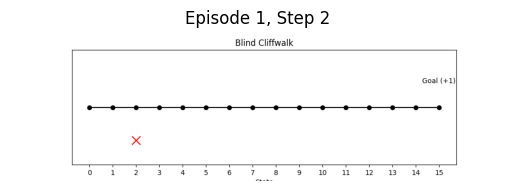

Random score 0.0


In [155]:
random_policy = RandomPolicy(blind_cliffwalk);
show_policy(blind_cliffwalk, random_policy, n_episodes=1, max_steps=200);

random_score = evaluate(blind_cliffwalk, random_policy, episodes=100);
print("Random score", random_score);

Blind Cliffwalk makes **rewarding experience difficult to discover**. The agent must choose the correct action at every state to complete the chain, a single mistake ends the episode with no reward. Most exploratory episodes therefore contain only zero-reward transitions. This scarcity makes **effective reuse especially important**. Once a successful transition is collected, uniform replay may revisit it only occasionally among many other experiences. If it produces a large TD error, PER can sample it more frequently. As learning changes the value estimates, earlier transitions can also acquire larger errors, potentially helping information about the final reward propagate backwards through the chain.

In [198]:
acrobot = gymnasium.make("Acrobot-v1", render_mode="rgb_array")

In [209]:
ddqn_acrobot_results = experiment(
    name="ddqn_acrobot",
    env=acrobot,
    algorithm=dqn,
    max_episodes=300,

    # Repeat across seeds; greedy evaluation is deterministic here.
    seeds=(12, 34, 56, 78, 90),
    evaluation_episodes=1,
    smoothing_window=25,

    # Network architecture and learning parameters.
    hidden_sizes=(128, 64),
    learning_rate=0.0001,
    gamma=0.99,
    batch_size=64,

    # Start learning after collecting a small initial memory.
    memory_size=20_000,
    memory_start_size=1_000,
    target_update_steps=250,

    # Reduce exploration over training transitions, not episodes.
    epsilon_max=1.0,
    epsilon_min=0.01,
    epsilon_decay_steps=5000,

    # Double DQN targets with uniform replay.
    optimization_step=optimize_ddqn
)

Episode 300, score -71.00
Episode 300, score -88.00
Episode 300, score -80.00
Episode 300, score -63.00
Episode 300, score -92.00


In [211]:
per_acrobot_results = experiment(
    name="per_acrobot",
    env=acrobot,
    algorithm=per,
    max_episodes=300,

    # Keep the same seeds and evaluation settings.
    seeds=(12, 34, 56, 78, 90),
    evaluation_episodes=1,
    smoothing_window=25,

    # Keep the architecture and learning parameters unchanged.
    hidden_sizes=(128, 64),
    learning_rate=0.0001,
    gamma=0.99,
    batch_size=64,

    # Keep memory capacity and target synchronization unchanged.
    memory_size=20_000,
    memory_start_size=1_000,
    target_update_steps=250,

    # Use the same exploration schedule.
    epsilon_max=1.0,
    epsilon_min=0.01,
    epsilon_decay_steps=5000,

    # Importance-weighted Double DQN updates with prioritized replay.
    optimization_step=optimize_per,
    alpha=0.6,
    beta=0.4,
    priority_epsilon=0.01,
)

Episode 300, score -68.00
Episode 300, score -105.0
Episode 300, score -67.00
Episode 300, score -96.00
Episode 300, score -84.00


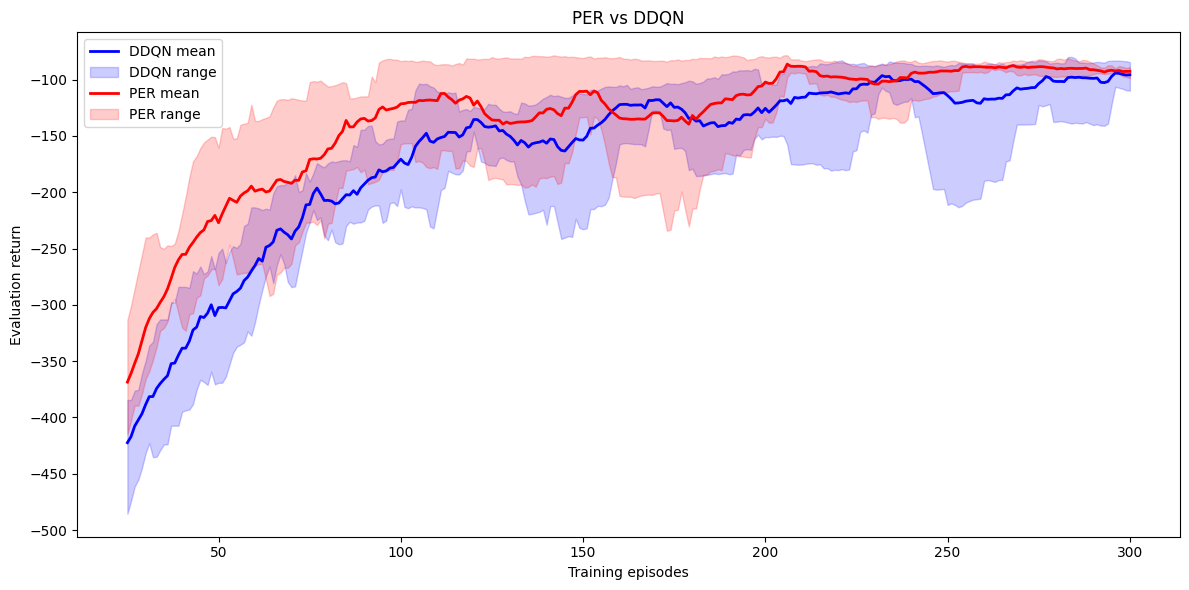

In [212]:
plot_comparison(
    ddqn_acrobot_results,
    per_acrobot_results,
    first_label="DDQN",
    second_label="PER",
    first_color="blue",
    second_color="red",
)

### Dueling Architecture

The improvements introduced so far have mainly made deep Q-learning look more like supervised learning. Replay memory makes the data less correlated, and the target network makes the labels more stable. These changes are crucial, but they do not change the way the Q-network represents values. The [**dueling architecture**](./papers/(2016)%20-%20Dueling%20Network%20Architectures%20for%20Deep%20Reinforcement%20Learning.pdf) is different: it modifies the network itself. Its goal is to exploit a useful structure in the way the value functions relate to one another. The state-value function measures how good it is to be in a state:

$\displaystyle v_\pi(s)=\mathbb{E}_\pi[G_t \mid S_t=s]$

The action-value function measures how good it is to take a specific action in that state:

$\displaystyle q_\pi(s,a)=\mathbb{E}_\pi[G_t \mid S_t=s,A_t=a]$

We can introduce the **advantage function** to measure how much better or worse an action is compared with the value of the state itself:

$\displaystyle a_\pi(s,a)=q_\pi(s,a)-v_\pi(s)$

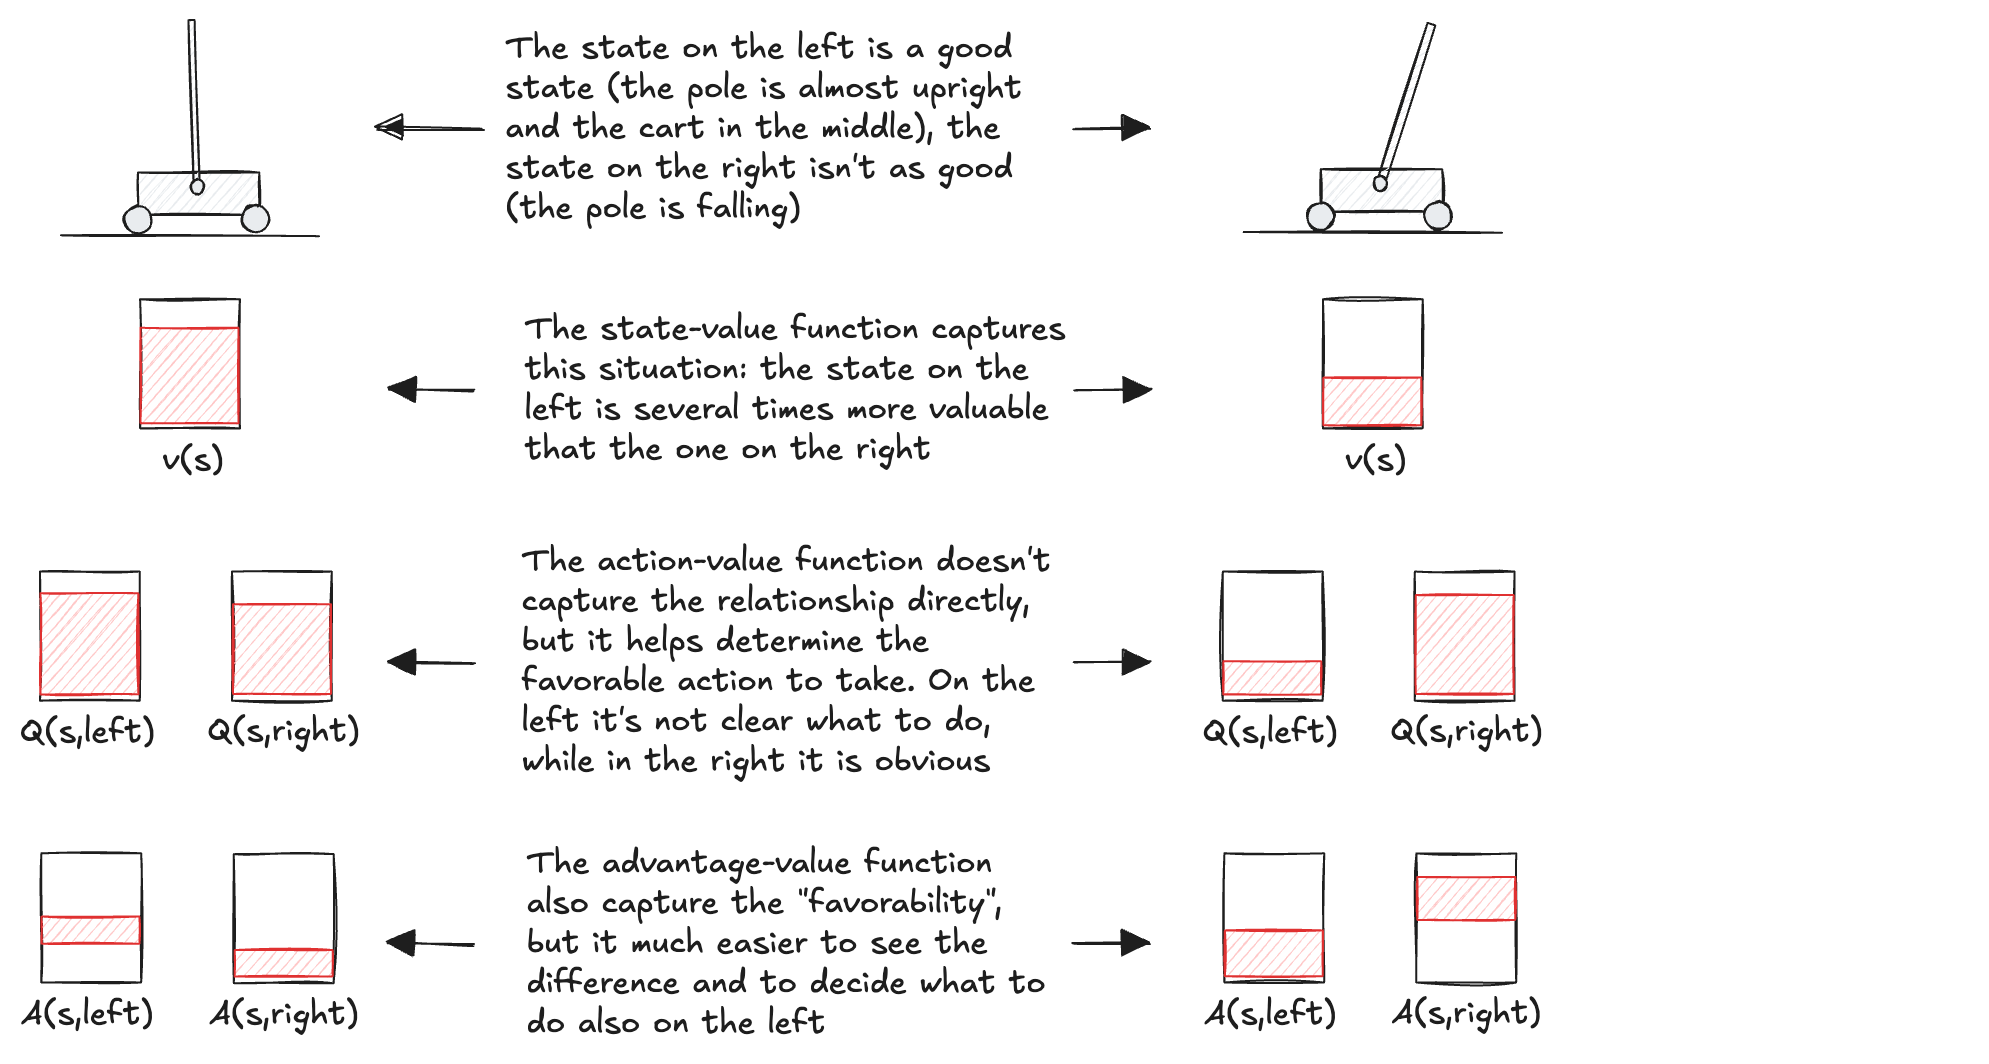


Equivalently, the action-value function can be decomposed as:

$\displaystyle q_\pi(s,a)=v_\pi(s)+a_\pi(s,a)$

Intuitively, the state-value function captures what is common to all actions in a state, while the advantage function captures the relative preference among actions. This distinction is useful because, in many states, the value of the state is much easier to estimate than the exact value of every action. For example, in Cart-Pole, a state where the pole is almost upright is generally good, regardless of whether the best action is slightly left or slightly right. Conversely, a state where the pole is already falling is less valuable overall, even if one action is still better than the other. A standard Q-network must learn a separate value for each action directly. This can be inefficient, because part of what it learns is shared across actions. The dueling architecture makes this shared structure explicit:

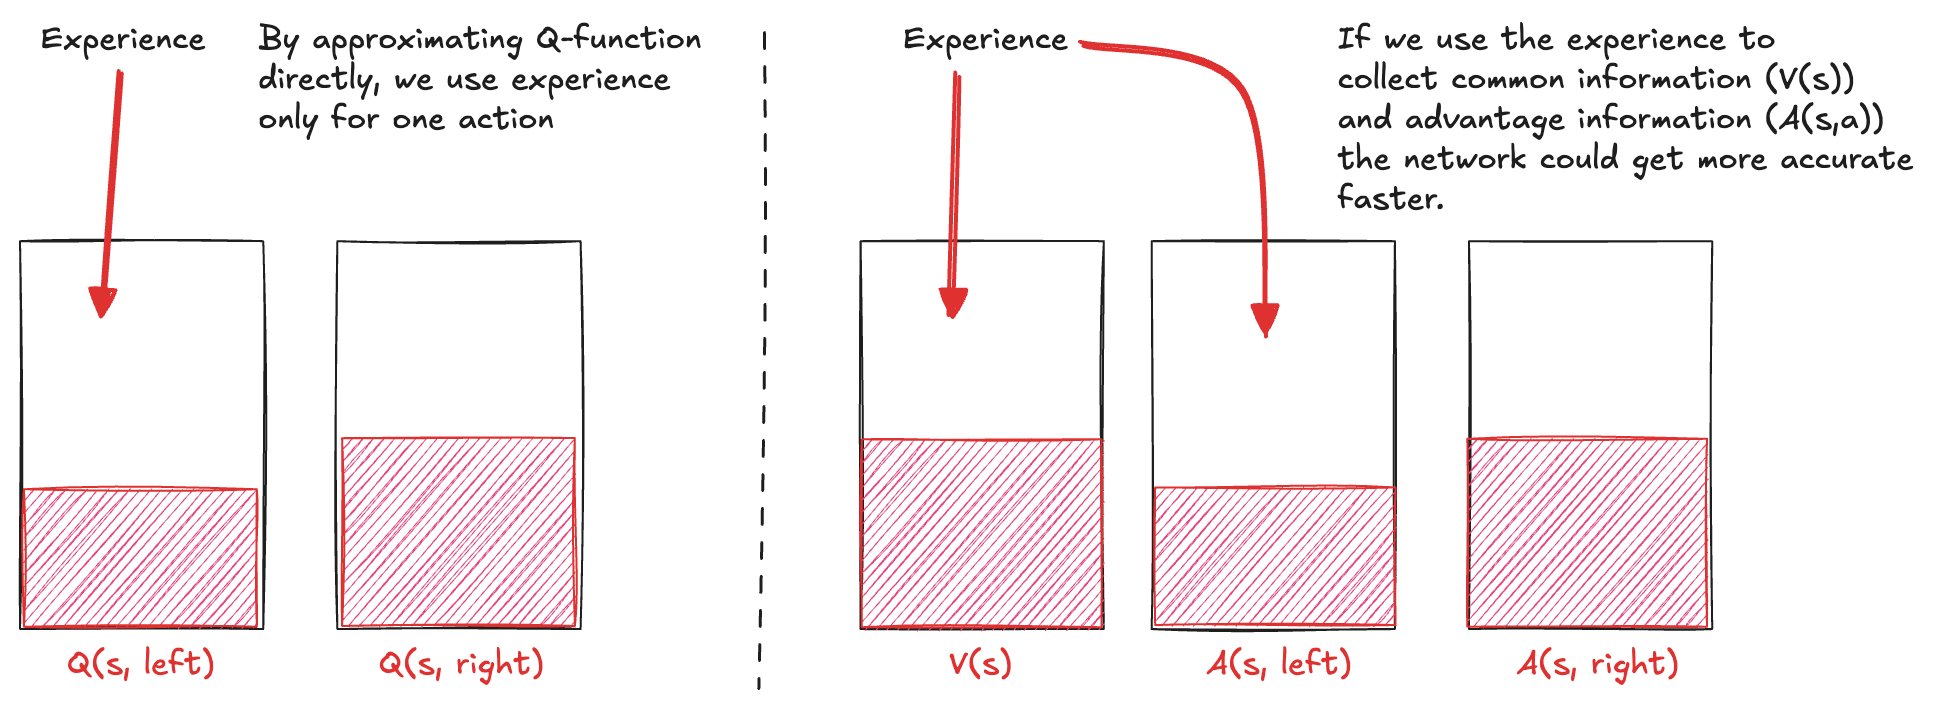


The [**Dueling Network Architecture**](./papers/2016%20-%20Dueling%20Network%20Architectures%20for%20Deep%20Reinforcement%20Learning.pdf) uses one shared feature extractor followed by two separate heads:

- a **value head**, which estimates the value of the state
- an **advantage head**, which estimates one advantage value for each action

The value head outputs a single number. The advantage head outputs a vector with one entry per action.

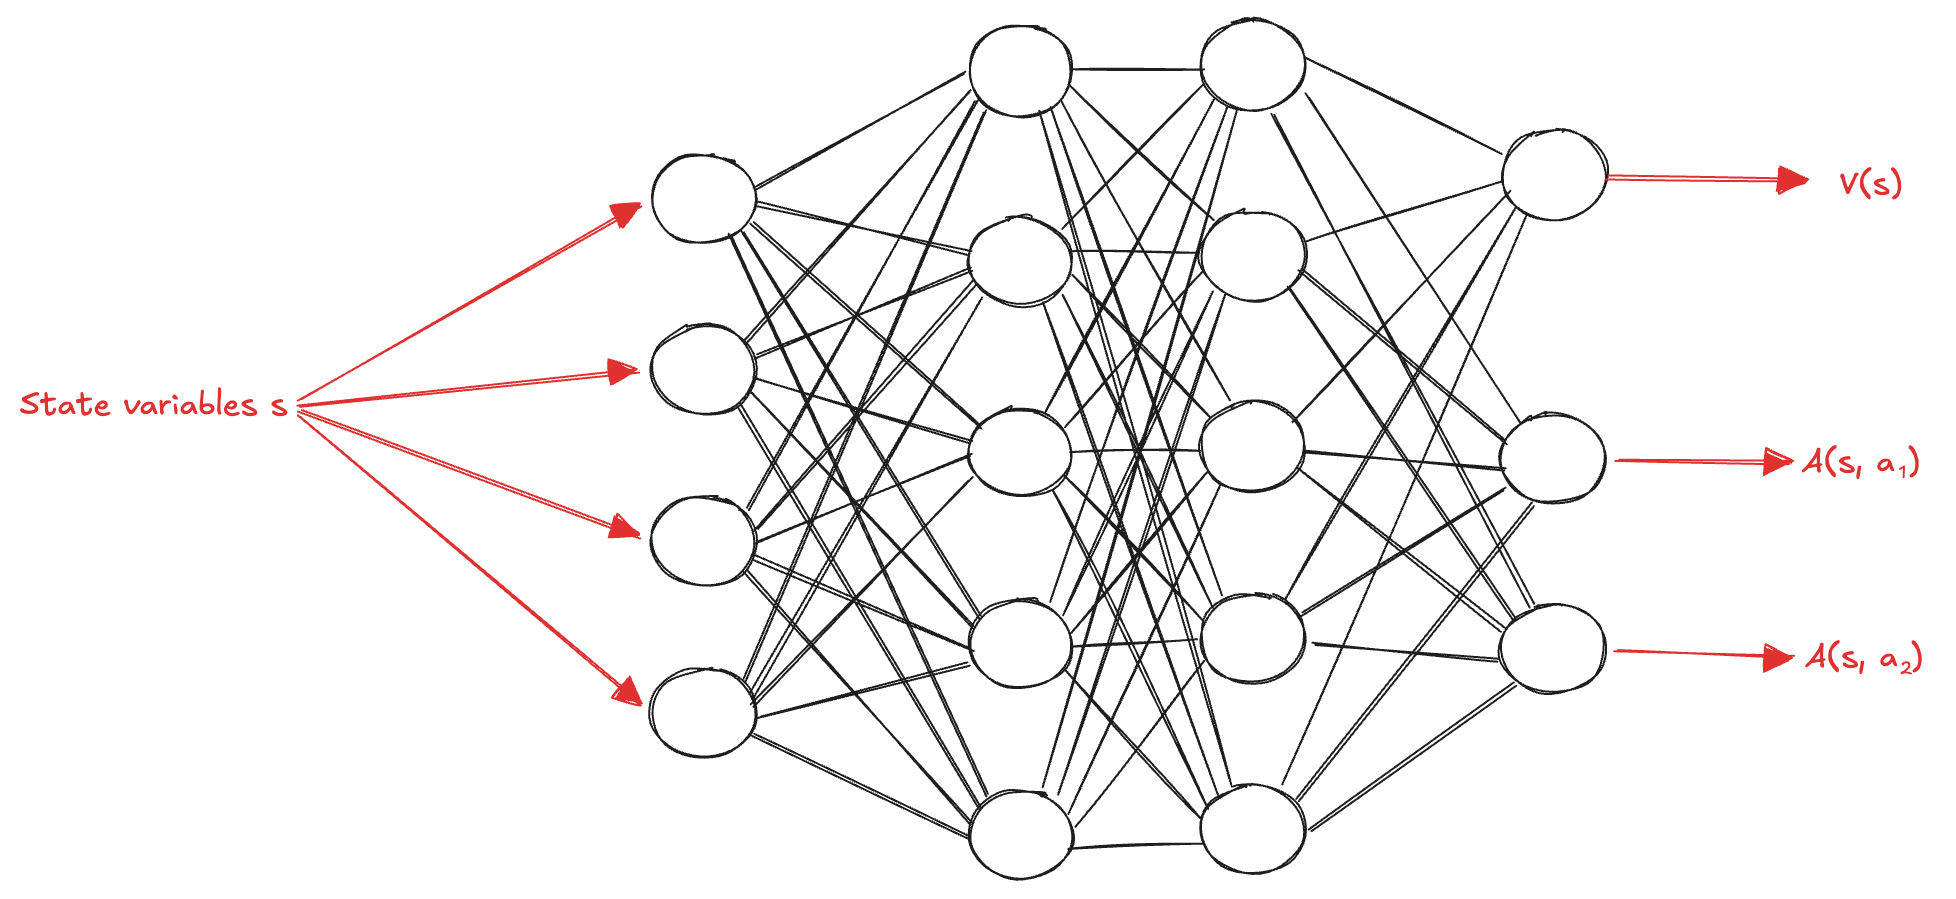


The two heads must then be combined to reconstruct the Q-values. A first idea would be to simply add them:

$\displaystyle Q(s,a;\theta,\theta_V,\theta_A)=V(s;\theta,\theta_V)+A(s,a;\theta,\theta_A)$

However, this decomposition is **not identifiable**. The training signal only constrains the sum. We could add a constant to the value estimate and subtract the same constant from all advantages, and the resulting Q-values would remain unchanged. As a result, nothing forces the value head to learn a true state value, or the advantage head to learn meaningful relative advantages. To remove this ambiguity, the advantages are centered before being added to the value. In practice, the dueling architecture subtracts the mean advantage:

$\displaystyle Q(s,a;\theta,\theta_V,\theta_A)=V(s;\theta,\theta_V)+\left(A(s,a;\theta,\theta_A)-\frac{1}{|\mathcal{A}|}\sum_{a'}A(s,a';\theta,\theta_A)\right)$

With this aggregation, the advantages have zero mean across actions. The value stream captures what is common to all actions in the state, while the advantage stream captures only the relative differences between actions. We implement this architecture by defining a custom PyTorch module. A simple "Sequential" model is no longer enough, because the network must split into two heads and then recombine their outputs with the centering operation.

In [ ]:
class DuelingNetwork(torch.nn.Module):
    def __init__(self, env, hidden_sizes=(512, 128)):
        super().__init__()
        sizes = (env.observation_space.shape[0], *hidden_sizes)
        layers = []
        for input_size, output_size in zip(sizes[:-1], sizes[1:]):
            layers.extend([
                torch.nn.Linear(input_size, output_size),
                torch.nn.ReLU(),
            ])
        self.shared = torch.nn.Sequential(*layers)
        self.value_head = torch.nn.Linear(sizes[-1], 1)
        self.advantage_head = torch.nn.Linear(sizes[-1], env.action_space.n)

    def forward(self, state):
        features = self.shared(state)
        value = self.value_head(features)
        advantages = self.advantage_head(features)
        advantages = advantages - advantages.mean(dim=-1, keepdim=True)
        return value + advantages

In [ ]:
def create_dueling_network(env, hidden_sizes=(512, 128)):
    return DuelingNetwork(env, hidden_sizes=hidden_sizes)

The dueling network is provided as an explicit **network factory**; the original factory is not replaced. Here we add the architecture to DDQN with prioritized replay on the MountainCar datasets of the previous section, keeping the same learning loop and hyperparameters. This comparison isolates the additional effect of the architecture within that combination:


In [ ]:
dueling_mountaincar = experiment(
    name="dueling_mountaincar",
    env=mountain_car,
    algorithm=batch_per,

    # Same collection and learning phases as the PER experiment.
    max_episodes=300,
    noise=0.65,
    memory_size=100_000,
    updates=30_000,
    evaluation_every=500,
    evaluation_episodes=10,
    smoothing_window=1,
    seeds=(12, 34, 56, 78, 90),

    # Same learning parameters and prioritized replay.
    hidden_sizes=(512, 128),
    learning_rate=0.0005,
    gamma=0.99,
    batch_size=32,
    target_update_steps=100,
    alpha=0.6,
    beta=0.4,
    priority_epsilon=0.01,

    # Only the network architecture changes.
    network_factory=create_dueling_network,
)


In [ ]:
plot_comparison(
    per_mountaincar,
    dueling_mountaincar,
    first_label="PER",
    second_label="Dueling DDQN + PER",
    first_color="black",
    second_color="green",
    x_axis="steps",
    x_label="Gradient updates",
    target=-110,
)


On MountainCar, Dueling DDQN with prioritized replay behaves much like PER with the standard network: the first successful greedy policy appears after the same 10 000–13 500 updates, and the final returns, between $-120$ and $-155$, overlap with those of PER, with a similarly wide range across seeds. This is expected. MountainCar has only three actions, so there is little shared structure to factor out: a standard network that learns three Q-values per state has almost nothing to gain from learning one state value plus three advantages. The shared state-value estimate helps most when many actions have similar effects, or when the value of being in a state is easier to learn than the value of each individual action. The dueling architecture is therefore more useful in environments with larger action spaces, such as the Atari games of the original paper, with up to 18 actions: there, many actions have little or no effect in a given state, and the network benefits from learning the state value once instead of relearning it separately for every action.


### Corridor

The dueling architecture changes how action values are represented. It separates a component shared across actions from the relative advantage of each action. This can be **useful when several actions have similar consequences**: learning about the state can benefit their value estimates together. To investigate this mechanism, we introduce the **Redundant Corridor** environment. The agent must follow a U-shaped passage from the starting cell to the goal. Its basic actions are **up, down, left, right and stay**. Movements into walls leave the agent in the same cell.

We create variants with 5, 10 and 20 actions by adding distinct action identifiers that all mean "stay". These additional actions have **identical transitions and rewards**: they increase the number of action values to estimate without introducing new behaviours:

Unlike Blind Cliffwalk, this environment provides feedback for intermediate progress. Moving forward along the corridor earns a small reward, backtracking incurs a penalty, and every step has a small cost. Reaching the goal gives an additional bonus. This reduces our dependence on discovering rare successful episodes. We will compare DQN with a standard network against DQN with a dueling network, keeping uniform replay and the other experimental settings unchanged. By varying the number of redundant actions, we can test whether the dueling representation becomes more beneficial as more actions share the same consequences.

## Applications and Limitations

XXXX

### Mountain Car


### Limitations

The improvements introduced in this chapter can be combined in several ways to obtain more stable and efficient agents. A well-known example is [**Rainbow**](./papers/2017%20-%20Rainbow%20-%20Combining%20Improvements%20in%20Deep%20Reinforcement%20Learning.pdf), which combines DDQN, prioritized replay, dueling networks, and three additional ideas: multi-step targets, distributional value learning, and noisy networks for exploration. Even with these refinements, important limitations remain.

First, value-based deep reinforcement learning is **highly sensitive to hyperparameters**. Small changes in the learning rate, exploration schedule, replay buffer size, target update frequency, or network architecture can have large effects on performance. In practice, many reasonable-looking configurations fail, and only a narrow range works well.

Second, these methods rely heavily on the assumption that the state is **Markovian**: the current observation must contain all the information needed to make good decisions. This matters especially for bootstrapping, because a bootstrapped target is only as reliable as the value estimate of the next state. If the state is incomplete or partially observable, the target can become misleading. Methods that bootstrap less, such as Monte Carlo methods, and the policy-based methods introduced in the next chapters, are often less sensitive to this issue.

Finally, DQN and its variants still contain the ingredients of the **deadly triad**: function approximation, bootstrapping, and off-policy learning. Each ingredient can be useful on its own, but their combination can make value estimates unstable or even divergent. Replay buffers, target networks, double learning, conservative learning rates, and careful tuning reduce these risks, but they do not remove them entirely.

For this reason, value-based deep reinforcement learning is powerful but delicate. It works best when the algorithmic refinements are used together with careful experimentation, diagnostics, and patience.